# IS5126 Group 6: toxicity classification and topic discovery on Reddit r/jobs

This notebook reproduces every table and figure in our video and slides from the saved models and shared data, in one run from top to bottom.

| Part | Question | Slides |
|---|---|---|
| **A. Topic discovery** | What do people discuss on r/jobs, and how did it change from January to October 2026? K-means topics, an LDA cross-check and a comparison with layoffs.fyi. | 9-24 |
| **B. Toxicity classification** | How well do logistic regression and a Bi-LSTM, trained on pooled external datasets, find toxic comments in r/jobs? | 25-34 |

**How to run.** Install the packages in `requirements.txt`, open this notebook from the folder that contains `functions/`, and run all cells. With the default settings it loads the saved models, so it takes a few minutes on a laptop CPU and trains nothing. The cell below the settings downloads any data or model file that is missing from our GitHub repository and checks each file against its SHA-256 hash, so the package itself can stay small. The saved outputs in this file are from the run the slides use.

**Retraining.** `RETRAIN = False` (default) loads the shipped models. `RETRAIN = True` refits them and writes the new models to `models_retrained/`, never over `models/`. It needs GloVe (`glove/glove.6B.100d.txt`, 347 MB, downloaded on request) and takes hours: the logistic regression search (30 trials x 5 folds, two models) and the two Bi-LSTM searches (30 trials x 5 folds each) dominate. Results from a retrain differ slightly from the slides.

**Not included.** Collecting and pooling the training datasets, and the Reddit collection scripts, are outside this notebook. The pooled train and validation splits and the r/jobs sample are read as shared files; the scripts that produced them stay in the repository.

**Randomness.** All seeds are fixed (42 unless stated). Differences between machines come from floating-point order, not from the code.

## 0. Settings

In [ ]:
RETRAIN = False          # False: load the saved models in models/.  True: refit and save to models_retrained/ (hours)
DOWNLOAD_MISSING = True  # fetch files that are missing locally from the GitHub repository (checked by hash)
OVERWRITE_CHANGED = False  # True: also replace local files whose hash differs (never done by default, so local edits are safe)
FETCH_PARTS = {'A', 'B'} # 'A' topic files, 'B' toxicity files: fetch only the part you want to run

# settings used when RETRAIN is True (the values behind the shipped models)
RETRAIN_SETTINGS = {
    'lr_search': {'n_iter': 30, 'n_initial_points': 10, 'selection': 'stable'},
    'lstm_search': {'n_iter': 30, 'n_initial_points': 10, 'objective': 'pr_auc', 'selection': 'stable'},
    'lstm_cv': {'n_splits': 5, 'epochs': 5, 'batch_size': 64, 'n_jobs': -1},
    'kmeans': {'k': 18, 'pca_components': 100, 'n_init': 30},
    'lda': {'k': 10, 'max_iter': 200},
}
SEED = 42

## 1. Initialization: find the project folder and fetch missing files
The notebook works from the folder that holds `functions/`. Every file it reads is listed below with its SHA-256 hash and size. A file that is missing or has a different hash is downloaded from the repository at a fixed release (`REPO_REF`), so a later push cannot change what is fetched. This cell uses only the Python standard library.

In [ ]:
import hashlib, os, sys, urllib.error, urllib.parse, urllib.request
from pathlib import Path

REPO_URL = os.environ.get('MAIN_ANALYSIS_BASE_URL', 'https://raw.githubusercontent.com/muffinMonday/IS5126_grp6_final_project')
REPO_REF = 'main'  # set to the submission tag when the package is built

# the project folder is the nearest folder, from here upward, that holds functions/
here = Path.cwd().resolve()
ROOT = next((p for p in (here, *here.parents) if (p / 'functions' / 'preprocessing.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the project folder: the one that contains functions/.')
sys.path.insert(0, str(ROOT))

FILES = {  # path: (sha256 of the stored file, bytes, part)  -- generated by make_files_table.py
    'dataset/layoffs/layoffs.csv': ('3e2df7c77ec8a2e0818587709ce1a088178cd866d288cdf0bc3b0826a6757add', 811913, 'A'),
    'dataset/monthly_Topics/comment_topics.csv': ('43c4622c030311ca833e65d5714b31605122d9558d71bf6a102631b01773eb79', 1173354, 'A'),
    'dataset/monthly_Topics/comments_clean.csv': ('62111327682df76d2d44899c0f28cceddbe51b3800d871d684cdf29b34ea1fc3', 9054268, 'A'),
    'dataset/monthly_Topics/kmeans/bundle_manifest.json': ('935883b55be07011c7dff9d6b36a810c253b5598dc5cf07b7e84aa6938cbc176', 11301, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/monthly_coverage.csv': ('e61f3f9a4a286316ee38d09f736c4a9f27937d0ff4fa01ac57c9626e4cef9ba8', 1135, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/pca_dimension_comparison_20261029/comparison.csv': ('eb67a3e6c4bba385a6ac89c8dc12aa08c53821040ece42743773671a9f7dae50', 10317, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/pca_dimension_comparison_20261029/comparison_manifest.json': ('01cabd0e044ff6abc6a0d6ab593fe34d3e31f553d8726eb48274e0a6d06a3f54', 463, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/pca_dimension_comparison_20261029/pca_variance.csv': ('f5c33eb96b27445b7eb26f68d2169fe30f7a735bbf126e115ac7f09d24186dd1', 11569, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/sampling_manifest.json': ('96820a886a6d7fafe122b3915468b3be5ec999296623a26c161629ebc47bda9c', 2040, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/boundary_diagnostics.csv': ('55c32be5203f5351d7d30ab27f20b54fd681fac9ac116493e14965f8003f35ee', 733, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/comment_topics.csv': ('10bd31d6f387cb4a8889ac529b8c37f349633406856a7307b1edff4fa05a5e79', 623916, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/common_space_quality.csv': ('fdebe529f661a9a980e8afdd6ad30ae094ed9e5bfe9ceaf4ec1162e38c5fcc39', 90, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/excluded_from_modelling.csv': ('aa5b821471bcf645f405a212e1d91b8fb0cfbc8da01cda3ef7e25fe93403a763', 7222, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/initialization_stability.csv': ('879d43cd508dc46f9feae097d70badd6bcccc80ba7b015607def776e9bb026a1', 113, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/k_selection.csv': ('4c6cf4763672d32e8de77bd9207e090407018fc96bd7a5982da238d45cb45957', 900, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/model_comparison.csv': ('d2f5d1acfafd5fde080c372d497811bda15735412e3f794f636cb7e4f2ebef69', 413, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/monthly_assignment_coverage.csv': ('0b8262d0f292678dd7c1146be5d190d343e9f7ad4c34f31d42a0d0a55c872947', 282, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/monthly_topic_trends.csv': ('7ab03cc4768d53ff47ff7bb2fc115b1d15f8be0319c9966ff88375b59e81d154', 13030, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/pca_comparison.csv': ('35287649a9b557be686cb1cdc69d9d1db78a1fa7ef77f23d2dff01416aa3cb66', 135, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/pca_variance.csv': ('7dd3d09cb4bb7f3f0ef6f400915255218aa240c260486ed866976874ef678d67', 2873, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/representative_comments.csv': ('dd7d78f49575602429a49e453f15afa0f683ca42a9e29765cec2e7d4b3b6c44d', 47846, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/run_parameters.json': ('b5f0a29ff69a1b650527497377d4f681c1994eb00b32d4b2343d4098986cca41', 10450, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/tfidf_vocabulary.csv': ('957d963f7f8895aa4d0c6abb9804cd509ce8326aed5892d87a9fff0b603d211e', 195773, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/topic_profiles.csv': ('9c84082882dd466acb624b8acc2b5e40a3a394f66df74d215ca9158771176737', 4683, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/verification.json': ('c133d8756c45d9b328b63dc582f85a537c84697e53d6004ac065f1c8b7e81c5d', 705, 'A'),
    'dataset/monthly_Topics/kmeans/prepared/topics_pca100_l2_20261029T105658930366Z/zero_tfidf_comments.csv': ('04637f8ecf41ca832ff16f3fd7d2d8dc0bc04cfd3a9dd6b841ab25636ff6e27b', 3512, 'A'),
    'dataset/monthly_Topics/lda/analysis/cluster_enrichment.csv': ('fc5d615a8fafa2a8458e0e9c6dd7df2e011701614f088d64d8040570afa47758', 194, 'A'),
    'dataset/monthly_Topics/lda/analysis/cluster_topic_weights_pct.csv': ('38da9fdf56a9af91be388f0025b53586f1750ef1abda670d97e78fb5981adf15', 3361, 'A'),
    'dataset/monthly_Topics/lda/analysis/example_topic_weights.csv': ('fb362c8f6cea27449ec380c3fa64637fd7b234c2a609e96fd7eaffb10625f69c', 120, 'A'),
    'dataset/monthly_Topics/lda/analysis/post_weight_sensitivity.csv': ('1e6f581c17014236686d88a1f73505bf75988899855232a32addeff43ef43738', 863, 'A'),
    'dataset/monthly_Topics/lda/analysis/quarterly_topic_changes.csv': ('28dfe45b4d4d7f4514beb8406fd8663f333369663c47143358e96d3f71af0c4f', 1016, 'A'),
    'dataset/monthly_Topics/lda/analysis/quarterly_topic_gap.csv': ('2013997ba1d21d54c345098522341078fe645c3065fd0f02bf2cc22e2b4244c9', 96, 'A'),
    'dataset/monthly_Topics/lda/analysis/random_seed_sensitivity.csv': ('e2914c607bcfc84b647f2376c8259ce580076d87e02d93d523dd761b16b0d9c2', 639, 'A'),
    'dataset/monthly_Topics/lda/analysis/top3_posts_by_topic_month.csv': ('1a3eaeb7de2822c020f13ea14688e1fa582f63cc357c00e0aa087d8c2557d126', 12436, 'A'),
    'dataset/monthly_Topics/lda/analysis/top3_removed_monthly.csv': ('d7ec80a931b534593e67329a9f10e3d76cc470b1c1df36511e6c24c00195ccce', 3755, 'A'),
    'dataset/monthly_Topics/lda/analysis/topic_composition.csv': ('6782775038f68feca7ff332a84967ae51aa4495138dddc22c6c8dd5d26fcb1db', 1084, 'A'),
    'dataset/monthly_Topics/lda/kmeans_lda_mix.csv': ('cf9c55d214b637802a4c7aaae2607d0f3851438ade44707e95b68fd138a1ef3d', 4781, 'A'),
    'dataset/monthly_Topics/lda/lda_comment_topics.csv': ('8165d76b6a88e51364bb83c4a8842b43c838e3e7ea2a4bd297112e76d358dc75', 2444757, 'A'),
    'dataset/monthly_Topics/lda/lda_monthly_shares.csv': ('f41c51ebacca2765a27f9ec8bf786da32419e9d50d44f9348af83979a2821560', 5000, 'A'),
    'dataset/monthly_Topics/lda/lda_run.json': ('ffd6b4c22ed405e0912fb5a165a78b433f7af67c755dc76d7e77dacbf8ea83cf', 1373, 'A'),
    'dataset/monthly_Topics/lda/lda_topic_profiles.csv': ('172c4847f34f546f772bc7d96475f080cd63ace726876d3aaea7b796bf74314e', 1995, 'A'),
    'dataset/monthly_Topics/lda/lda_trend_summary.csv': ('be3bb540adb51f4b107a104133a3b2ebb13dc34c8aada62a895e0b38a17e18d3', 1347, 'A'),
    'dataset/monthly_Topics/topic_profiles.csv': ('67c1f6e44f47f3c0ae63bd9912ff3bd840276a270fb7c08e4b885536dda993e5', 11612, 'A'),
    'dataset/reddit/layoff_mentions/analysis/monthly_layoff_context.csv': ('557b02737976fdf5090d344dd8b3cc0743533be6251ad3e76d0a64675307572c', 1275, 'A'),
    'dataset/reddit/layoff_mentions/analysis/quarterly_event_size.csv': ('0ffe66a1efc614688a68e322015b0caa4f703e14e706d48e756a74d7723cc616', 290, 'A'),
    'dataset/reddit/layoff_mentions/analysis/quarterly_layoff_context.csv': ('c7970efb49dab70f5e4a69fa6f35dc9ca1d430fb67a6c8d523d48aca76c49893', 394, 'A'),
    'dataset/reddit/layoff_mentions/analysis/same_month_correlations.csv': ('c2e97d2205b75023ea23a9ebe6c531e57833941e9182788ad85e13f30aab3ba3', 142, 'A'),
    'dataset/reddit/layoff_mentions/comparison_correlations.csv': ('5c1cca7f27194592407705dc6b0e94560646648cb4b91fe2b20a61f091d661a9', 1201, 'A'),
    'dataset/reddit/layoff_mentions/comparison_monthly.csv': ('98efce337f1c8012aed017f29d7fb4b098f505e734126609996f507c989f2bd8', 999, 'A'),
    'dataset/reddit/layoff_mentions/monthly_counts.csv': ('a94a5b60430dc4fe39e48dfa7cc969786814c05dbe7896e99872d15fe7bc4615', 510, 'A'),
    'dataset/reddit/layoff_mentions/run.json': ('d9f4fd2f35be451f4517e641328e2a634858d9aad1b16a568e4a964a225aa14f', 641, 'A'),
    'dataset/reddit/layoff_mentions/sample_vs_archive.csv': ('ee1b474ea8c011c5f6ee0dca6c524487c75dd892b6711ff297d2f2c0dfb78c01', 842, 'A'),
    'models/topics_kmeans/manifest.json': ('677c59dd31ccfc2977b7c2d79b207c9a39181a921e59c4fb90d747c36afeafa6', 952, 'A'),
    'models/topics_kmeans/topic_pipeline.joblib': ('6be0804458701fc1d1dce6684fb30e9dbd7c167a2e8af359cb8ceadce5e548ef', 3901861, 'A'),
    'models/topics_lda/lda_models.joblib': ('0971cc247a01d8d8492daa2fbc4929c7281442cc18ffff04904d6901e8a9f938', 2681601, 'A'),
    'models/topics_lda/manifest.json': ('1d042c98e976d6fa2f313444cc310e74ef07d200a7fcc85e5b359c0fb16223ec', 1568, 'A'),
    'dataset/pooled/manifest.json': ('43c97ed0c8b59cf09909c4e995f09c8311567857b15ad99bc8efc8e6ded3a98c', 2936, 'B'),
    'dataset/pooled/pooled_train.csv': ('6e92786f9cc81eb4e6deec6d20b5f28ec29fb7f1b5998a0e1788792f7b31a115', 11857283, 'B'),
    'dataset/pooled/pooled_val.csv': ('369043588c599221ab32fd648593c0c9bebac73d5508c4fa7a03f5880fa78ba6', 2866030, 'B'),
    'dataset/reddit/collection_manifest.json': ('6ebb35449f2a357838b89bc9dafab060baebb4a2da8ea7275dde064d80d0d564', 4362, 'B'),
    'dataset/reddit/test_100_labeled.csv': ('f95cb52b69956328e5d59bc0801e060fdd07f3c2a695346a8c6d545855abff49', 76191, 'B'),
    'models/baselines/baselines_manifest.json': ('0ebf429f4d50d96f23208d52082dfd8a32cd40650190a2e06cab18f43472dc2e', 1412, 'B'),
    'models/baselines/lr_tuning_cv.csv': ('66a52749d261fb1db8d49caed97458f23acbbeecc3c4c21ff82384ea3e25b2df', 11473, 'B'),
    'models/baselines/lr_tuning_validation.csv': ('e1b20a4a2a9f2073d0f47ce128ff2f91d698d26eadf5b749e69a601eb66043ea', 1917, 'B'),
    'models/baselines/tfidf_logreg.joblib': ('959f1c080da19c12ee84e9f0ba5be44831cae8cdcf895ea89e99a81560dd3f4f', 2358116, 'B'),
    'models/baselines/tfidf_logreg_balanced.joblib': ('97859b1fee41bf24b9df700fd8d9805135573036603eea0aac02751b924724c6', 1999588, 'B'),
    'models/bayes_search_pooled_balanced/best_kfold/final_model.keras': ('f01677eec78593d4afb1acce0ed659769d7f48347465a1988256579b55a93960', 25737936, 'B'),
    'models/bayes_search_pooled_balanced/best_kfold/state.pkl': ('b60807cede9cf986c66c2359303f5d947854e0da32f82ab71049af88e02b47da', 373452, 'B'),
    'models/bayes_search_pooled_balanced/search_state.pkl': ('7ee2b25c6b9e0ff13abdc98568761a35b484c67cfdd55cd5ca0065f76baa6a6a', 13805, 'B'),
    'models/bayes_search_pooled_unweighted/best_kfold/final_model.keras': ('8af13599461d54588094413735c97785ea421c05b229aafada8934b8c8548d7a', 25033846, 'B'),
    'models/bayes_search_pooled_unweighted/best_kfold/state.pkl': ('9fea5074093053c9df012e72f42fbcc2322d0e84d169de27dda98b4eb212a166', 373442, 'B'),
    'models/bayes_search_pooled_unweighted/search_state.pkl': ('e7436c7b83a8666761cb8cb319c331200fc5a0ac1a371a6f22b4183a1dffbecc', 13795, 'B'),
    'models/tokenizer/settings.json': ('f0748730fe3d818f5a4644a9c0ec5f00ef6d2588c867c870a1ff67030e5e4c28', 206, 'B'),
    'models/tokenizer/tokenizer.json': ('d39478fdbf1a7f47492c0059c61fc400cb0ff0ffc5cfd462957c8b639c9ff9c6', 4146768, 'B'),
}

TEXT_SUFFIXES = {'.csv', '.json'}

def _sha(data):
    return hashlib.sha256(data).hexdigest()

def file_ok(path, expected):
    # a file is fine if its bytes hash as expected; text files may also differ only in CRLF vs LF line endings
    if not path.is_file():
        return False
    data = path.read_bytes()
    if _sha(data) == expected:
        return True
    return path.suffix in TEXT_SUFFIXES and _sha(data.replace(b'\r\n', b'\n')) == expected

def fetch(relative, expected, attempts=2):
    url = f"{REPO_URL}/{REPO_REF}/{urllib.parse.quote(relative)}"
    target = ROOT / relative
    target.parent.mkdir(parents=True, exist_ok=True)
    partial = target.with_name(target.name + '.part')
    for attempt in range(attempts):
        try:
            with urllib.request.urlopen(url, timeout=120) as response:
                data = response.read()
            if _sha(data) != expected:
                raise ValueError('downloaded file does not match its recorded hash')
            partial.write_bytes(data)
            os.replace(partial, target)
            return
        except (urllib.error.URLError, OSError, ValueError) as error:
            last = error
    raise RuntimeError(f'could not fetch {relative} from {url}: {last}')

wanted = {name: meta for name, meta in FILES.items() if meta[2] in FETCH_PARTS}
absent = {name: meta for name, meta in wanted.items() if not (ROOT / name).is_file()}
changed = {name: meta for name, meta in wanted.items() if name not in absent and not file_ok(ROOT / name, meta[0])}
print(f'Project folder: {ROOT}')
print(f'{len(wanted) - len(absent) - len(changed)} of {len(wanted)} required files present and verified (parts {sorted(FETCH_PARTS)})')
if changed:
    # a local file that differs from the repository is left alone: it may be a deliberate local edit
    print(f'WARNING: {len(changed)} local files differ from the recorded version and are kept as they are: ' + ', '.join(changed))
    print('         Set OVERWRITE_CHANGED = True to replace them with the repository version.')
to_fetch = {**absent, **(changed if OVERWRITE_CHANGED else {})}
if to_fetch:
    megabytes = sum(meta[1] for meta in to_fetch.values()) / 1e6
    print(f'{len(to_fetch)} files to download ({megabytes:.1f} MB): ' + ', '.join(list(to_fetch)[:3]) + (' ...' if len(to_fetch) > 3 else ''))
    if not DOWNLOAD_MISSING:
        raise FileNotFoundError('Required files are missing. Set DOWNLOAD_MISSING = True, or copy the repository folders into the project folder.')
    print(f'Downloading from {REPO_URL}/{REPO_REF} ...')
    for name, meta in to_fetch.items():
        fetch(name, meta[0])
    print('Done: every downloaded file matches its recorded hash.')

Project folder: C:\Users\cy071\OneDrive - National University of Singapore\IS5126\Project Template
74 of 74 required files present and verified (parts ['A', 'B'])


### Libraries and shared code
`functions/` holds the project code used by the cells below. The notebook only calls it; the logic of each step is documented in those modules and covered by `tests/`.

In [ ]:
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

warnings.filterwarnings('ignore', message='.*was passed an input with a mask attached.*')  # harmless Keras LSTM warning
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')  # saved models were fitted on other scikit-learn builds
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)

MODEL_DIR = ROOT / ('models_retrained' if RETRAIN else 'models')  # where this run reads and writes models
DATA_DIR = ROOT / 'dataset'
np.random.seed(SEED)

print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}')
print(f'RETRAIN = {RETRAIN}: models are read from {MODEL_DIR.relative_to(ROOT)}/')

Python 3.14.7 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2
RETRAIN = False: models are read from models/


# Part A. Topic discovery on r/jobs (slides 9-24)

What does the community discuss, and how did attention shift between January and October 2026? The topic corpus is 10,000 r/jobs comments, 1,000 per month (October ends on 28 October and is partial). Three analyses use it:

| Section | Method | Slides |
|---|---|---|
| A1-A3 | **K-means**: TF-IDF (10,000 terms), PCA to 100 dimensions, row L2 normalisation, 18 clusters | 11-15 |
| A4 | **LDA**: 10 topics from raw word counts, each comment a mix of topics | 17-22 |
| A5 | **Layoffs**: how often comments mention layoffs, against the layoffs.fyi record | 23 |

The K-means pipeline is the frozen model in `models/topics_kmeans/` (its SHA-256 hash is checked before use); cluster names come from a human review and apply only to that model. The LDA tables are read from the shipped exports, and the LDA model in `models/topics_lda/` is a refit that is not the one behind the slides (see its `manifest.json`), so LDA numbers always come from the exports. Everything the cells compute is written to `outputs/`, never into `dataset/`, and A6 compares the regenerated tables with the shipped ones.

In [ ]:
import hashlib
import importlib.metadata
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits

from functions.preprocessing import cleanup_text
from functions.topics import (
    verified_coverage, vectorize_comments, reduce_topics, topic_coordinates, original_space_diagnostics, evaluate_clusters,
    topic_profiles as build_topic_profiles, initialization_stability,
)
from functions.topic_reporting import topic_trend_diagnostics, topic_period_sensitivity

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

TOPICS_DIR = DATA_DIR / 'monthly_Topics'
OUT_DIR = ROOT / 'outputs'                                        # everything the cells compute is written here
RUN_DIR = TOPICS_DIR / 'kmeans' / 'prepared'                      # K-means bundle: sampling record and frozen run
CORPUS_FILE = TOPICS_DIR / 'comments_clean.csv'                   # the topic corpus (one copy, shared with LDA and layoffs)
PCA_COMPARISON_DIR = RUN_DIR / 'pca_dimension_comparison_20261029'
SAVED_MODEL_DIR = RUN_DIR / 'topics_pca100_l2_20261029T105658930366Z'   # recorded diagnostics of the frozen run
KMEANS_PIPELINE = ROOT / 'models' / 'topics_kmeans' / 'topic_pipeline.joblib'  # the frozen model (always the shipped one)
OUT_DIR.mkdir(exist_ok=True)

YEAR, PER_MONTH, MIN_WORDS = 2026, 1000, 3
RUN_TOPIC_MODEL = True
SELECTED_K = 18
REUSE_SAVED_MODEL = True       # analyses always use the frozen model; RETRAIN refits a separate copy in A7
TOPIC_LABELS = {}
PCA_COMPONENTS = 100
PCA_L2_NORMALIZE = True
BASELINE_COMPONENTS = 50
K_VALUES = [8, 10, 12, 15, 18, 20]
SILHOUETTE_SAMPLE = 1500
N_INIT = 30
THREADS = 2
EXCLUDE_MODERATION_NOTICES = True
# English stop words include no/not/nor; retain "off" for "laid off"; the fillers dominated early PCA runs
EXTRA_TOPIC_STOP_WORDS = [
    'just', 'like', 'really', 'actually', 'probably', 'maybe', 'yes', 'yeah',
    'lol', 'sounds', 'know', 'think', 'people', 'good', 'need', 'want',
    'going', 'got', 'did', 'does', 'said', 'say', 'don', 've', 'll', 'gif', 'giphy',
]
KEEP_TOPIC_WORDS = ['off']
features_ready = False
final_ready = False
figures = {}

# the review (names, evidence) applies to this model only: bind it to the frozen weights, assignments and input
REVIEW_BINDING = {
    'pipeline': '6be0804458701fc1d1dce6684fb30e9dbd7c167a2e8af359cb8ceadce5e548ef',
    'assignments': '10bd31d6f387cb4a8889ac529b8c37f349633406856a7307b1edff4fa05a5e79',
    'input': '62111327682df76d2d44899c0f28cceddbe51b3800d871d684cdf29b34ea1fc3',
}
saved_bundle = None
review_binding_verified = False
CASE_STUDY_IDS = [2, 5, 8, 9, 11, 17]
HEATMAP_HIDDEN_CLUSTERS = [7]  # hides the plotted row only; all denominators still include C7

In [ ]:
TOPIC_REVIEW = [{'cluster': 0,
  'topic_label': 'Work time and leave (mixed)',
  'semantic_confidence': 'Low-medium',
  'employment_topic': True,
  'interpretation_limit': 'Time includes leave, wasted time and life stages; not solely leave policy.',
  'trend_judgment': 'Fluctuates without a clear sustained direction.'},
 {'cluster': 1,
  'topic_label': 'Work arrangements and job advice (broad)',
  'semantic_confidence': 'Low',
  'employment_topic': True,
  'interpretation_limit': 'Generic work wording mixes industry advice, visas and employment verification.',
  'trend_judgment': 'No clear trend; equal-post weighting changes the direction.'},
 {'cluster': 2,
  'topic_label': 'Manager/HR communication and resignation notice',
  'semantic_confidence': 'Medium',
  'employment_topic': True,
  'interpretation_limit': 'Communication, recruitment management, leave and resignation notice are mixed; '
                          'not solely conflict.',
  'trend_judgment': 'Strongest upward display candidate, with mixed semantics and descriptive interpretation '
                    'only.'},
 {'cluster': 3,
  'topic_label': 'Past experiences and elapsed years',
  'semantic_confidence': 'Low',
  'employment_topic': False,
  'interpretation_limit': 'Years ago is an expression pattern, not necessarily qualification requirements.',
  'trend_judgment': 'No clear topic trend; elapsed-year wording is not a qualifications indicator.'},
 {'cluster': 4,
  'topic_label': 'Job choices and labour-market discussion (broad)',
  'semantic_confidence': 'Low-medium',
  'employment_topic': True,
  'interpretation_limit': 'Generic job wording is not a direct labour-market deterioration indicator.',
  'trend_judgment': 'No clear sustained trend; broad job discussion is not an economic indicator.'},
 {'cluster': 5,
  'topic_label': 'Pay, pay cuts and payment issues',
  'semantic_confidence': 'Medium-high',
  'employment_topic': True,
  'interpretation_limit': 'Payment-related meaning is relatively consistent but includes rent, scams and '
                          'general payments.',
  'trend_judgment': 'Broadly stable; useful as a stable-topic reference.'},
 {'cluster': 6,
  'topic_label': 'Company evaluations and employment processes',
  'semantic_confidence': 'Low-medium',
  'employment_topic': True,
  'interpretation_limit': 'Company wording mixes checks, hiring, evaluations and advice.',
  'trend_judgment': 'Fluctuates without a clear sustained direction.'},
 {'cluster': 7,
  'topic_label': 'General advice and responses (mixed)',
  'semantic_confidence': 'Low',
  'employment_topic': False,
  'interpretation_limit': 'Large residual cluster; do not treat it as one employment topic.',
  'trend_judgment': 'Large and broadly stable; unsuitable for a single-topic interpretation.'},
 {'cluster': 8,
  'topic_label': 'Job applications and opportunities',
  'semantic_confidence': 'Medium',
  'employment_topic': True,
  'interpretation_limit': 'Applications, job sources and opportunities coexist with generic jobs wording.',
  'trend_judgment': 'Declining signal with intermediate rebounds; moderate-to-weak evidence.'},
 {'cluster': 9,
  'topic_label': 'Job changes, new jobs and onboarding',
  'semantic_confidence': 'High',
  'employment_topic': True,
  'interpretation_limit': 'New work, resignation timing, offers and job-search advice are relatively '
                          'coherent.',
  'trend_judgment': 'Lower April-May and higher August-September; not a continuous increase.'},
 {'cluster': 10,
  'topic_label': 'Judgment and agreement wording',
  'semantic_confidence': 'Low',
  'employment_topic': False,
  'interpretation_limit': 'Right is not an independent employment topic.',
  'trend_judgment': 'Discourse pattern; do not interpret as an employment-topic trend.'},
 {'cluster': 11,
  'topic_label': 'Experience, education and qualifications',
  'semantic_confidence': 'Medium-high',
  'employment_topic': True,
  'interpretation_limit': 'Experience and education are relatively coherent, with some generic '
                          'personal-experience references.',
  'trend_judgment': 'Declining signal, with a June rebound and model-boundary uncertainty.'},
 {'cluster': 12,
  'topic_label': 'Miscellaneous short and emotional replies',
  'semantic_confidence': 'Low',
  'employment_topic': False,
  'interpretation_limit': 'A few terms such as labour, income or Trump do not establish a political-economic '
                          'theme.',
  'trend_judgment': 'Residual replies; do not impose a single-topic interpretation.'},
 {'cluster': 13,
  'topic_label': 'Questions and requests for advice',
  'semantic_confidence': 'Low',
  'employment_topic': False,
  'interpretation_limit': 'Ask groups questions across contexts; not solely interview questions.',
  'trend_judgment': 'Some numerical increase, but mainly a question/answer expression pattern.'},
 {'cluster': 14,
  'topic_label': 'Workdays, hours and schedules (mixed)',
  'semantic_confidence': 'Low-medium',
  'employment_topic': True,
  'interpretation_limit': 'Day also refers to account age, cake day and reminders; not a pure work-hours '
                          'cluster.',
  'trend_judgment': 'Some numerical increase, but mixed day meanings prevent a clear topic claim.'},
 {'cluster': 15,
  'topic_label': 'Responses about the original poster',
  'semantic_confidence': 'High (discourse form)',
  'employment_topic': False,
  'interpretation_limit': 'OP indicates discourse form, not an employment theme.',
  'trend_judgment': 'Original-poster response form; not an employment-topic trend.'},
 {'cluster': 16,
  'topic_label': 'Work and life choices (broad)',
  'semantic_confidence': 'Low-medium',
  'employment_topic': True,
  'interpretation_limit': 'Life includes outlook, health and career choices; not solely work-life balance.',
  'trend_judgment': 'Numerical decline with mixed semantics; do not infer improving life pressure.'},
 {'cluster': 17,
  'topic_label': 'AI use, generated content and job substitution',
  'semantic_confidence': 'High',
  'employment_topic': True,
  'interpretation_limit': 'Content identification, AI use and substitution coexist; not solely unemployment '
                          'anxiety.',
  'trend_judgment': 'Higher February-May and generally lower after June; not a continuous decline from '
                    'January.'}]

CASE_STUDY_CONTEXT = {2: {'semantic_evidence': 'Manager, HR and notice terms support communication/resignation discussion; '
                          'generic tell wording keeps the rating at Medium.',
     'project_relevance': 'Hiring, management communication and resignation are relevant to workplace '
                          'interaction and later topic-level toxicity analysis.',
     'robustness_assessment': 'Comment shares: 4.98% to 6.85%; equal-post shares: 5.95% to 7.23%. Direction '
                              'agrees, but mixed meaning does not establish increasing conflict.'},
 5: {'semantic_evidence': 'Pay, pay cut, bills and rate support salary/payment discussion, with some general '
                          'payments.',
     'project_relevance': 'Compensation and economic-pressure discussion provide an employment-related '
                          'stable reference.',
     'robustness_assessment': 'Comment shares: 3.18% to 3.17%; equal-post: 3.00% to 3.03%. Both are near '
                              'stable; some months have larger single-post influence.'},
 8: {'semantic_evidence': 'Apply, applying, jobs and resume support applications and opportunities, with '
                          'generic jobs references.',
     'project_relevance': 'Applications, opportunities and recruitment channels directly concern the core '
                          'r/jobs discussion.',
     'robustness_assessment': 'Comment shares: 4.84% to 3.82%; equal-post: 5.49% to 3.90%. Decline agrees, '
                              'with intermediate rebounds.'},
 9: {'semantic_evidence': 'New job, start and quit support job changes, onboarding and waiting for a '
                          'confirmed offer before resigning.',
     'project_relevance': 'Work transitions and joining a new employer are relevant; discussion shares are '
                          'not actual switching counts.',
     'robustness_assessment': 'Lower April-May and higher August-September; quarterly change from 2.95% to '
                              '3.30% is small, and peak month depends on post weighting.'},
 11: {'semantic_evidence': 'Experience, degree and entry level support qualifications, education and '
                           'resumes, with some generic experience references.',
      'project_relevance': 'Experience requirements and education/job fit are relevant; do not infer '
                           'employers lowered qualification requirements.',
      'robustness_assessment': 'Comment shares: 3.86% to 2.79%; equal-post: 4.30% to 3.57%. Decline agrees, '
                               'with a June rebound rather than a continuous fall.'},
 17: {'semantic_evidence': 'AI, generated, replace and slop support tools, content identification and '
                           'substitution, not solely job-loss anxiety.',
      'project_relevance': 'AI use and labour substitution matter, but AI-content identification prevents '
                           'use as a direct layoffs indicator.',
      'robustness_assessment': 'Comment shares: 2.57% to 1.55%; equal-post: 2.45% to 1.68%. Both show '
                               'phase-dependent decline; only about 10-33 comments per month.'}}

## A1. The topic corpus (slide 11)
The sampling record (`sampling_manifest.json`) fixes 20 time strata per month with 50 comments each, seed 42. The corpus file is checked against it, and the coverage table is checked against its recorded hash. Fixed monthly quotas describe the composition of the sample, not total subreddit activity, and October is partial.

In [ ]:
manifest = json.loads((RUN_DIR / 'sampling_manifest.json').read_text(encoding='utf-8'))
coverage = verified_coverage(RUN_DIR / 'monthly_coverage.csv', manifest['sha256']['monthly_coverage.csv'])
if hashlib.sha256(CORPUS_FILE.read_bytes()).hexdigest() != manifest['sha256']['comments_clean.csv']:
    raise ValueError('The topic corpus differs from the sampling record.')
if (manifest['year'], manifest['target_per_month'], manifest['seed'], manifest['min_words']) != (YEAR, PER_MONTH, 42, MIN_WORDS):
    raise ValueError('The sampling record uses different parameters.')
corpus = pd.read_csv(CORPUS_FILE, dtype={'comment_id': str}, keep_default_na=False)
corpus['created_at'] = pd.to_datetime(corpus['created_at'], utc=True)
assert corpus['comment_id'].is_unique and corpus['text'].str.strip().ne('').all()
assert corpus.groupby('month').size().eq(PER_MONTH).all() and len(corpus) == manifest['counts']['selected']
assert corpus.groupby(['month', 'sampling_stratum']).size().eq(PER_MONTH // 20).all()
assert coverage['selected'].eq(PER_MONTH).all()
print('Run cutoff:', manifest['as_of_utc'], '| corpus:', f'{len(corpus):,}', 'comments in', corpus['month'].nunique(), 'months')
display(coverage)
display(pd.DataFrame([manifest['counts']]))

Run cutoff: 2026-10-28T07:10:54+00:00 | corpus: 10,000 comments in 10 months


,month,window_start_utc,window_end_utc,partial_month,target,eligible_pool,selected,shortfall,source_window_complete,status
0,2026-01,2026-01-01T00:00:00+00:00,2026-02-01T00:00:00+00:00,False,1000,1819,1000,0,False,target_met
1,2026-02,2026-02-01T00:00:00+00:00,2026-03-01T00:00:00+00:00,False,1000,1760,1000,0,False,target_met
2,2026-03,2026-03-01T00:00:00+00:00,2026-04-01T00:00:00+00:00,False,1000,1799,1000,0,False,target_met
3,2026-04,2026-04-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,False,1000,1779,1000,0,False,target_met
4,2026-05,2026-05-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,False,1000,1754,1000,0,False,target_met
5,2026-06,2026-06-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,False,1000,1739,1000,0,False,target_met
6,2026-07,2026-07-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,False,1000,1752,1000,0,False,target_met
7,2026-08,2026-08-01T00:00:00+00:00,2026-09-01T00:00:00+00:00,False,1000,1806,1000,0,False,target_met
8,2026-09,2026-09-01T00:00:00+00:00,2026-10-01T00:00:00+00:00,False,1000,1730,1000,0,False,target_met
9,2026-10,2026-10-01T00:00:00+00:00,2026-10-28T07:10:54+00:00,True,1000,1828,1000,0,False,target_met


,raw,eligible,excluded,selected
0,20213,17766,2447,10000


## A2. K-means: the frozen model (slides 12-13)
The pipeline in `models/topics_kmeans/` was fitted once on the 9,770 assignable comments: TF-IDF with 10,000 word features, centered PCA to 100 components, row L2 normalisation, then K-means with 18 clusters (k-means++, 30 initialisations, seed 42). Reuse mode checks the hash of the model, its assignments and its input before anything is reported, and refits nothing. The cells below report its diagnostics, name the clusters from a documented review and then follow six topics through the year.

### K-means: model binding and topic names

The hash of the frozen model, of its assignments and of its input are checked against a review binding. If any differs, the notebook stops instead of carrying topic names over to another model. The reporting cells then use the frozen model without refitting TF-IDF, PCA or K-means.

The next cell embeds 18 English topic suggestions with interpretation confidence and limitations. These are **assistant interpretations pending human validation**, not gold labels or model-generated confidence scores. The names are bound to this model and are never transferred to a refit by cluster number. A refit (`RETRAIN = True`, section A7) is saved separately and gets no names.

### K-means: Sample coverage and comment length

These charts describe the collected sample. Fixed monthly quotas support topic-share comparisons, not estimates of subreddit volume. Missing months are not filled with zero activity; partial months remain explicit.
Inspect concentration within posts because comments from the same thread are dependent. Later equal-post sensitivity checks address part of that dependence.

,n_comments,n_posts
month,,
2026-01,1000,351
2026-02,1000,373
2026-03,1000,385
2026-04,1000,382
2026-05,1000,388
2026-06,1000,373
2026-07,1000,396
2026-08,1000,351
2026-09,1000,340


,n_comments
link_id,
t3_1w3heo8,57
t3_1vjzzk6,49
t3_1qcxp53,44
t3_1sroszd,42
t3_1sok3ki,39
t3_1wnpjsu,38
t3_1x5t65n,38
t3_1x9dnk5,38
t3_1s6gk6m,37


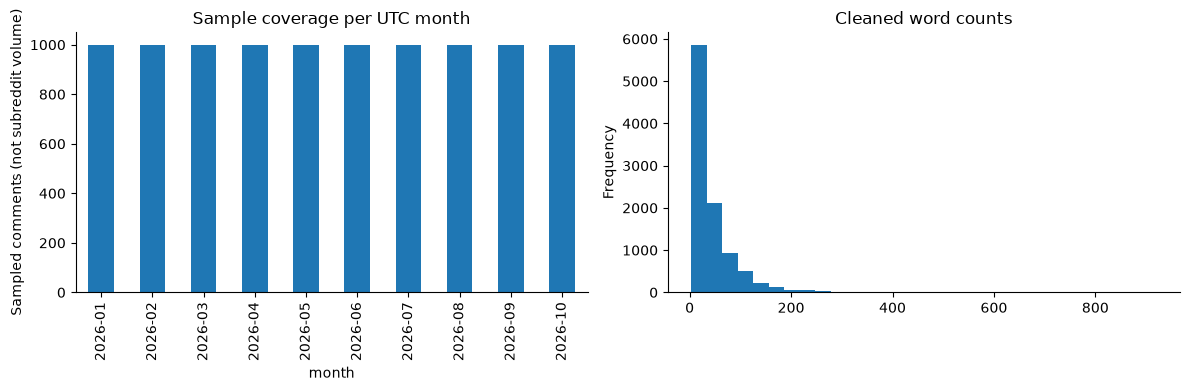

In [ ]:
if not corpus.empty:
    monthly_summary = corpus.groupby('month').agg(n_comments=('comment_id', 'size'),
                                                  n_posts=('link_id', 'nunique'))
    display(monthly_summary)
    display(corpus['link_id'].replace('', np.nan).value_counts().head(10).rename('n_comments').to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    monthly_summary['n_comments'].plot.bar(ax=axes[0], title='Sample coverage per UTC month')
    axes[0].set_ylabel('Sampled comments (not subreddit volume)')
    corpus['word_count'].plot.hist(bins=30, ax=axes[1], title='Cleaned word counts')
    fig.tight_layout()
    plt.show()

In [ ]:
saved_bundle = None
review_binding_verified = False
if RUN_TOPIC_MODEL and not corpus.empty and REUSE_SAVED_MODEL:
    source_paths = {
        'pipeline': KMEANS_PIPELINE,
        'assignments': SAVED_MODEL_DIR / 'comment_topics.csv',
        'input': CORPUS_FILE,
    }
    for kind, target in source_paths.items():
        if not target.exists() or hashlib.sha256(target.read_bytes()).hexdigest() != REVIEW_BINDING[kind]:
            raise ValueError(f'Reviewed-model binding failed: {kind}. Do not transfer topic names to another model.')
    saved_parameters = json.loads((SAVED_MODEL_DIR / 'run_parameters.json').read_text(encoding='utf-8'))
    for name, expected in saved_parameters['output_sha256'].items():
        if hashlib.sha256((SAVED_MODEL_DIR / name).read_bytes()).hexdigest() != expected:
            raise ValueError(f'Saved result changed: {name}')
    if (PCA_COMPONENTS, PCA_L2_NORMALIZE, SELECTED_K, N_INIT) != (
        saved_parameters['pca_components'], saved_parameters['pca_l2_normalize'],
        saved_parameters['selected_k'], saved_parameters['n_init'],
    ):
        raise ValueError('Reuse mode requires the frozen configuration. Disable reuse to fit a new, unnamed model.')
    saved_bundle = joblib.load(source_paths['pipeline'])
    saved_assignments = pd.read_csv(source_paths['assignments'], dtype={'comment_id': str}, keep_default_na=False)
    review_binding_verified = True
    print('Verified frozen PCA100 / k=18 model. Reporting only; no PCA or K-means refit.')

Verified frozen PCA100 / k=18 model. Reporting only; no PCA or K-means refit.


### K-means: TF-IDF features

The retrospective corpus uses a shared unigram/bigram vocabulary: `min_df=3`, `max_df=0.90`, at most 10,000 features, sublinear TF and row L2 normalization. Only `text_topic` enters the model.

Early exploratory fits were dominated by moderation templates and conversational fillers. The documented topic-only configuration therefore excludes explicit moderation-notice phrase combinations and adds listed conversational stop words, retaining `off` for `laid off`.
This does not change raw text or toxicity-classifier preprocessing and does not claim to identify every bot.

IDs excluded as `moderation_notice` or `zero_tfidf` remain in exports. Reuse mode loads the frozen vectorizer and original diagnostics without refitting it.

In [ ]:
if RUN_TOPIC_MODEL and not corpus.empty:
    if saved_bundle is not None:
        print('Frozen TF-IDF reused without fitting; diagnostics below describe the original feature run.')
        vectorizer = saved_bundle['vectorizer']
        assigned_ids = saved_assignments.loc[saved_assignments.topic_status.eq('assigned'), 'comment_id']
        frozen_frame = corpus.loc[corpus.comment_id.isin(assigned_ids)].reset_index(drop=True).copy()
        excluded_frame = saved_assignments.loc[~saved_assignments.topic_status.eq('assigned'),
                                                 ['comment_id', 'month', 'topic_status']].rename(columns={'topic_status': 'reason'})
        feature_result = {
            'vectorizer': vectorizer, 'X': vectorizer.transform(frozen_frame.text_topic),
            'model_df': frozen_frame, 'excluded': excluded_frame,
            'stop_words': saved_parameters['tfidf']['stop_words'],
            'diagnostics': saved_parameters['feature_diagnostics'],
            'top_terms': pd.DataFrame(),
        }
    else:
        feature_result = vectorize_comments(
            corpus, min_df=3, max_df=0.90, max_features=10000,
            extra_stop_words=EXTRA_TOPIC_STOP_WORDS, keep_words=KEEP_TOPIC_WORDS,
            exclude_moderation=EXCLUDE_MODERATION_NOTICES,
        )
    vectorizer = feature_result['vectorizer']
    X = feature_result['X']
    model_df = feature_result['model_df']
    feature_excluded = feature_result['excluded']
    stop_words = feature_result['stop_words']
    feature_diagnostics = feature_result['diagnostics']
    display(pd.DataFrame([feature_diagnostics]))
    display(feature_excluded.groupby('reason').size().rename('n_comments').to_frame())
    display(feature_result['top_terms'])
    assert len(model_df) + len(feature_excluded) == len(corpus)
    assert model_df['comment_id'].is_unique
    print('Sparse TF-IDF shape:', X.shape, '; no dense conversion')
else:
    print('No modelling requested or no corpus available.')

Frozen TF-IDF reused without fitting; diagnostics below describe the original feature run.


,input_comments,model_comments,moderation_notices,zero_vectors,vocabulary_size,nonzero_entries,density,sparse_megabytes,fit_seconds
0,10000,9770,106,124,10000,157126,0.001608,1.296092,0.827668


,n_comments
reason,
moderation_notice,106
zero_tfidf,124


""


Sparse TF-IDF shape: (9770, 10000) ; no dense conversion


### K-means: PCA dimension and projected-vector normalization

The selected dimension balances retained information and topic diagnostics; 90% is not a required threshold. True centered ARPACK PCA is used with `whiten=False`.
The corpus, vocabulary and cleaning remain fixed. Do not inflate retained variance by deleting difficult comments or features.

Keep the raw projection `Z_pca` for PCA variance and use the configured row normalization to produce clustering coordinates `Z`. Normalization changes the distance geometry and is not exactly spherical K-means.
Original TF-IDF cosine diagnostics use a fixed sample of 1,500 rows to provide a common reference across representations. Reuse mode transforms with the saved PCA and normalizer.

,configuration,components,retained_variance
0,First 50 components,50,0.087086
1,Selected dimension,100,0.144052


PCA shape (9770, 100); fit 0.00s; row L2 normalization: True


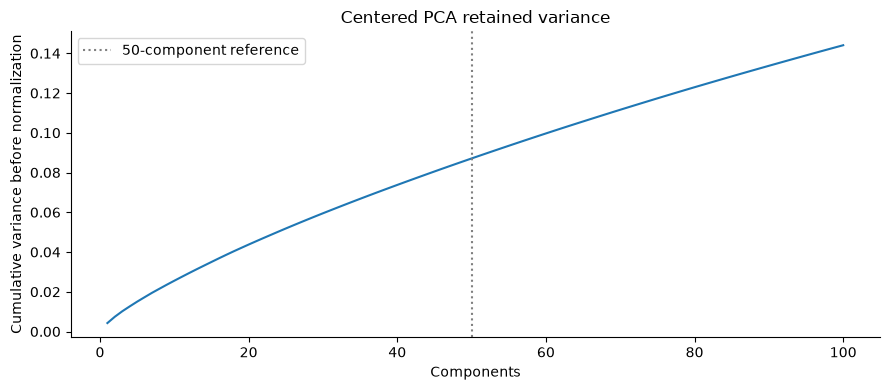

In [ ]:
features_ready = False
final_ready = False
if RUN_TOPIC_MODEL and not corpus.empty:
    component_count = min(PCA_COMPONENTS, min(X.shape) - 1)
    if saved_bundle is not None:
        pca = saved_bundle['pca']
        normalizer = saved_bundle['normalizer']
        Z_pca = pca.transform(X)
        Z = normalizer.transform(Z_pca) if normalizer is not None else Z_pca
        pca_variance = pd.read_csv(SAVED_MODEL_DIR / 'pca_variance.csv')
        pca_seconds = 0.0  # Reused here; original fit time is in the frozen run_parameters.json.
    else:
        pca, Z_pca, pca_variance, pca_seconds = reduce_topics(
            X, n_components=component_count, seed=SEED, threads=THREADS,
        )
        Z, normalizer = topic_coordinates(Z_pca, PCA_L2_NORMALIZE)
    actual_components = int(pca.n_components_)
    retained = float(pca_variance.cumulative_variance.iloc[-1])
    baseline_n = min(BASELINE_COMPONENTS, actual_components)
    pca_comparison = pd.DataFrame([
        {'configuration': f'First {baseline_n} components', 'components': baseline_n,
         'retained_variance': float(pca_variance.cumulative_variance.iloc[baseline_n - 1])},
        {'configuration': 'Selected dimension', 'components': actual_components,
         'retained_variance': retained},
    ])
    display(pca_comparison)
    print(f'PCA shape {Z_pca.shape}; fit {pca_seconds:.2f}s; row L2 normalization: {PCA_L2_NORMALIZE}')
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(pca_variance.component, pca_variance.cumulative_variance)
    ax.axvline(baseline_n, linestyle=':', color='grey', label='50-component reference')
    ax.set(xlabel='Components', ylabel='Cumulative variance before normalization', title='Centered PCA retained variance')
    ax.legend()
    fig.tight_layout()
    figures['pca_variance'] = fig
    plt.show()
    features_ready = True
else:
    print('No modelling requested or no prepared corpus available.')

### K-means: K diagnostics in the selected representation

Candidates share the same coordinates, K-means++ initialization, seed 42, 30 initializations and fixed silhouette subset. Reuse mode reads the frozen candidate table.
PCA-space inertia and silhouette across different dimensions or normalization settings are not direct quality rankings. Also examine original-space diagnostics, cluster sizes and representative text.

,k,inertia,silhouette,actual_clusters,smallest_cluster,smallest_cluster_share,largest_cluster_share,iterations,seconds,inertia_drop_fraction
0,8,8452.196289,0.046286,8,451,0.046162,0.452610,17,0.940730,NaN
1,10,8294.793945,0.053078,10,220,0.022518,0.425384,31,0.998998,0.018623
2,12,8149.263184,0.056537,12,215,0.022006,0.395087,20,1.160279,0.017545
3,15,7973.593750,0.061678,15,164,0.016786,0.340020,19,1.433847,0.021556
4,18,7791.762207,0.067524,18,167,0.017093,0.308393,84,1.602712,0.022804
5,20,7701.617676,0.070210,20,162,0.016581,0.274104,20,1.655275,0.011569


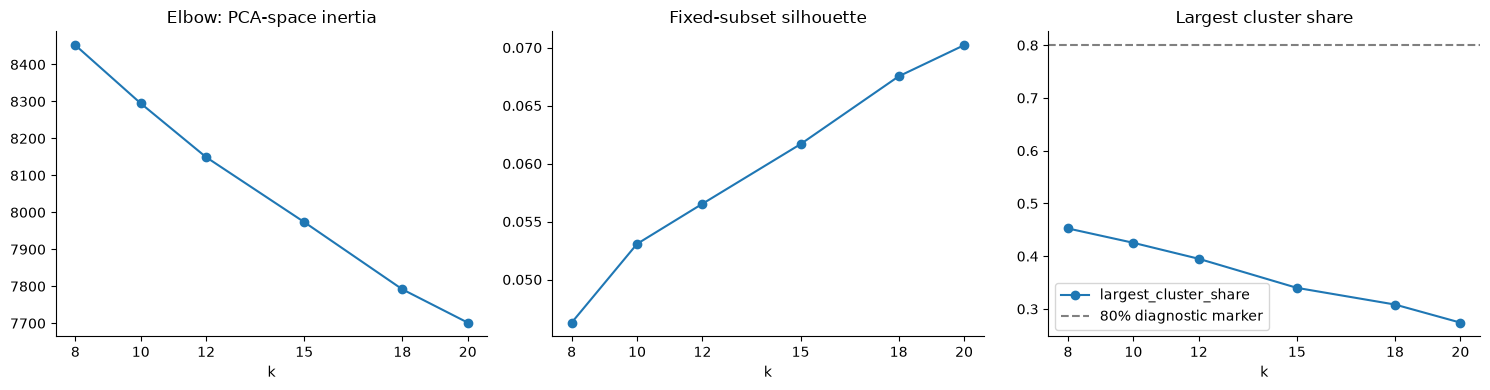

In [ ]:
if features_ready:
    if saved_bundle is not None:
        k_results = pd.read_csv(SAVED_MODEL_DIR / 'k_selection.csv')
        k_models = {SELECTED_K: saved_bundle['kmeans']}
        eval_indices = np.sort(np.random.default_rng(SEED).choice(
            len(Z), min(SILHOUETTE_SAMPLE, len(Z)), replace=False))
    else:
        k_results, k_models, eval_indices = evaluate_clusters(
            Z, ks=K_VALUES, seed=SEED, sample_size=SILHOUETTE_SAMPLE,
            n_init=N_INIT, threads=THREADS,
        )
    display(k_results)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    k_results.plot(x='k', y='inertia', marker='o', legend=False, ax=axes[0], title='Elbow: PCA-space inertia')
    k_results.plot(x='k', y='silhouette', marker='o', legend=False, ax=axes[1], title='Fixed-subset silhouette')
    k_results.plot(x='k', y='largest_cluster_share', marker='o', legend=False, ax=axes[2], title='Largest cluster share')
    axes[2].axhline(0.8, color='grey', linestyle='--', label='80% diagnostic marker')
    axes[2].legend()
    for ax in axes:
        ax.set_xticks(K_VALUES)
    fig.tight_layout()
    figures['k_selection'] = fig
    plt.show()

### K-means: Fit the final K-means model and check ambiguity and stability

In the frozen run, the final step was `KMeans(n_clusters=18, init='k-means++', n_init=30, random_state=42, max_iter=300, algorithm='lloyd').fit_predict(Z)`, where `Z` is the PCA projection after row L2 normalization. The cell below loads that model and predicts only, which preserves the reviewed assignments without fitting. Each label is attached to its `comment_id` row.

k = 18 comes from exploratory comparisons and text inspection.
Cluster balance does not establish semantic coherence. ARI across seeds 7 and 21 measures initialization sensitivity, not accuracy.
Original TF-IDF cosine silhouette and top-term Jaccard overlap are internal diagnostics, not human semantic validation. Relative nearest/second-nearest centroid margins flag ambiguity and are not probabilities.

In [ ]:
if features_ready:
    feasible = k_results.loc[
        k_results.silhouette.notna() & k_results.actual_clusters.eq(k_results.k)
        & k_results.largest_cluster_share.le(0.80)
        & k_results.smallest_cluster_share.ge(0.005)
    ]
    if feasible.empty:
        print('Warning: no candidate passed the exploratory cluster-size checks. Review before interpreting topics.')
        feasible = k_results.loc[k_results.silhouette.notna() & k_results.actual_clusters.eq(k_results.k)]
    if feasible.empty:
        raise ValueError('No non-degenerate k candidate is available.')
    recommended_k = int(feasible.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0].k)
    if SELECTED_K is None:
        SELECTED_K = recommended_k
        print('Provisional k in the new PCA space:', SELECTED_K, '; not a reviewed optimal solution')
    if SELECTED_K not in k_models:
        raise ValueError('SELECTED_K must be among the evaluated k values.')
    if saved_bundle is not None:
        final_model = saved_bundle['kmeans']
        cluster_labels = final_model.predict(Z)
        print('K-means mode: verified frozen model; no fitting.')
    else:
        final_model = KMeans(
            n_clusters=SELECTED_K,
            init='k-means++',
            n_init=N_INIT,
            random_state=SEED,
            max_iter=300,
            algorithm='lloyd',
        )
        with threadpool_limits(limits=THREADS):
            cluster_labels = final_model.fit_predict(Z)
        if not np.array_equal(cluster_labels, k_models[SELECTED_K].labels_):
            raise ValueError('Final K-means refit differs from its candidate; review diagnostics before reporting.')
        print(f'Fitted final K-means: k={SELECTED_K}, init=k-means++, n_init={N_INIT}, seed={SEED}')
    model_df['cluster'] = cluster_labels
    display(model_df[['comment_id', 'month', 'cluster']].head())
    if len(np.unique(final_model.labels_)) != SELECTED_K:
        raise ValueError('The requested k produced empty clusters; inspect diagnostics.')
    selected_diagnostics = k_results.loc[k_results.k.eq(SELECTED_K)].copy()
    display(selected_diagnostics)
    if saved_bundle is not None:
        expected_labels = pd.to_numeric(saved_assignments.set_index('comment_id').loc[model_df.comment_id, 'cluster']).to_numpy(dtype=int)
        if not np.array_equal(cluster_labels, expected_labels) or not np.array_equal(final_model.labels_, expected_labels):
            raise ValueError('Frozen assignments do not match these rows; topic names are not safe to apply.')
        stability = pd.read_csv(SAVED_MODEL_DIR / 'initialization_stability.csv')
    else:
        stability = initialization_stability(Z, final_model, threads=THREADS, n_init=N_INIT)
    display(stability)
    print('Mean initialization ARI:', stability.adjusted_rand_index.mean())
    common_space_quality = pd.DataFrame([original_space_diagnostics(
        X, eval_indices, final_model.labels_, vectorizer,
    )])
    display(common_space_quality)
    distances = final_model.transform(Z)
    nearest_two = np.sort(distances, axis=1)[:, :2]
    assignment_margin = (nearest_two[:, 1] - nearest_two[:, 0]) / np.maximum(nearest_two[:, 1], 1e-12)
    model_df['assignment_margin'] = assignment_margin
    print('Share with relative centroid margin < 0.10:', float((assignment_margin < 0.10).mean()))

    boundary_diagnostics = model_df.groupby(final_model.labels_).agg(
        n_comments=('comment_id', 'size'), mean_margin=('assignment_margin', 'mean'),
        low_margin_share=('assignment_margin', lambda values: (values < 0.10).mean()),
    ).rename_axis('cluster').reset_index()
    display(boundary_diagnostics)

K-means mode: verified frozen model; no fitting.


,comment_id,month,cluster
0,nx5me19,2026-01,4
1,nx5khtn,2026-01,0
2,nx5nft5,2026-01,10
3,nx5p460,2026-01,7
4,nx5giv5,2026-01,1


,k,inertia,silhouette,actual_clusters,smallest_cluster,smallest_cluster_share,largest_cluster_share,iterations,seconds,inertia_drop_fraction
4,18,7791.762207,0.067524,18,167,0.017093,0.308393,84,1.602712,0.022804


,seed,adjusted_rand_index,inertia
0,7,0.684919,7803.550781
1,21,0.598374,7801.943848


Mean initialization ARI: 0.6416465520490057


,tfidf_cosine_silhouette,mean_top_term_jaccard
0,0.008313,0.097917


Share with relative centroid margin < 0.10: 0.6482088024564995


,cluster,n_comments,mean_margin,low_margin_share
0,0,534,0.089959,0.672285
1,1,448,0.151997,0.491071
2,2,586,0.049056,0.907850
3,3,304,0.145490,0.457237
4,4,615,0.137856,0.556098
5,5,295,0.148626,0.450847
6,6,406,0.137856,0.497537
7,7,3013,0.050069,0.999668
8,8,415,0.123799,0.522892
9,9,269,0.156554,0.420074


### K-means: Comparison with the fixed-50 baseline

Local comparison folders preserve the dimension grid and optional domain-stop-word experiments. With identical features, 50/100/200/400 components retain approximately 8.71%/14.41%/22.87%/34.80% variance. More retained variance did not consistently improve topic separation.

The selected PCA100/L2/k=18 configuration provides a recognizable AI-related cluster and interpretable local pay and experience groups. Inspected k=20 alternatives included generic-word clusters. Stronger vocabulary filtering reduced initialization stability and was not selected.
This is exploratory selection, not performance on an independent test set. Dimension, normalization, k and initialization count changed together; the complete difference cannot be attributed to PCA dimension alone.

Mixed clusters remain and overall separation is weak. A cluster mentioning `off` is not automatically a layoff topic. Bound suggestions apply only to the verified model; new models retain unreviewed labels.

In [ ]:
model_comparison = pd.DataFrame()
if features_ready:
    current = {
        'configuration': 'Selected PCA + row L2', 'components': actual_components,
        'retained_variance': retained, 'k': SELECTED_K,
        'largest_cluster_share': float(selected_diagnostics.largest_cluster_share.iloc[0]),
        'pca_space_silhouette': float(selected_diagnostics.silhouette.iloc[0]),
        'tfidf_cosine_silhouette': float(common_space_quality.tfidf_cosine_silhouette.iloc[0]),
        'mean_initialization_ari': float(stability.adjusted_rand_index.mean()),
        'n_init': N_INIT,
    }
    rows = [current]
    baseline_dir = RUN_DIR / 'topics_20261029T034634149868Z'
    if review_binding_verified:
        cached_comparison = pd.read_csv(SAVED_MODEL_DIR / 'model_comparison.csv')
        historical = cached_comparison.loc[cached_comparison.components.eq(50)]
        if len(historical) != 1:
            raise ValueError('The verified comparison table must contain exactly one PCA50 baseline.')
        rows.insert(0, historical.iloc[0].to_dict())
        print('PCA50 baseline reused from its hash-verified reference table; no historical model loaded.')
    elif (baseline_dir / 'topic_pipeline.joblib').exists():
        previous = joblib.load(baseline_dir / 'topic_pipeline.joblib')
        previous_parameters = previous['parameters']
        expected_input = hashlib.sha256((CORPUS_FILE).read_bytes()).hexdigest()
        if previous_parameters['input_sha256'] != expected_input:
            raise ValueError('Baseline corpus changed; cannot compare.')
        if not np.array_equal(previous['vectorizer'].get_feature_names_out(), vectorizer.get_feature_names_out()):
            raise ValueError('Baseline vocabulary differs; common-space comparison needs alignment.')
        previous_Z = previous['pca'].transform(X)
        previous_labels = previous['kmeans'].predict(previous_Z)
        old_quality = original_space_diagnostics(X, eval_indices, previous_labels, vectorizer)
        old_stability = pd.read_csv(baseline_dir / 'initialization_stability.csv')
        rows.insert(0, {
            'configuration': 'Original PCA50, no row L2', 'components': 50,
            'retained_variance': previous_parameters['explained_variance'],
            'k': previous['kmeans'].n_clusters,
            'largest_cluster_share': float(pd.Series(previous_labels).value_counts(normalize=True).max()),
            'pca_space_silhouette': previous_parameters['selected_silhouette'],
            'tfidf_cosine_silhouette': old_quality['tfidf_cosine_silhouette'],
            'mean_initialization_ari': float(old_stability.adjusted_rand_index.mean()),
            'n_init': previous_parameters['n_init'],
        })
    model_comparison = pd.DataFrame(rows)
    display(model_comparison)
    print('PCA-space scores use different geometries. Common TF-IDF cosine scores use identical rows.')

PCA50 baseline reused from its hash-verified reference table; no historical model loaded.


,configuration,components,retained_variance,k,largest_cluster_share,pca_space_silhouette,tfidf_cosine_silhouette,mean_initialization_ari,n_init
0,"Original PCA50, no row L2",50,0.087086,11,0.547288,0.110256,0.006582,0.645208,10
1,Selected PCA + row L2,100,0.144052,18,0.308393,0.067524,0.008313,0.641647,30


PCA-space scores use different geometries. Common TF-IDF cosine scores use identical rows.


### K-means: Topic suggestions and six analysis cases

Names use original-space TF-IDF means, distinctive terms, five nearest-centroid and five random comments per cluster. Confidence is an assistant qualitative judgment, pending independent human validation, not model accuracy.

The six requested cases are **C2, C5, C8, C9, C11 and C17**. Interpret them using semantics, sample size, project relevance and robustness; do not upgrade their confidence labels for inclusion.
The cases include rising, falling, phase-dependent and stable discussion and are not independently validated "best topics".
All 18 clusters remain in assignments and exports. The heatmap hides only C7 after computing all shares. Names and case IDs apply only to the verified frozen model.

,cluster,topic_label,n_comments,share,semantic_confidence,employment_topic,focus_topic,trend_judgment,interpretation_limit
0,0,Work time and leave (mixed),534,0.054657,Low-medium,True,False,Fluctuates without a clear sustained direction.,"Time includes leave, wasted time and life stag..."
1,1,Work arrangements and job advice (broad),448,0.045855,Low,True,False,No clear trend; equal-post weighting changes t...,"Generic work wording mixes industry advice, vi..."
2,2,Manager/HR communication and resignation notice,586,0.059980,Medium,True,True,"Strongest upward display candidate, with mixed...","Communication, recruitment management, leave a..."
3,3,Past experiences and elapsed years,304,0.031116,Low,False,False,No clear topic trend; elapsed-year wording is ...,"Years ago is an expression pattern, not necess..."
4,4,Job choices and labour-market discussion (broad),615,0.062948,Low-medium,True,False,No clear sustained trend; broad job discussion...,Generic job wording is not a direct labour-mar...
5,5,"Pay, pay cuts and payment issues",295,0.030194,Medium-high,True,True,Broadly stable; useful as a stable-topic refer...,Payment-related meaning is relatively consiste...
6,6,Company evaluations and employment processes,406,0.041556,Low-medium,True,False,Fluctuates without a clear sustained direction.,"Company wording mixes checks, hiring, evaluati..."
7,7,General advice and responses (mixed),3013,0.308393,Low,False,False,Large and broadly stable; unsuitable for a sin...,Large residual cluster; do not treat it as one...
8,8,Job applications and opportunities,415,0.042477,Medium,True,True,Declining signal with intermediate rebounds; m...,"Applications, job sources and opportunities co..."
9,9,"Job changes, new jobs and onboarding",269,0.027533,High,True,True,Lower April-May and higher August-September; n...,"New work, resignation timing, offers and job-s..."


,comment_id,text,month,cluster,permalink,selection,topic_label,semantic_confidence,label_source,human_validated
0,o4qr8sw,Nice. Full time?,2026-02,0,https://www.reddit.com/r/jobs/comments/1r1n15u...,nearest,Work time and leave (mixed),Low-medium,assistant_suggested,False
1,ojmy799,Time wasted can't be bought.,2026-05,0,https://www.reddit.com/r/jobs/comments/1t22k9m...,nearest,Work time and leave (mixed),Low-medium,assistant_suggested,False
2,nxdgq8u,Be honest. People need time to decompress,2026-01,0,https://www.reddit.com/r/jobs/comments/1q2dyjb...,nearest,Work time and leave (mixed),Low-medium,assistant_suggested,False
3,p575pye,"Do share address, time for Taco Tuesday as & w...",2026-08,0,https://www.reddit.com/r/jobs/comments/zda6j5/...,nearest,Work time and leave (mixed),Low-medium,assistant_suggested,False
4,ocd8lrh,I’m going to take a portion of this time to st...,2026-03,0,https://www.reddit.com/r/jobs/comments/1s1pdo8...,nearest,Work time and leave (mixed),Low-medium,assistant_suggested,False
...,...,...,...,...,...,...,...,...,...,...
175,oyldo1h,"Not only that, women couldn't buy themselves a...",2026-07,17,https://www.reddit.com/r/jobs/comments/1v0trs8...,random,"AI use, generated content and job substitution",High,assistant_suggested,False
176,oosevp2,So true. The pic is wrong. This is just clickb...,2026-05,17,https://www.reddit.com/r/jobs/comments/1ts3cxs...,random,"AI use, generated content and job substitution",High,assistant_suggested,False
177,onds4ec,honestly the best protection is just being the...,2026-05,17,https://www.reddit.com/r/jobs/comments/1tl7ogl...,random,"AI use, generated content and job substitution",High,assistant_suggested,False
178,p3eoqhg,"Basically, right now, you're in the best posit...",2026-08,17,https://www.reddit.com/r/jobs/comments/1vmyiib...,random,"AI use, generated content and job substitution",High,assistant_suggested,False


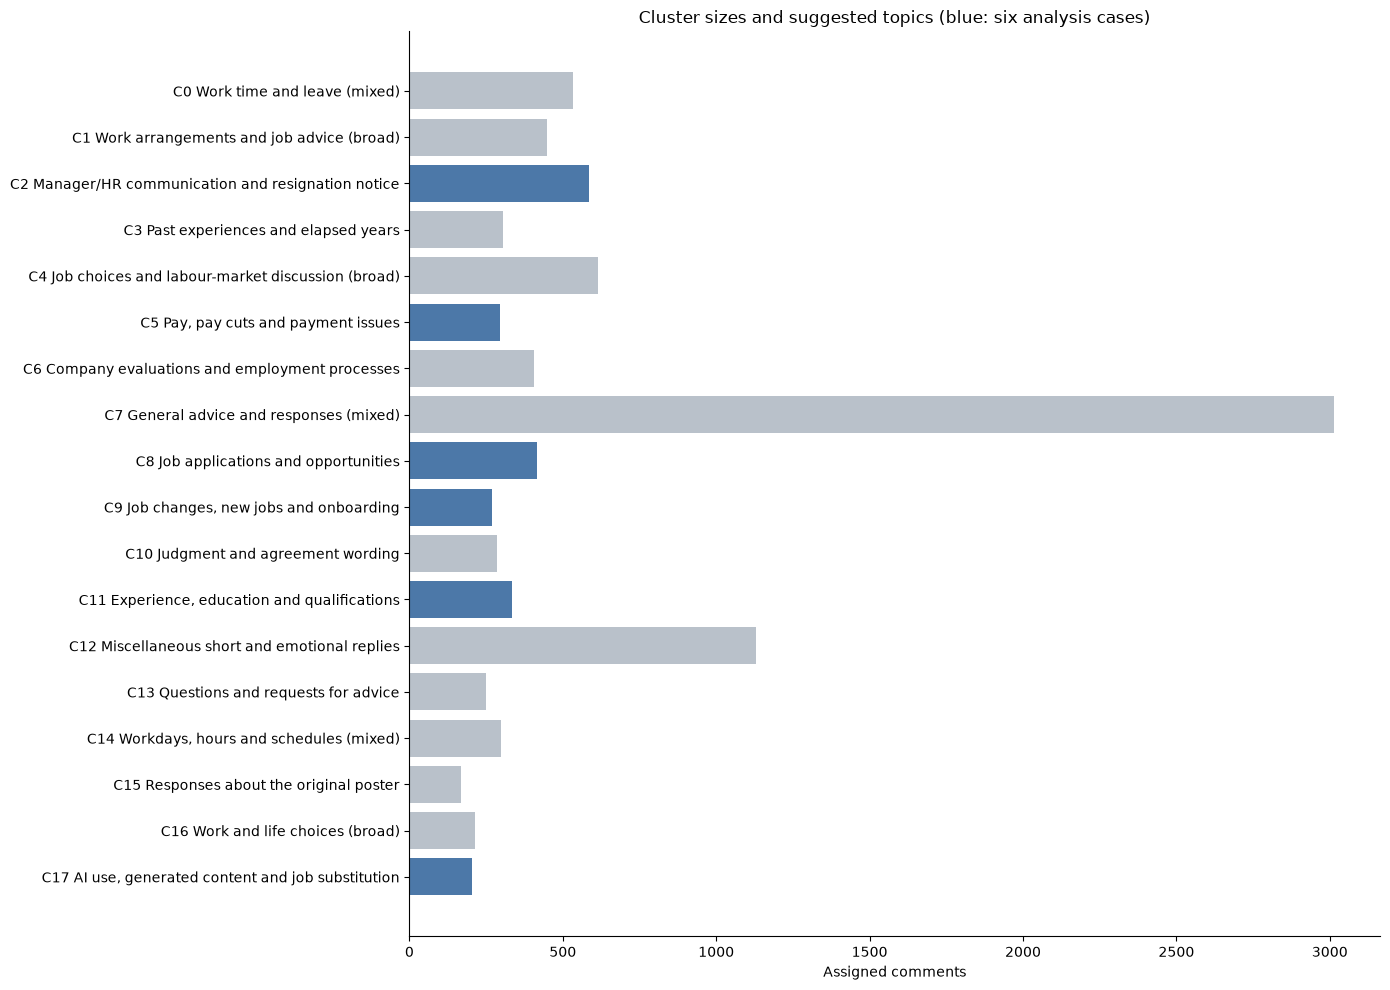

In [ ]:
final_ready = False
topic_review = pd.DataFrame()
focus_ids = []
if features_ready and SELECTED_K is not None:
    model_df, topic_profiles, representative_comments = build_topic_profiles(
        X, Z, model_df, vectorizer, final_model, labels=TOPIC_LABELS, seed=SEED,
    )
    if review_binding_verified:
        topic_review = pd.DataFrame(TOPIC_REVIEW)
        topic_profiles = topic_profiles.drop(columns='topic_label').merge(topic_review, on='cluster', validate='one_to_one')
        topic_profiles['label_source'] = 'assistant_suggested'
        topic_profiles['human_validated'] = False
        for cluster, name in TOPIC_LABELS.items():
            topic_profiles.loc[topic_profiles.cluster.eq(cluster), ['topic_label', 'label_source', 'human_validated']] = [name, 'human_provided', True]
        focus_ids = CASE_STUDY_IDS.copy()
        assert set(focus_ids).issubset(set(topic_profiles.cluster))
    else:
        topic_profiles = topic_profiles.assign(semantic_confidence='Not assessed', employment_topic=False,
            interpretation_limit='New model: requires separate semantic review.', trend_judgment='Not assessed',
            label_source='unreviewed', human_validated=False)
    for field in ['semantic_evidence', 'project_relevance', 'robustness_assessment']:
        topic_profiles[field] = topic_profiles.cluster.map(
            lambda cluster: CASE_STUDY_CONTEXT.get(cluster, {}).get(field, '') if review_binding_verified else '')
    topic_profiles['focus_topic'] = topic_profiles.cluster.isin(focus_ids)
    topic_profiles['chart_label'] = 'C' + topic_profiles.cluster.astype(str) + ' ' + topic_profiles.topic_label
    topic_names = topic_profiles.set_index('cluster').topic_label.to_dict()
    chart_labels = topic_profiles.set_index('cluster').chart_label.to_dict()
    model_df['topic_label'] = model_df.cluster.map(topic_names)
    representative_comments = representative_comments.merge(
        topic_profiles[['cluster', 'topic_label', 'semantic_confidence', 'label_source', 'human_validated']],
        on='cluster', how='left', validate='many_to_one')
    boundary_diagnostics = boundary_diagnostics.merge(
        topic_profiles[['cluster', 'topic_label', 'semantic_confidence']], on='cluster', validate='one_to_one')
    display(topic_profiles[['cluster', 'topic_label', 'n_comments', 'share', 'semantic_confidence',
                            'employment_topic', 'focus_topic', 'trend_judgment', 'interpretation_limit']])
    display(representative_comments)
    fig, ax = plt.subplots(figsize=(14, 10))
    ordered = topic_profiles.sort_values('cluster')
    ax.barh(ordered.chart_label, ordered.n_comments,
            color=['#4c78a8' if k in focus_ids else '#b9c1ca' for k in ordered.cluster])
    ax.invert_yaxis()
    ax.set(title='Cluster sizes and suggested topics (blue: six analysis cases)', xlabel='Assigned comments')
    fig.tight_layout()
    figures['cluster_sizes'] = fig
    plt.show()
    final_ready = True

### K-means: Two-dimensional view for illustration

Display PC1/PC2 from the raw PCA projection, with crosses at raw projected cluster means. Actual clustering can use normalized multidimensional coordinates.
This view does not reproduce the clustering distance. Its reported variance concerns only the first two raw principal components.

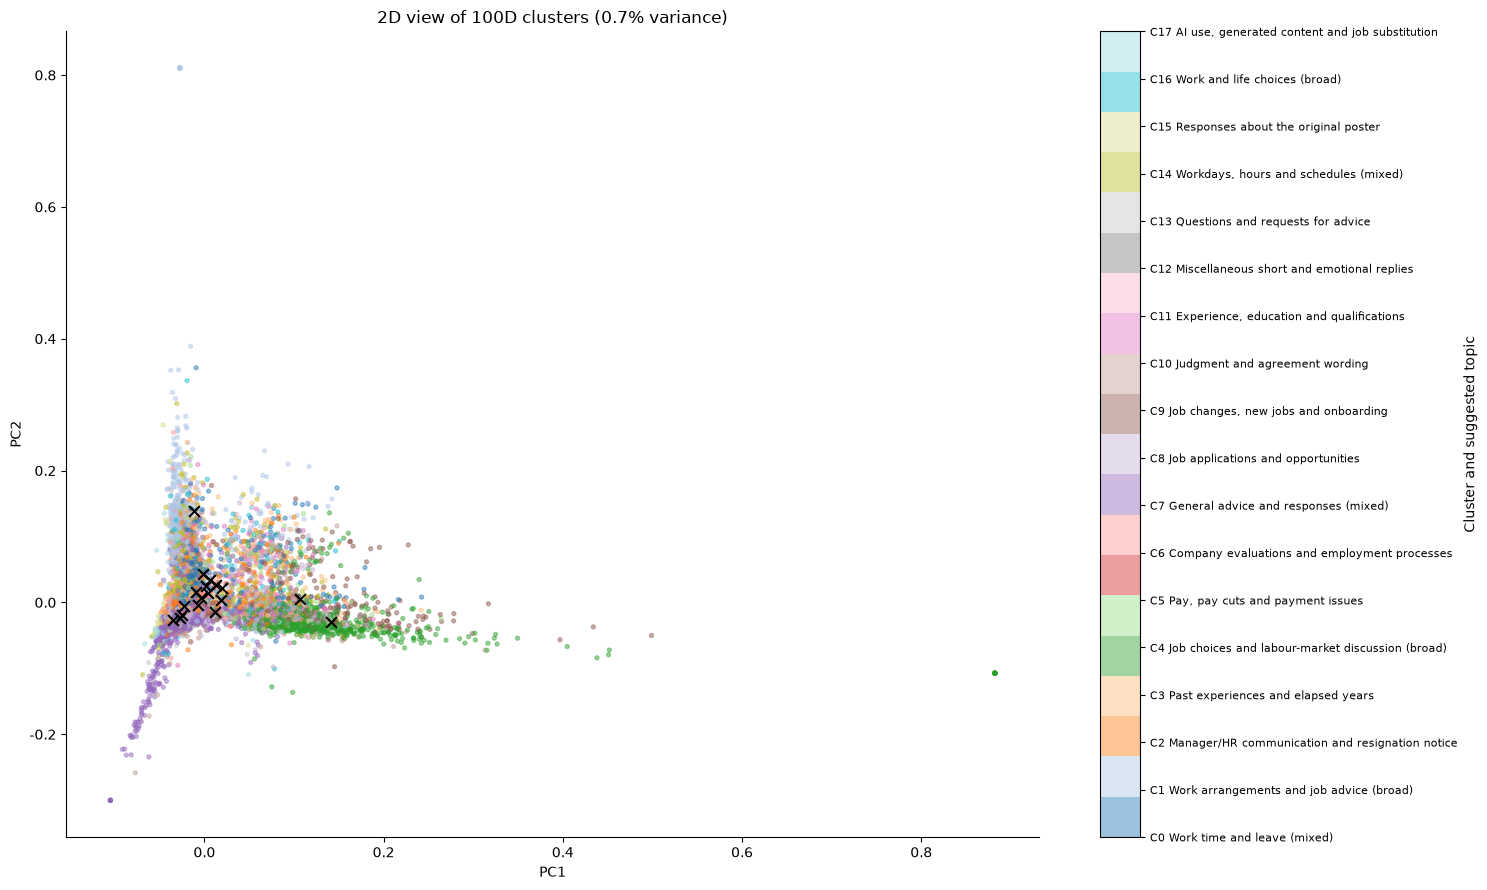

In [ ]:
if final_ready:
    fig, ax = plt.subplots(figsize=(15, 9))
    scatter = ax.scatter(Z_pca[:, 0], Z_pca[:, 1], c=final_model.labels_, cmap='tab20', s=8, alpha=0.45)
    centers_2d = np.array([Z_pca[final_model.labels_ == k, :2].mean(axis=0) for k in range(SELECTED_K)])
    ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='x', s=60)
    ax.set(xlabel='PC1', ylabel='PC2', title=f'2D view of {pca.n_components_}D clusters ({pca.explained_variance_ratio_[:2].sum():.1%} variance)')
    colorbar = fig.colorbar(scatter, ax=ax, ticks=range(SELECTED_K), label='Cluster and suggested topic')
    colorbar.ax.set_yticklabels([chart_labels[k] for k in range(SELECTED_K)], fontsize=8)
    fig.tight_layout()
    figures['cluster_projection'] = fig
    plt.show()

### K-means: Monthly shares and sensitivity; C7 hidden in the heatmap

Each topic share divides its monthly comment count by **all assigned comments across all 18 clusters**.
Equal-post shares give each sampled month-post pair total weight one. Leave-one-time-stratum-out ranges show sensitivity to dropping one time block; they are not confidence intervals.

Compare complete January-March and July-September periods. October is partial at the frozen cutoff of 2026-10-28 07:10:54 UTC, or 15:10:54 Singapore time. Partial months remain plotted with an asterisk/shading but are excluded from period comparisons. Missing whole months are not invented as zero activity.

The heatmap hides only C7. The other 17 rows retain their original values, so columns need not total 100%. Its shared linear scale uses the visible maximum, about 13.3%, rather than the C7-dominated maximum of about 33.4%.
Cells show actual percentages. There is no resampling, renormalization, row standardization or nonlinear color transformation. C12 remains visible.

,sampled,assigned,assignment_rate
month,,,
2026-01,1000,985,0.985
2026-02,1000,984,0.984
2026-03,1000,984,0.984
2026-04,1000,979,0.979
2026-05,1000,985,0.985
2026-06,1000,965,0.965
2026-07,1000,960,0.960
2026-08,1000,973,0.973
2026-09,1000,973,0.973


,cluster,n_comments,first3_share,last3_share,change_pp,equal_post_first3_mean,equal_post_last3_mean,equal_post_change_pp,complete_months,both_periods_available,topic_label,semantic_confidence,employment_topic,focus_topic,trend_judgment,semantic_evidence,project_relevance,robustness_assessment
0,0,534,0.047071,0.052994,0.592303,0.040960,0.051392,1.043181,9,True,Work time and leave (mixed),Low-medium,True,False,Fluctuates without a clear sustained direction.,,,
1,1,448,0.044362,0.045079,0.071748,0.048020,0.038251,-0.976957,9,True,Work arrangements and job advice (broad),Low,True,False,No clear trend; equal-post weighting changes t...,,,
2,2,586,0.049780,0.068479,1.869912,0.059532,0.072278,1.274564,9,True,Manager/HR communication and resignation notice,Medium,True,True,"Strongest upward display candidate, with mixed...","Manager, HR and notice terms support communica...","Hiring, management communication and resignati...",Comment shares: 4.98% to 6.85%; equal-post sha...
3,3,304,0.030816,0.034412,0.359544,0.027900,0.037306,0.940636,9,True,Past experiences and elapsed years,Low,False,False,No clear topic trend; elapsed-year wording is ...,,,
4,4,615,0.063664,0.067447,0.378259,0.072570,0.065907,-0.666314,9,True,Job choices and labour-market discussion (broad),Low-medium,True,False,No clear sustained trend; broad job discussion...,,,
5,5,295,0.031832,0.031659,-0.017340,0.029964,0.030272,0.030741,9,True,"Pay, pay cuts and payment issues",Medium-high,True,True,Broadly stable; useful as a stable-topic refer...,"Pay, pay cut, bills and rate support salary/pa...",Compensation and economic-pressure discussion ...,Comment shares: 3.18% to 3.17%; equal-post: 3....
6,6,406,0.039959,0.041982,0.202274,0.040160,0.046298,0.613726,9,True,Company evaluations and employment processes,Low-medium,True,False,Fluctuates without a clear sustained direction.,,,
7,7,3013,0.309854,0.310392,0.053791,0.306625,0.313843,0.721818,9,True,General advice and responses (mixed),Low,False,False,Large and broadly stable; unsuitable for a sin...,,,
8,8,415,0.048425,0.038197,-1.022850,0.054913,0.039030,-1.588295,9,True,Job applications and opportunities,Medium,True,True,Declining signal with intermediate rebounds; m...,"Apply, applying, jobs and resume support appli...","Applications, opportunities and recruitment ch...",Comment shares: 4.84% to 3.82%; equal-post: 5....
9,9,269,0.029462,0.033035,0.357354,0.025998,0.033379,0.738070,9,True,"Job changes, new jobs and onboarding",High,True,True,Lower April-May and higher August-September; n...,"New job, start and quit support job changes, o...",Work transitions and joining a new employer ar...,Lower April-May and higher August-September; q...


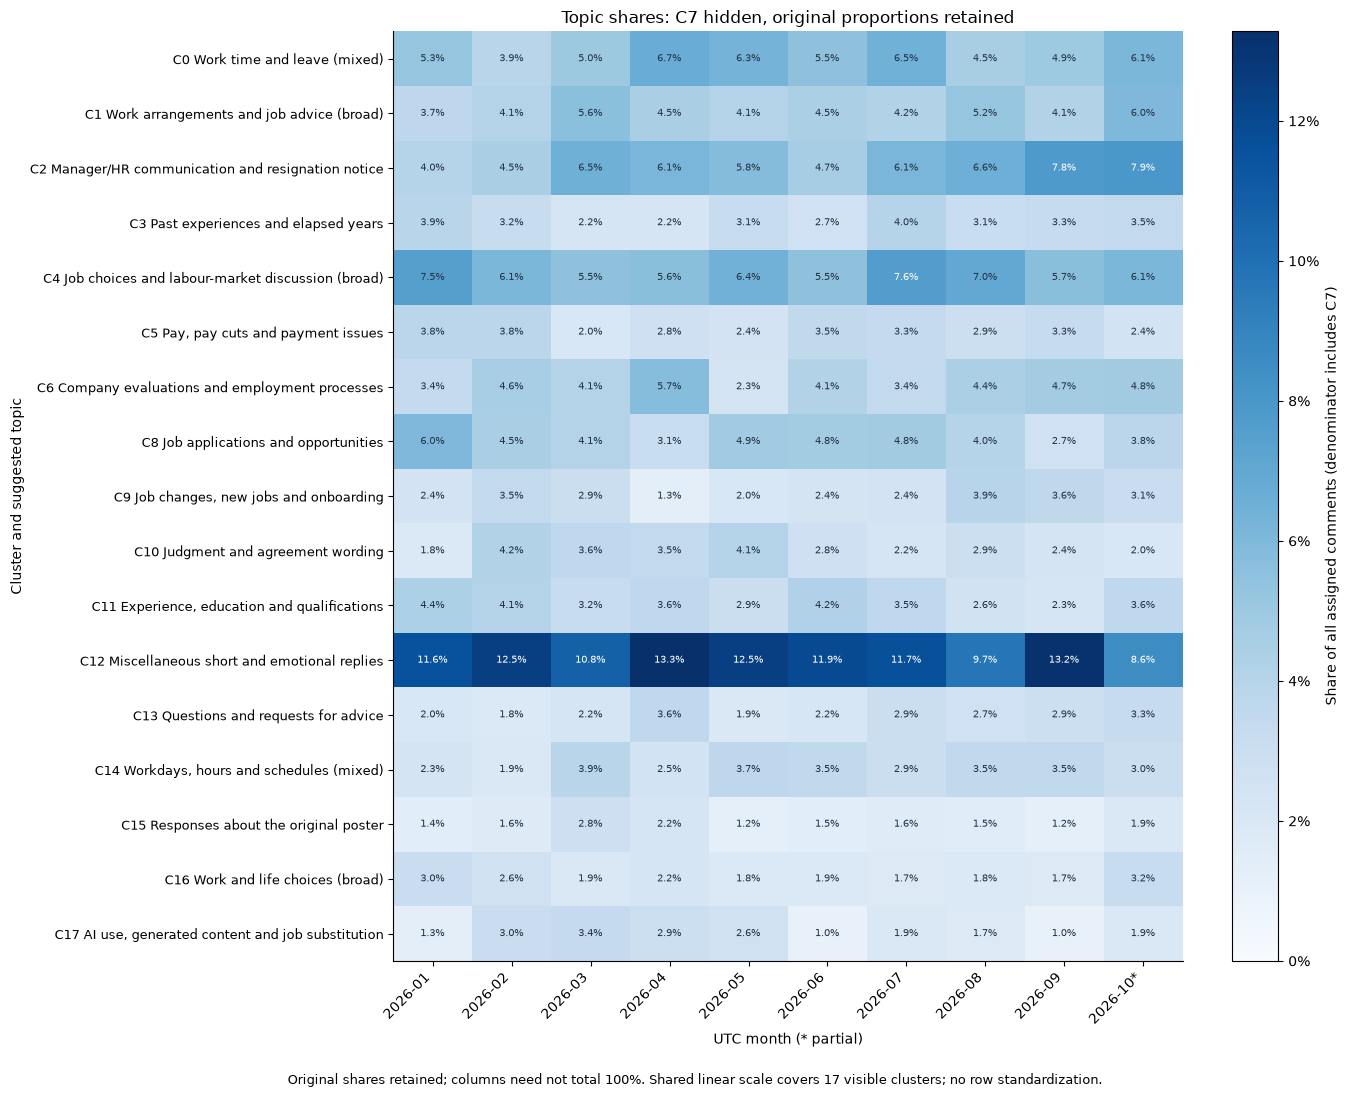

In [ ]:
if final_ready:
    early_months = [f'{YEAR}-{month:02d}' for month in [1, 2, 3]]
    late_months = [f'{YEAR}-{month:02d}' for month in [7, 8, 9]]
    topic_counts, topic_shares, monthly_topics, trend_summary = topic_trend_diagnostics(
        model_df, coverage[['month', 'partial_month', 'source_window_complete']], early_months, late_months,
    )
    metadata_columns = ['cluster', 'topic_label', 'semantic_confidence', 'employment_topic', 'focus_topic', 'trend_judgment',
                        'semantic_evidence', 'project_relevance', 'robustness_assessment']
    monthly_topics = monthly_topics.merge(topic_profiles[metadata_columns], on='cluster', validate='many_to_one')
    trend_summary = trend_summary.merge(topic_profiles[metadata_columns], on='cluster', validate='one_to_one')
    focus_trend_summary = trend_summary.loc[trend_summary.focus_topic].copy()
    monthly_assignment_coverage = corpus.groupby('month').size().rename('sampled').to_frame()
    monthly_assignment_coverage['assigned'] = model_df.groupby('month').size()
    monthly_assignment_coverage['assignment_rate'] = monthly_assignment_coverage['assigned'] / monthly_assignment_coverage['sampled']
    display(monthly_assignment_coverage)
    display(trend_summary)
    assert np.allclose(topic_shares.sum(axis=1), 1)
    month_order = topic_shares.index.tolist()
    partial_months = set(coverage.loc[coverage.partial_month.astype(str).str.lower().eq('true'), 'month'])
    month_ticks = [month + ('*' if month in partial_months else '') for month in month_order]
    # Compute all 18 shares first, then hide C7 without rescaling.
    heatmap_shares = topic_shares.drop(columns=HEATMAP_HIDDEN_CLUSTERS, errors='ignore').copy()
    assert np.array_equal(heatmap_shares.to_numpy(), topic_shares[heatmap_shares.columns].to_numpy())
    heatmap_vmax = float(heatmap_shares.to_numpy().max())
    fig, ax = plt.subplots(figsize=(14, 11))
    chart = ax.imshow(heatmap_shares.T.to_numpy(), aspect='auto', vmin=0, vmax=heatmap_vmax, cmap='Blues')
    ax.set_xticks(range(len(month_order)), month_ticks, rotation=45, ha='right')
    ax.set_yticks(range(len(heatmap_shares.columns)), [chart_labels[k] for k in heatmap_shares.columns], fontsize=9)
    ax.set(xlabel='UTC month (* partial)', ylabel='Cluster and suggested topic', title='Topic shares: C7 hidden, original proportions retained')
    from matplotlib.ticker import PercentFormatter
    colorbar = fig.colorbar(chart, ax=ax, label='Share of all assigned comments (denominator includes C7)')
    colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    for row, cluster in enumerate(heatmap_shares.columns):
        for column, month in enumerate(month_order):
            value = float(heatmap_shares.loc[month, cluster])
            ax.text(column, row, f'{value * 100:.1f}%', ha='center', va='center', fontsize=7,
                    color='white' if value > heatmap_vmax * 0.57 else '#243447')
    fig.text(0.5, 0.01, 'Original shares retained; columns need not total 100%. Shared linear scale covers 17 visible clusters; no row standardization.',
             ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    figures['monthly_heatmap'] = fig
    plt.show()

### K-means: Six cases: semantics, size, relevance and robustness

The review table preserves original interpretation confidence and reports counts, overall shares, semantic evidence, project relevance and robustness judgments. Overall size includes January-October; quarterly comparisons use complete January-March and July-September only.
Qualitative explanations accompany actual measurements; no unvalidated composite score is constructed.

| Case | Analysis value | Complete-quarter shares and interpretation limits |
|---|---|---|
| C2 Manager/HR communication and resignation notice | Larger topic with an upward signal | 4.98% to 6.85%; equal-post weighting also rises. Mixed communication/notice wording does not establish worsening conflict. |
| C5 Pay, pay cuts and payment issues | Employment-related stable reference | 3.18% to 3.17%; equal-post shares are also stable. Do not show only changing topics. |
| C8 Job applications and opportunities | Core job-seeking discussion | 4.84% to 3.82%, with intermediate rebounds; not evidence that job seeking became easier. |
| C9 Job changes, new jobs and onboarding | Relatively coherent phase-dependent discussion | 2.95% to 3.30%; lower April-May, higher August-September. Discussion is not actual job-switching counts. |
| C11 Experience, education and qualifications | Credentials and job-fit discussion | 3.86% to 2.79%, with a June rebound; not evidence that employers lowered requirements. |
| C17 AI use, generated content and job substitution | AI-related work and content discussion | 2.57% to 1.55%; higher February-May, generally lower later. Only about 10-33 comments per complete month; not solely job-loss anxiety. |

The robustness table includes equal-post period changes, monthly counts, distinct-post counts, maximum single-post contribution and time-stratum sensitivity. These describe fixed assignments; they are not semantic accuracy, population confidence intervals or causal tests.

All six panels retain the original all-topic denominator. Blue denotes comment-weighted shares; orange denotes equal sampled-post weights. Bands show leave-one-stratum-out ranges; grey marks partial months. A shared zero-based y-axis supports scale comparisons.

,cluster,topic_label,semantic_confidence,n_comments,share,semantic_evidence,project_relevance,robustness_assessment,interpretation_limit
0,2,Manager/HR communication and resignation notice,Medium,586,0.059980,"Manager, HR and notice terms support communica...","Hiring, management communication and resignati...",Comment shares: 4.98% to 6.85%; equal-post sha...,"Communication, recruitment management, leave a..."
1,5,"Pay, pay cuts and payment issues",Medium-high,295,0.030194,"Pay, pay cut, bills and rate support salary/pa...",Compensation and economic-pressure discussion ...,Comment shares: 3.18% to 3.17%; equal-post: 3....,Payment-related meaning is relatively consiste...
2,8,Job applications and opportunities,Medium,415,0.042477,"Apply, applying, jobs and resume support appli...","Applications, opportunities and recruitment ch...",Comment shares: 4.84% to 3.82%; equal-post: 5....,"Applications, job sources and opportunities co..."
3,9,"Job changes, new jobs and onboarding",High,269,0.027533,"New job, start and quit support job changes, o...",Work transitions and joining a new employer ar...,Lower April-May and higher August-September; q...,"New work, resignation timing, offers and job-s..."
4,11,"Experience, education and qualifications",Medium-high,335,0.034289,"Experience, degree and entry level support qua...",Experience requirements and education/job fit ...,Comment shares: 3.86% to 2.79%; equal-post: 4....,Experience and education are relatively cohere...
5,17,"AI use, generated content and job substitution",High,204,0.020880,"AI, generated, replace and slop support tools,...","AI use and labour substitution matter, but AI-...",Comment shares: 2.57% to 1.55%; equal-post: 2....,"Content identification, AI use and substitutio..."


,cluster,topic_label,first3_share,last3_share,change_pp,equal_post_first3_mean,equal_post_last3_mean,equal_post_change_pp,min_monthly_comments,max_monthly_comments,min_monthly_posts,max_monthly_posts,max_single_post_share,trend_judgment
0,2,Manager/HR communication and resignation notice,0.049780,0.068479,1.869912,0.059532,0.072278,1.274564,39,76,36,57,0.109375,"Strongest upward display candidate, with mixed..."
1,5,"Pay, pay cuts and payment issues",0.031832,0.031659,-0.017340,0.029964,0.030272,0.030741,20,37,16,28,0.243243,Broadly stable; useful as a stable-topic refer...
2,8,Job applications and opportunities,0.048425,0.038197,-1.022850,0.054913,0.039030,-1.588295,26,59,22,43,0.152542,Declining signal with intermediate rebounds; m...
3,9,"Job changes, new jobs and onboarding",0.029462,0.033035,0.357354,0.025998,0.033379,0.738070,13,38,13,29,0.210526,Lower April-May and higher August-September; n...
4,11,"Experience, education and qualifications",0.038605,0.027873,-1.073144,0.043027,0.035737,-0.729018,22,43,19,35,0.120000,"Declining signal, with a June rebound and mode..."
5,17,"AI use, generated content and job substitution",0.025737,0.015485,-1.025134,0.024508,0.016833,-0.767492,10,33,9,23,0.235294,Higher February-May and generally lower after ...


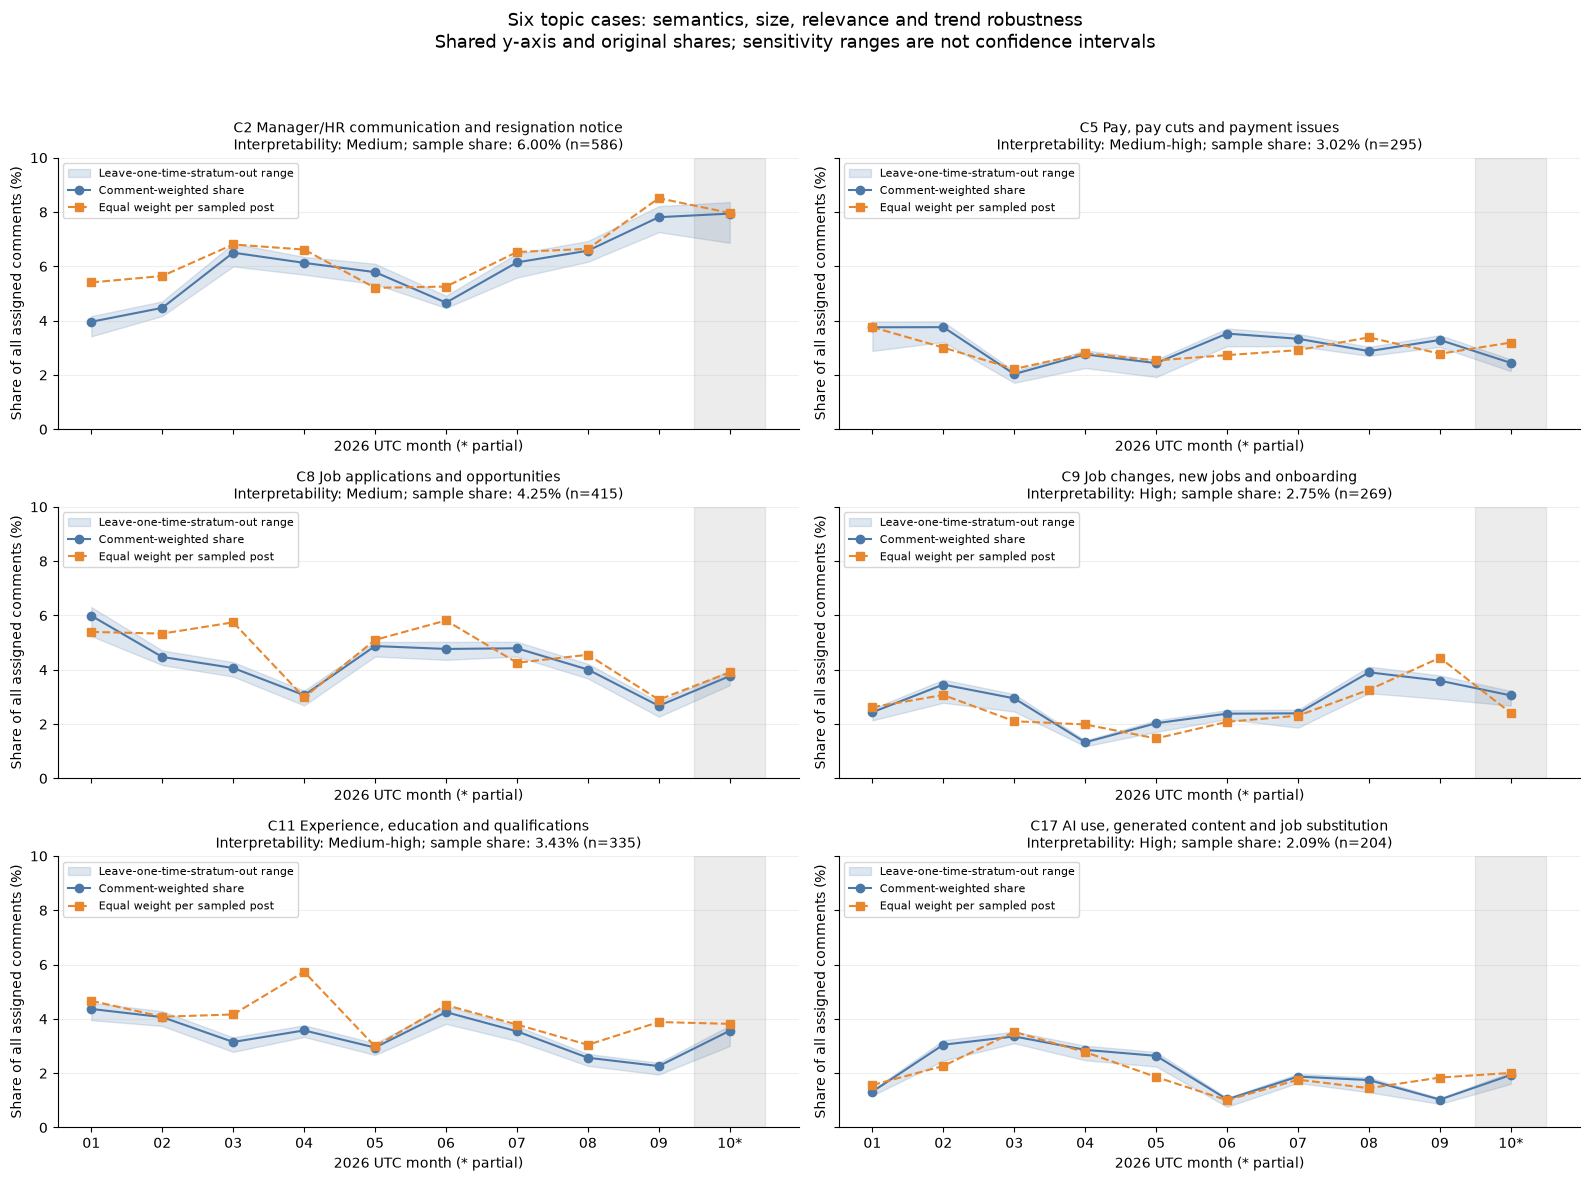

In [ ]:
focus_case_review = pd.DataFrame()
focus_robustness = pd.DataFrame()
if final_ready and focus_ids:
    focus_case_review = topic_profiles.set_index('cluster').loc[focus_ids, [
        'topic_label', 'semantic_confidence', 'n_comments', 'share',
        'semantic_evidence', 'project_relevance', 'robustness_assessment', 'interpretation_limit',
    ]].reset_index()
    complete_rows = monthly_topics.loc[
        monthly_topics.cluster.isin(focus_ids)
        & ~monthly_topics.partial_month.astype(str).str.lower().eq('true')
    ]
    focus_robustness = complete_rows.groupby('cluster').agg(
        min_monthly_comments=('n_topic', 'min'), max_monthly_comments=('n_topic', 'max'),
        min_monthly_posts=('unique_posts', 'min'), max_monthly_posts=('unique_posts', 'max'),
        max_single_post_share=('top_post_share', 'max'),
    ).reset_index().merge(focus_trend_summary, on='cluster', validate='one_to_one')
    display(focus_case_review)
    display(focus_robustness[['cluster', 'topic_label', 'first3_share', 'last3_share', 'change_pp',
                            'equal_post_first3_mean', 'equal_post_last3_mean', 'equal_post_change_pp',
                            'min_monthly_comments', 'max_monthly_comments', 'min_monthly_posts',
                            'max_monthly_posts', 'max_single_post_share', 'trend_judgment']])
    fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True, sharey=True)
    x = np.arange(len(month_order))
    focus_max = monthly_topics.loc[monthly_topics.cluster.isin(focus_ids), ['topic_share', 'equal_post_share', 'maximum_share']].max().max()
    upper_percent = max(5.0, float(np.ceil(focus_max * 100 + 0.5)))
    for ax, cluster in zip(axes.ravel(), focus_ids):
        subset = monthly_topics.loc[monthly_topics.cluster.eq(cluster)].set_index('month').loc[month_order]
        profile = topic_profiles.set_index('cluster').loc[cluster]
        if subset.minimum_share.notna().any():
            ax.fill_between(x, subset.minimum_share.to_numpy() * 100, subset.maximum_share.to_numpy() * 100,
                            alpha=0.18, color='#4c78a8', label='Leave-one-time-stratum-out range')
        ax.plot(x, subset.topic_share.to_numpy() * 100, marker='o', color='#4c78a8', label='Comment-weighted share')
        ax.plot(x, subset.equal_post_share.to_numpy() * 100, marker='s', linestyle='--', color='#e8872d', label='Equal weight per sampled post')
        for index, month in enumerate(month_order):
            if month in partial_months:
                ax.axvspan(index - 0.5, index + 0.5, color='grey', alpha=0.15)
        ax.set_title(chart_labels[cluster] + '\n' + f'Interpretability: {profile.semantic_confidence}; sample share: {profile.share:.2%} (n={profile.n_comments})', fontsize=10)
        ax.set(ylabel='Share of all assigned comments (%)', ylim=(0, upper_percent))
        ax.set_xticks(x, [month[5:] + ('*' if month in partial_months else '') for month in month_order])
        ax.set_xlabel(f'{YEAR} UTC month (* partial)')
        ax.grid(axis='y', alpha=0.2)
        ax.legend(fontsize=8)
    fig.suptitle('Six topic cases: semantics, size, relevance and trend robustness\nShared y-axis and original shares; sensitivity ranges are not confidence intervals', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    figures['focus_monthly_trends'] = fig
    plt.show()
else:
    print('No frozen-model case studies applied; new models require separate interpretation.')

### K-means: Corpus coverage, model parameters and dimensionality comparisons

The count table separates the original sample, assigned comments, moderation notices and zero-feature comments. The parameter table records the vocabulary size, PCA dimension, normalization and K-means settings used for the analysis.

The four-dimension curve shows how much TF-IDF variance is retained by 50, 100, 200 and 400 principal components before row normalization. The fixed-k comparison evaluates alternative dimensions and normalization settings on the same original TF-IDF cosine geometry. Together these outputs distinguish information retention from cluster separation.

In [ ]:
analysis_tables = {}
analysis_check_rows = []
analysis_sources = []
analysis_ready = bool(final_ready and review_binding_verified)
analysis_pca_ready = False

def check_reference_value(result, measured, reference_value, decimals):
    rounded = round(float(measured), decimals)
    analysis_check_rows.append({'result': result, 'recomputed': float(measured),
                           'reference_value': float(reference_value), 'decimals': decimals,
                           'passed': bool(np.isclose(rounded, reference_value, atol=1e-9, rtol=0))})

if analysis_ready:
    reason_counts = feature_excluded.reason.value_counts()
    analysis_data_counts = pd.DataFrame([
        {'measure': 'Sampled comments', 'n_comments': len(corpus)},
        {'measure': 'Assigned comments', 'n_comments': len(model_df)},
        {'measure': 'Excluded moderation notices', 'n_comments': int(reason_counts.get('moderation_notice', 0))},
        {'measure': 'Excluded zero-feature comments', 'n_comments': int(reason_counts.get('zero_tfidf', 0))},
    ])
    assert len(corpus) == len(model_df) + len(feature_excluded)
    for measure, expected in [('Sampled comments', 10000), ('Assigned comments', 9770),
                              ('Excluded moderation notices', 106), ('Excluded zero-feature comments', 124)]:
        check_reference_value(measure, analysis_data_counts.set_index('measure').loc[measure, 'n_comments'], expected, 0)
    analysis_model_settings = pd.DataFrame([
        {'setting': 'TF-IDF vocabulary size', 'value': X.shape[1]},
        {'setting': 'PCA components', 'value': int(pca.n_components_)},
        {'setting': 'PCA row L2 normalization', 'value': normalizer is not None},
        *[{'setting': 'K-means ' + key, 'value': final_model.get_params()[key]}
          for key in ['n_clusters', 'init', 'n_init', 'random_state', 'max_iter', 'algorithm']],
    ])
    display(analysis_data_counts)
    display(analysis_model_settings)
    analysis_tables['analysis_data_counts.csv'] = analysis_data_counts
    analysis_tables['analysis_model_settings.csv'] = analysis_model_settings
    analysis_tables['analysis_k_selection.csv'] = k_results.copy()
    if {18, 20}.issubset(set(k_results.k)):
        indexed_k = k_results.set_index('k')
        check_reference_value('k=20 scores above k=18 in the selected PCA space',
            indexed_k.loc[20, 'silhouette'] > indexed_k.loc[18, 'silhouette'], 1, 0)
else:
    print('Frozen-result summaries skipped: the verified frozen model and its original local corpus are required.')

,measure,n_comments
0,Sampled comments,10000
1,Assigned comments,9770
2,Excluded moderation notices,106
3,Excluded zero-feature comments,124


,setting,value
0,TF-IDF vocabulary size,10000
1,PCA components,100
2,PCA row L2 normalization,True
3,K-means n_clusters,18
4,K-means init,k-means++
5,K-means n_init,30
6,K-means random_state,42
7,K-means max_iter,300
8,K-means algorithm,lloyd


,component,cumulative_variance,retained_variance_pct
0,50,0.087086,8.708597
1,100,0.144052,14.405203
2,200,0.228748,22.874829
3,400,0.348018,34.801760


,k,inertia,silhouette,actual_clusters,smallest_cluster,smallest_cluster_share,largest_cluster_share,iterations,seconds,inertia_drop_fraction,tfidf_cosine_silhouette,mean_top_term_jaccard,configuration,components,l2_normalize,retained_variance
0,6,756.518921,0.090993,6,111,0.011361,0.706551,19,0.271254,NaN,0.004391,0.095557,pca50_raw_k6,50,False,0.087086
1,8,733.281982,0.088467,8,80,0.008188,0.577789,46,0.286840,0.030716,0.005620,0.085250,pca50_raw_k8,50,False,0.087086
2,10,708.935608,0.100647,10,107,0.010952,0.526305,18,0.233376,0.033202,0.007084,0.089017,pca50_raw_k10,50,False,0.087086
3,11,696.378662,0.110256,11,109,0.011157,0.547288,20,0.339681,0.017712,0.006582,0.112966,pca50_raw_k11,50,False,0.087086
4,12,692.380249,0.106142,12,108,0.011054,0.519754,32,0.335593,0.005742,0.006588,0.133659,pca50_raw_k12,50,False,0.087086
5,15,655.181030,0.106555,15,104,0.010645,0.499898,25,0.359325,0.053727,0.008998,0.083436,pca50_raw_k15,50,False,0.087086
6,6,7903.783203,0.081679,6,640,0.065507,0.429580,42,0.268008,NaN,0.003419,0.091658,pca50_l2_k6,50,True,0.087086
7,8,7622.252441,0.089327,8,505,0.051689,0.390890,31,0.278174,0.035620,0.003957,0.093094,pca50_l2_k8,50,True,0.087086
8,10,7386.455078,0.100892,10,309,0.031627,0.357421,26,0.250069,0.030935,0.005088,0.101516,pca50_l2_k10,50,True,0.087086
9,11,7269.703125,0.092648,11,235,0.024053,0.290583,21,0.267487,0.015806,0.004980,0.070485,pca50_l2_k11,50,True,0.087086


Historical dimension grid: n_init=10. Final k=18/20 comparisons use n_init=30.


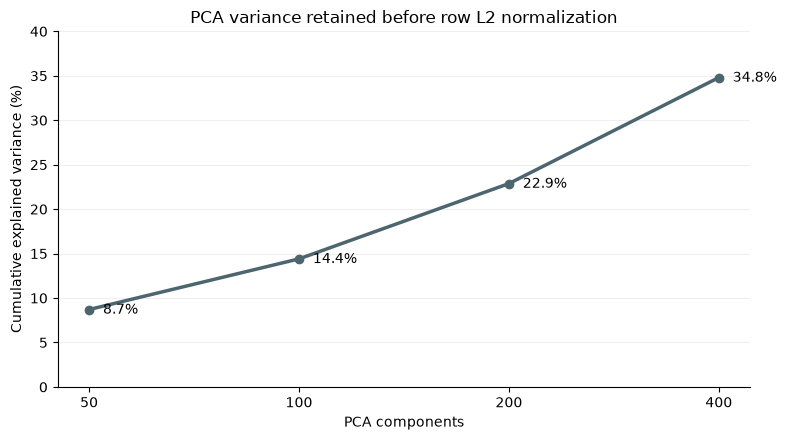

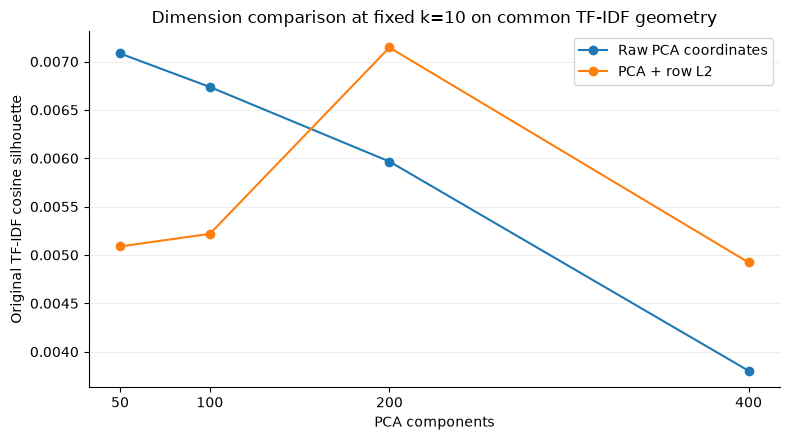

In [ ]:
if analysis_ready:
    pca_paths = {name: PCA_COMPARISON_DIR / name for name in [
        'comparison_manifest.json', 'pca_variance.csv', 'comparison.csv']}
    missing = [str(path) for path in pca_paths.values() if not path.exists()]
    if missing:
        print('Four-dimension plot unavailable. Restore these recorded experiment files:', missing)
    else:
        comparison_metadata = json.loads(pca_paths['comparison_manifest.json'].read_text(encoding='utf-8'))
        if comparison_metadata['input_sha256'] != REVIEW_BINDING['input'] or comparison_metadata['seed'] != SEED:
            raise ValueError('The PCA comparison does not match the frozen corpus and seed.')
        full_spectrum = pd.read_csv(pca_paths['pca_variance.csv'])
        dimensions = [50, 100, 200, 400]
        assert len(full_spectrum) >= max(dimensions)
        assert np.array_equal(full_spectrum.component.to_numpy(), np.arange(1, len(full_spectrum) + 1))
        assert np.isfinite(full_spectrum.cumulative_variance).all()
        assert full_spectrum.cumulative_variance.is_monotonic_increasing
        np.testing.assert_allclose(full_spectrum.cumulative_variance.iloc[:actual_components],
                                   pca_variance.cumulative_variance, atol=1e-5, rtol=1e-4)
        analysis_pca_dimensions = full_spectrum.set_index('component').loc[dimensions, ['cumulative_variance']].reset_index()
        analysis_dimension_candidates = pd.read_csv(pca_paths['comparison.csv'])
        assert set(analysis_dimension_candidates.components) == set(dimensions)
        for components, retained_value in analysis_pca_dimensions.itertuples(index=False):
            np.testing.assert_allclose(analysis_dimension_candidates.loc[
                analysis_dimension_candidates.components.eq(components), 'retained_variance'], retained_value, atol=1e-6)
        for components, expected in zip(dimensions, [8.7, 14.4, 22.9, 34.8]):
            check_reference_value(f'PCA {components}: retained variance (%)',
                analysis_pca_dimensions.set_index('component').loc[components, 'cumulative_variance'] * 100, expected, 1)
        display(analysis_pca_dimensions.assign(retained_variance_pct=lambda data: data.cumulative_variance * 100))
        display(analysis_dimension_candidates)
        print('Historical dimension grid: n_init=10. Final k=18/20 comparisons use n_init=30.')
        fig, ax = plt.subplots(figsize=(8, 4.5))
        values = analysis_pca_dimensions.cumulative_variance.to_numpy() * 100
        ax.plot(range(4), values, 'o-', color='#4D656E', linewidth=2.5)
        for index, value in enumerate(values):
            ax.annotate(f'{value:.1f}%', (index, value), xytext=(10, -3), textcoords='offset points')
        ax.set(xticks=range(4), xticklabels=dimensions, xlabel='PCA components',
               ylabel='Cumulative explained variance (%)', ylim=(0, 40),
               title='PCA variance retained before row L2 normalization')
        ax.grid(axis='y', alpha=0.2)
        fig.tight_layout()
        figures['analysis_pca_dimensions'] = fig
        plt.show()
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for normalized, group in analysis_dimension_candidates.loc[analysis_dimension_candidates.k.eq(10)].groupby('l2_normalize'):
            group = group.sort_values('components')
            ax.plot(group.components, group.tfidf_cosine_silhouette, 'o-',
                    label='PCA + row L2' if str(normalized).lower() == 'true' else 'Raw PCA coordinates')
        ax.set(xlabel='PCA components', ylabel='Original TF-IDF cosine silhouette',
               title='Dimension comparison at fixed k=10 on common TF-IDF geometry', xticks=dimensions)
        ax.grid(axis='y', alpha=0.2)
        ax.legend()
        fig.tight_layout()
        figures['analysis_dimension_separation'] = fig
        plt.show()
        analysis_tables['analysis_pca_dimensions.csv'] = analysis_pca_dimensions
        analysis_tables['analysis_dimension_candidates.csv'] = analysis_dimension_candidates
        for name, path in pca_paths.items():
            analysis_sources.append({'source': name, 'path': str(path), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
        analysis_pca_ready = True

### K-means: Cluster proportions and evidence for topic names

The percentage chart includes all 18 clusters. Blue marks C2/C5/C8/C9/C11/C17, dark grey marks the mixed C7/C12 groups, and light grey marks the remaining groups. The colours identify analysis roles, not measured semantic accuracy.

The focus and mixed-cluster proportions use all 9,770 assigned comments as the denominator. Silhouettes use the fixed 1,500-comment evaluation subset. Keyword and nearest/random comment tables show the evidence behind the proposed C9/C17 names and support examination of their semantic boundaries.

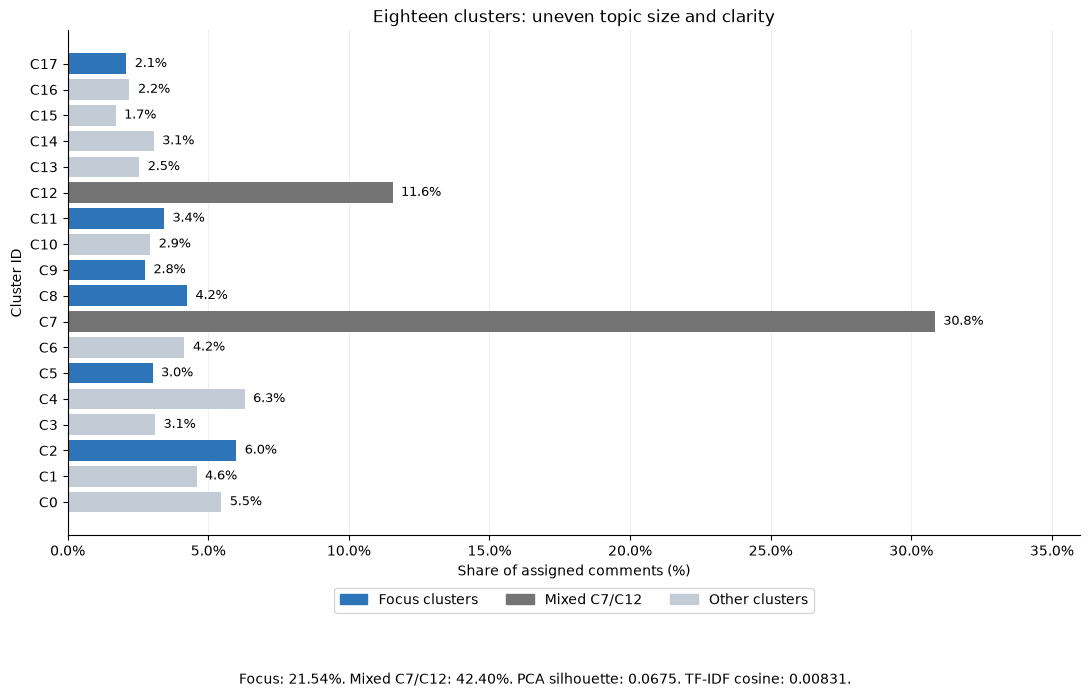

,cluster,topic_label,n_comments,share,top_terms,distinctive_terms,semantic_confidence,analysis_role
0,0,Work time and leave (mixed),534,0.054657,"time, off, job, work, time off, sick, waste, w...","time, time off, off, waste, sick, waste time, ...",Low-medium,Other clusters
1,1,Work arrangements and job advice (broad),448,0.045855,"work, job, hours, hard, make, days, home, free...","work, hours, hard, shifts, free, warehouse, wo...",Low,Other clusters
2,2,Manager/HR communication and resignation notice,586,0.059980,"tell, manager, hr, weeks, notice, week, job, h...","tell, manager, hr, notice, weeks, week, hiring...",Medium,Focus clusters
3,3,Past experiences and elapsed years,304,0.031116,"years, ago, years ago, 10, 10 years, job, 20, ...","years, ago, years ago, 10, 10 years, 20 years,...",Low,Other clusters
4,4,Job choices and labour-market discussion (broad),615,0.062948,"job, market, job market, getting job, better, ...","job, job market, market, getting job, job job,...",Low-medium,Other clusters
5,5,"Pay, pay cuts and payment issues",295,0.030194,"pay, job, work, make, company, offer, bills, p...","pay, pay cut, bills, rate, low, cut, higher, p...",Medium-high,Focus clusters
6,6,Company evaluations and employment processes,406,0.041556,"company, job, work, better, make, offer, compa...","company, current company, work company, compan...",Low-medium,Other clusters
7,7,General advice and responses (mixed),3013,0.308393,"thank, way, make, better, sure, thanks, post, ...","thank, thanks, read, post, way, man, thought, ...",Low,Mixed C7/C12
8,8,Job applications and opportunities,415,0.042477,"jobs, job, apply, applying, work, resume, look...","jobs, apply, applying, applying jobs, applied,...",Medium,Focus clusters
9,9,"Job changes, new jobs and onboarding",269,0.027533,"new, new job, job, start, looking, work, leave...","new, new job, job, start, looking new, looking...",High,Focus clusters


,cluster,topic_label,top_terms,distinctive_terms,semantic_evidence,interpretation_limit
9,9,"Job changes, new jobs and onboarding","new, new job, job, start, looking, work, leave...","new, new job, job, start, looking new, looking...","New job, start and quit support job changes, o...","New work, resignation timing, offers and job-s..."
17,17,"AI use, generated content and job substitution","ai, using, using ai, use ai, slop, use, replac...","ai, using, using ai, use ai, slop, replace, ai...","AI, generated, replace and slop support tools,...","Content identification, AI use and substitutio..."


,cluster,topic_label,selection,comment_id,text_preview
90,9,"Job changes, new jobs and onboarding",nearest,ozutv2g,Find a new job.
91,9,"Job changes, new jobs and onboarding",nearest,o89s23j,Just get the new job and beat it outta there A...
95,9,"Job changes, new jobs and onboarding",random,pgqn4b9,I would very quietly start looking for a new j...
96,9,"Job changes, new jobs and onboarding",random,ocgzkal,Well I am asking for clarification like did sh...
170,17,"AI use, generated content and job substitution",nearest,p15vwcr,Ai is lame
171,17,"AI use, generated content and job substitution",nearest,p56z3oi,This reads like AI.
175,17,"AI use, generated content and job substitution",random,oyldo1h,"Not only that, women couldn't buy themselves a..."
176,17,"AI use, generated content and job substitution",random,oosevp2,So true. The pic is wrong. This is just clickb...


In [ ]:
if analysis_ready:
    from matplotlib.patches import Patch
    from matplotlib.ticker import PercentFormatter
    analysis_cluster_shares = topic_profiles[['cluster', 'topic_label', 'n_comments', 'share',
                                         'top_terms', 'distinctive_terms', 'semantic_confidence']].copy()
    analysis_cluster_shares['analysis_role'] = analysis_cluster_shares.cluster.map(
        lambda cluster: 'Focus clusters' if cluster in focus_ids else 'Mixed C7/C12' if cluster in [7, 12] else 'Other clusters')
    focus_share = model_df.cluster.isin(focus_ids).mean()
    mixed_share = model_df.cluster.isin([7, 12]).mean()
    check_reference_value('Six focus clusters: assigned share (%)', focus_share * 100, 21.54, 2)
    check_reference_value('Mixed C7/C12: assigned share (%)', mixed_share * 100, 42.40, 2)
    check_reference_value('PCA-space silhouette', selected_diagnostics.silhouette.iloc[0], 0.0675, 4)
    check_reference_value('TF-IDF cosine silhouette', common_space_quality.tfidf_cosine_silhouette.iloc[0], 0.00831, 5)
    assert analysis_cluster_shares.n_comments.sum() == len(model_df)
    np.testing.assert_allclose(analysis_cluster_shares.share.sum(), 1)
    role_colors = {'Focus clusters': '#2D75B8', 'Mixed C7/C12': '#747474', 'Other clusters': '#C3CBD7'}
    ordered = analysis_cluster_shares.sort_values('cluster')
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.barh(ordered.cluster, ordered.share, color=ordered.analysis_role.map(role_colors))
    for row in ordered.itertuples():
        ax.text(row.share + 0.003, row.cluster, f'{row.share:.1%}', va='center', fontsize=9)
    ax.set(yticks=ordered.cluster, yticklabels=['C' + str(cluster) for cluster in ordered.cluster],
           xlabel='Share of assigned comments (%)', ylabel='Cluster ID', xlim=(0, 0.36),
           title='Eighteen clusters: uneven topic size and clarity')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(handles=[Patch(color=color, label=role) for role, color in role_colors.items()],
              loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=3)
    fig.text(0.5, 0.015, f'Focus: {focus_share:.2%}. Mixed C7/C12: {mixed_share:.2%}. '
             f'PCA silhouette: {selected_diagnostics.silhouette.iloc[0]:.4f}. '
             f'TF-IDF cosine: {common_space_quality.tfidf_cosine_silhouette.iloc[0]:.5f}.', ha='center', fontsize=10)
    fig.tight_layout(rect=(0, 0.09, 1, 1))
    figures['analysis_cluster_shares'] = fig
    plt.show()
    analysis_naming_evidence = topic_profiles.loc[topic_profiles.cluster.isin([9, 17]),
        ['cluster', 'topic_label', 'top_terms', 'distinctive_terms', 'semantic_evidence', 'interpretation_limit']].copy()
    analysis_naming_examples = representative_comments.loc[representative_comments.cluster.isin([9, 17])].groupby(
        ['cluster', 'selection'], sort=True).head(2).copy()
    analysis_naming_examples['text_preview'] = analysis_naming_examples.text.str.slice(0, 280)
    display(analysis_cluster_shares)
    display(analysis_naming_evidence)
    display(analysis_naming_examples[['cluster', 'topic_label', 'selection', 'comment_id', 'text_preview']])
    analysis_tables['analysis_cluster_shares.csv'] = analysis_cluster_shares
    analysis_tables['analysis_naming_evidence.csv'] = analysis_naming_evidence
    analysis_tables['analysis_naming_examples.csv'] = analysis_naming_examples

### K-means: Combined monthly trends and selected changes

The six curves compare monthly topic shares using a common zero-based 0-10% axis and all assigned comments as the denominator. Labels identify selected endpoints, peaks and low points from the computed monthly table. These are descriptive observations rather than estimated statistically significant change points. Grey shading and an asterisk identify partial October.

The six-panel chart provides a closer view of each topic, including alternative post weighting and time-stratum sensitivity. Reading the two charts together helps distinguish sustained changes, temporary fluctuations and near-stable discussion.

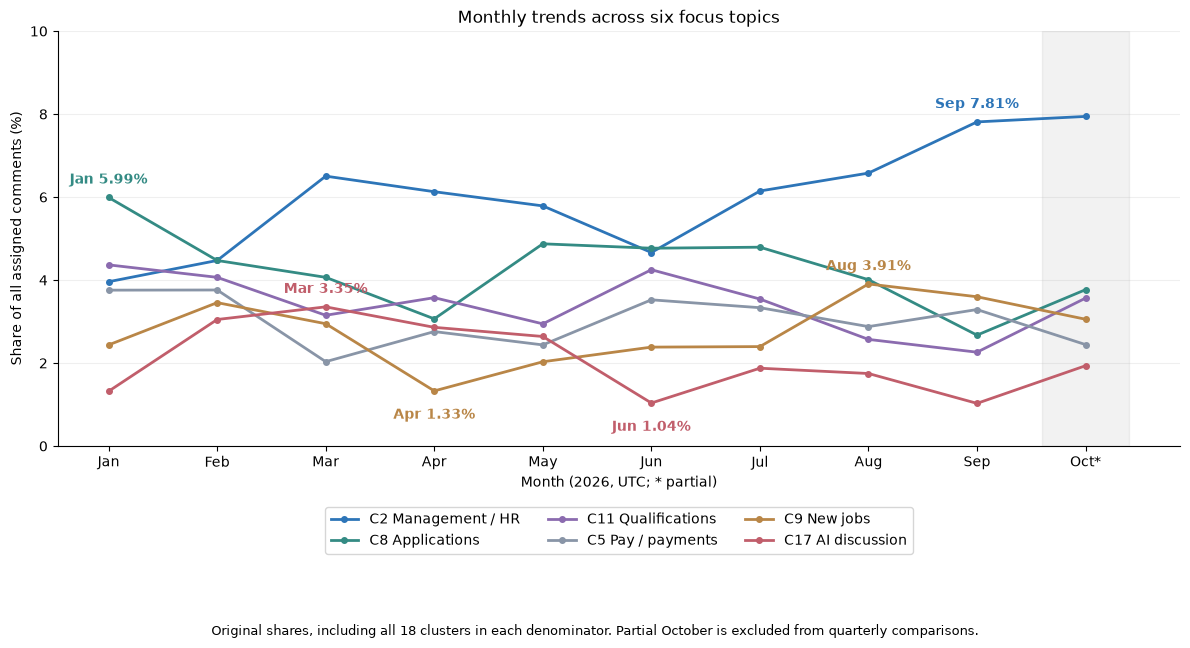

,cluster,month,topic_share,share_pct
0,2,2026-09,0.078109,7.810894
1,8,2026-01,0.059898,5.989848
2,9,2026-04,0.013279,1.327886
3,9,2026-08,0.039054,3.905447
4,17,2026-03,0.033537,3.353659
5,17,2026-06,0.010363,1.036269


,cluster,topic_label,trend_judgment,interpretation_limit
2,2,Manager/HR communication and resignation notice,"Strongest upward display candidate, with mixed...","Communication, recruitment management, leave a..."
5,5,"Pay, pay cuts and payment issues",Broadly stable; useful as a stable-topic refer...,Payment-related meaning is relatively consiste...
8,8,Job applications and opportunities,Declining signal with intermediate rebounds; m...,"Applications, job sources and opportunities co..."
9,9,"Job changes, new jobs and onboarding",Lower April-May and higher August-September; n...,"New work, resignation timing, offers and job-s..."
11,11,"Experience, education and qualifications","Declining signal, with a June rebound and mode...",Experience and education are relatively cohere...
17,17,"AI use, generated content and job substitution",Higher February-May and generally lower after ...,"Content identification, AI use and substitutio..."


In [ ]:
if analysis_ready:
    analysis_colors = {2: '#2D75B8', 8: '#348B84', 11: '#8B6BAF', 5: '#8995A7', 9: '#B98647', 17: '#C15E6B'}
    analysis_short_names = {2: 'Management / HR', 8: 'Applications', 11: 'Qualifications',
                       5: 'Pay / payments', 9: 'New jobs', 17: 'AI discussion'}
    plot_ids = [2, 8, 11, 5, 9, 17]
    analysis_monthly_data = monthly_topics.loc[monthly_topics.cluster.isin(plot_ids)].copy()
    plotted = analysis_monthly_data.pivot(index='month', columns='cluster', values='topic_share').reindex(index=month_order, columns=plot_ids)
    np.testing.assert_array_equal(plotted.to_numpy(), topic_shares.loc[month_order, plot_ids].to_numpy())
    point_specs = [(2, '09', 7.81, 10), (8, '01', 5.99, 10), (9, '04', 1.33, -20),
                   (9, '08', 3.91, 10), (17, '03', 3.35, 10), (17, '06', 1.04, -20)]
    point_rows = []
    fig, ax = plt.subplots(figsize=(12, 6.5))
    x = np.arange(len(month_order))
    for cluster in plot_ids:
        ax.plot(x, plotted[cluster] * 100, 'o-', color=analysis_colors[cluster], linewidth=2,
                markersize=4, label=f'C{cluster} {analysis_short_names[cluster]}')
    for cluster, month_number, expected, offset in point_specs:
        month = f'{YEAR}-{month_number}'
        value = float(plotted.loc[month, cluster]) * 100
        month_name = pd.Timestamp(month + '-01').strftime('%b')
        ax.annotate(f'{month_name} {value:.2f}%', (month_order.index(month), value),
                    xytext=(0, offset), textcoords='offset points', ha='center',
                    color=analysis_colors[cluster], fontsize=10, fontweight='bold')
        point_rows.append({'cluster': cluster, 'month': month, 'topic_share': value / 100, 'share_pct': value})
        check_reference_value(f'C{cluster} {month}: share (%)', value, expected, 2)
    for index, month in enumerate(month_order):
        if month in partial_months:
            ax.axvspan(index - 0.4, index + 0.4, color='grey', alpha=0.1)
    labels = [pd.Timestamp(month + '-01').strftime('%b') + ('*' if month in partial_months else '') for month in month_order]
    ax.set(xticks=x, xticklabels=labels, xlabel=f'Month ({YEAR}, UTC; * partial)',
           ylabel='Share of all assigned comments (%)', ylim=(0, 10), title='Monthly trends across six focus topics')
    ax.grid(axis='y', alpha=0.2)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
    fig.text(0.5, 0.015, 'Original shares, including all 18 clusters in each denominator. Partial October is excluded from quarterly comparisons.',
             ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.10, 1, 1))
    figures['analysis_focus_monthly_trends'] = fig
    plt.show()
    analysis_monthly_points = pd.DataFrame(point_rows)
    display(analysis_monthly_points)
    display(topic_profiles.loc[topic_profiles.cluster.isin(plot_ids), ['cluster', 'topic_label', 'trend_judgment', 'interpretation_limit']])
    analysis_tables['analysis_monthly_data.csv'] = analysis_monthly_data
    analysis_tables['analysis_monthly_key_points.csv'] = analysis_monthly_points

### K-means: Quarterly changes, relative attention and sensitivity

Q1 is January-March and Q3 is July-September. The paired bars compare pooled comment-weighted quarter shares with an alternative that gives each sampled month-post pair total weight one, then averages the three monthly shares in each quarter. The comparison shows how popular posts affect the magnitude and direction of topic changes.

The relative-attention chart divides the C2 comment count by the combined C8+C11 count using complete-quarter totals. This count ratio measures the balance between management/HR communication and applications/qualifications discussion.

Sensitivity ranges recalculate changes after deleting one post or one month-stratum unit independently in each quarter. Text-deduplication results keep one copy of each normalized text key within each month. All topics remain in the denominators, and model assignments stay fixed. These checks quantify dependence on influential observations, rather than population uncertainty, semantic accuracy or labour-market causes.

,cluster,topic_label,first3_share,last3_share,change_pp,equal_post_first3_mean,equal_post_last3_mean,equal_post_change_pp
0,2,Manager/HR communication and resignation notice,0.049780,0.068479,1.869912,0.059532,0.072278,1.274564
1,5,"Pay, pay cuts and payment issues",0.031832,0.031659,-0.017340,0.029964,0.030272,0.030741
2,8,Job applications and opportunities,0.048425,0.038197,-1.022850,0.054913,0.039030,-1.588295
3,9,"Job changes, new jobs and onboarding",0.029462,0.033035,0.357354,0.025998,0.033379,0.738070
4,11,"Experience, education and qualifications",0.038605,0.027873,-1.073144,0.043027,0.035737,-0.729018
5,17,"AI use, generated content and job substitution",0.025737,0.015485,-1.025134,0.024508,0.016833,-0.767492


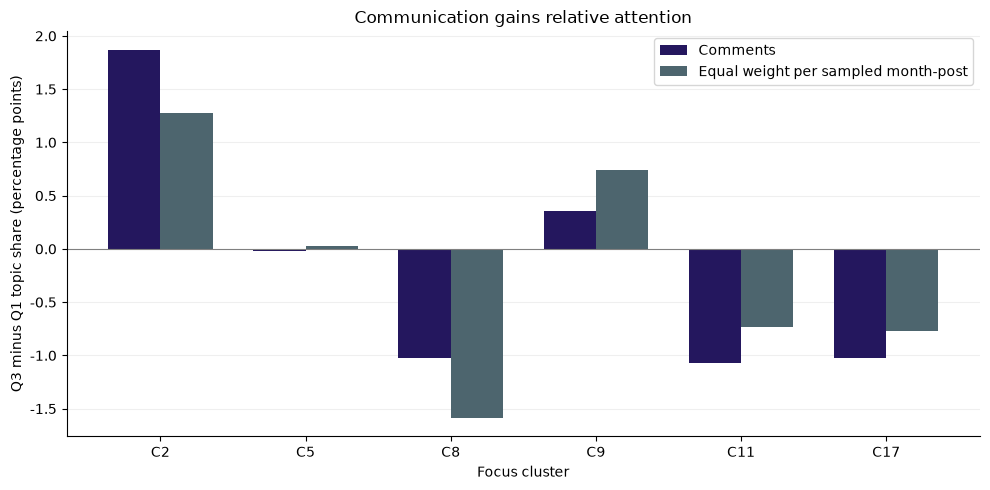

,period,c2_comments,c8_c11_comments,c2_to_c8_c11_ratio
0,Q1,147,257,0.571984
1,Q3,199,192,1.036458


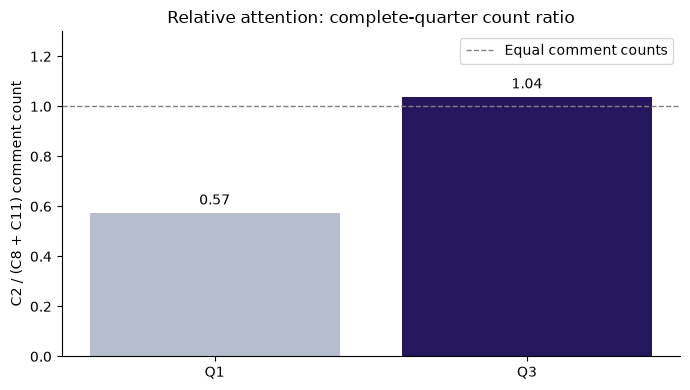

,cluster,first3_share,last3_share,change_pp,equal_post_change_pp,both_periods_available,post_delta_min_pp,post_delta_max_pp,stratum_delta_min_pp,stratum_delta_max_pp,deduplicated_change_pp,topic_label,post_direction_preserved,stratum_direction_preserved
0,2,0.049780,0.068479,1.869912,1.274564,True,1.670492,2.130285,1.588934,2.179637,1.857340,Manager/HR communication and resignation notice,True,True
1,5,0.031832,0.031659,-0.017340,0.030741,True,-0.152419,0.333961,-0.161107,0.328727,-0.027051,"Pay, pay cuts and payment issues",False,False
2,8,0.048425,0.038197,-1.022850,-1.588295,True,-1.181124,-0.667742,-1.219645,-0.694913,-0.902943,Job applications and opportunities,True,True
3,9,0.029462,0.033035,0.357354,0.738070,True,0.066960,0.599225,0.048252,0.640022,0.348880,"Job changes, new jobs and onboarding",True,True
4,11,0.038605,0.027873,-1.073144,-0.729018,True,-1.264615,-0.905765,-1.265908,-0.882874,-1.086373,"Experience, education and qualifications",True,True
5,17,0.025737,0.015485,-1.025134,-0.767492,True,-1.190452,-0.800386,-1.217911,-0.801221,-1.103297,"AI use, generated content and job substitution",True,True


C5 is a near-stable reference. Do not require its tiny change to preserve a positive/negative sign.
Within-month duplicate rows removed for sensitivity only: 23


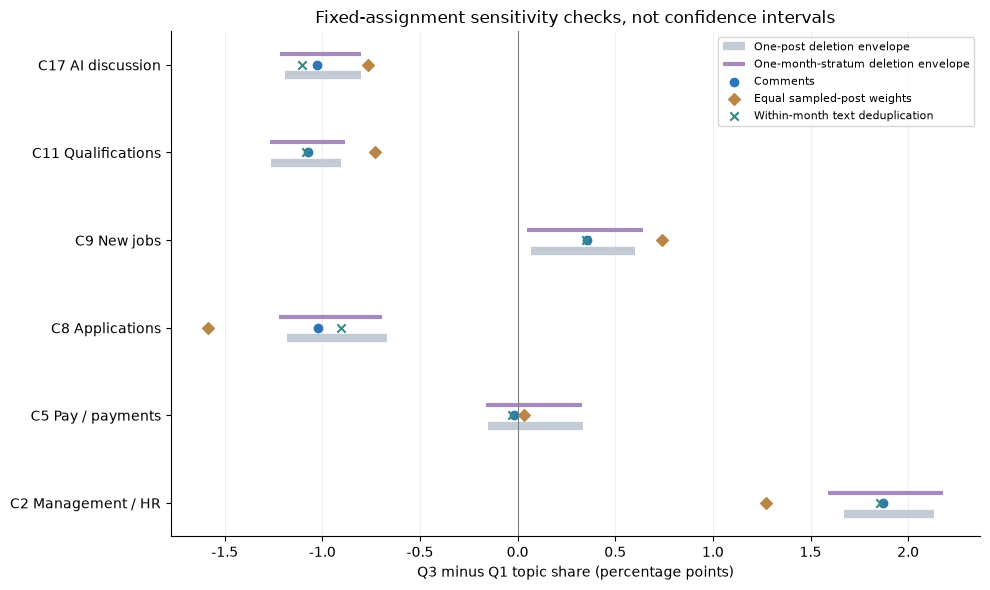

In [ ]:
if analysis_ready:
    analysis_quarter_changes = focus_trend_summary.set_index('cluster').loc[focus_ids, [
        'topic_label', 'first3_share', 'last3_share', 'change_pp',
        'equal_post_first3_mean', 'equal_post_last3_mean', 'equal_post_change_pp']].reset_index()
    display(analysis_quarter_changes)
    check_reference_value('C2: Q3 minus Q1 (percentage points)',
        analysis_quarter_changes.set_index('cluster').loc[2, 'change_pp'], 1.87, 2)
    for cluster, early, late in [(2, 4.98, 6.85), (8, 4.84, 3.82), (11, 3.86, 2.79)]:
        row = analysis_quarter_changes.set_index('cluster').loc[cluster]
        check_reference_value(f'C{cluster}: Q1 share (%)', row.first3_share * 100, early, 2)
        check_reference_value(f'C{cluster}: Q3 share (%)', row.last3_share * 100, late, 2)
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(focus_ids))
    ax.bar(x - 0.18, analysis_quarter_changes.change_pp, width=0.36, color='#24175E', label='Comments')
    ax.bar(x + 0.18, analysis_quarter_changes.equal_post_change_pp, width=0.36, color='#4D656E',
           label='Equal weight per sampled month-post')
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.set(xticks=x, xticklabels=[f'C{cluster}' for cluster in focus_ids],
           xlabel='Focus cluster', ylabel='Q3 minus Q1 topic share (percentage points)',
           title='Communication gains relative attention')
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()
    fig.tight_layout()
    figures['analysis_quarter_changes'] = fig
    plt.show()
    ratio_rows = []
    for period, months in [('Q1', early_months), ('Q3', late_months)]:
        counts = topic_counts.loc[months].sum(axis=0)
        denominator = int(counts.loc[[8, 11]].sum())
        ratio_rows.append({'period': period, 'c2_comments': int(counts.loc[2]),
                           'c8_c11_comments': denominator,
                           'c2_to_c8_c11_ratio': float(counts.loc[2] / denominator) if denominator else np.nan})
    analysis_attention_ratios = pd.DataFrame(ratio_rows)
    for row, expected in zip(ratio_rows, [0.57, 1.04]):
        check_reference_value(row['period'] + ': C2 / (C8 + C11)', row['c2_to_c8_c11_ratio'], expected, 2)
    display(analysis_attention_ratios)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(analysis_attention_ratios.period, analysis_attention_ratios.c2_to_c8_c11_ratio, color=['#B6BDCC', '#24175E'])
    ax.bar_label(bars, fmt='%.2f', padding=4)
    ax.axhline(1, color='grey', linestyle='--', linewidth=1, label='Equal comment counts')
    ax.set(ylabel='C2 / (C8 + C11) comment count', ylim=(0, 1.3), title='Relative attention: complete-quarter count ratio')
    ax.legend()
    fig.tight_layout()
    figures['analysis_attention_ratio'] = fig
    plt.show()
    analysis_sensitivity = topic_period_sensitivity(model_df, coverage[['month', 'partial_month']],
                                               early_months, late_months, focus_ids)
    analysis_sensitivity = analysis_sensitivity.merge(topic_profiles[['cluster', 'topic_label']], on='cluster', validate='one_to_one')
    for unit in ['post', 'stratum']:
        lo, hi = analysis_sensitivity[unit + '_delta_min_pp'], analysis_sensitivity[unit + '_delta_max_pp']
        analysis_sensitivity[unit + '_direction_preserved'] = (
            (analysis_sensitivity.change_pp.gt(0) & lo.gt(0)) | (analysis_sensitivity.change_pp.lt(0) & hi.lt(0)))
    changing = analysis_sensitivity.set_index('cluster').loc[[2, 8, 9, 11, 17]]
    for method in ['post', 'stratum']:
        check_reference_value(method + ': changing topics retain direction',
            changing[method + '_direction_preserved'].all(), 1, 0)
    for method in ['equal_post_change_pp', 'deduplicated_change_pp']:
        check_reference_value(method + ': changing topics retain direction',
            np.array_equal(np.sign(changing[method]), np.sign(changing.change_pp)), 1, 0)
    display(analysis_sensitivity)
    print('C5 is a near-stable reference. Do not require its tiny change to preserve a positive/negative sign.')
    print('Within-month duplicate rows removed for sensitivity only:',
          len(model_df) - len(model_df.drop_duplicates(['month', 'normalized_text_key'])))
    fig, ax = plt.subplots(figsize=(10, 6))
    y = np.arange(len(focus_ids))
    ax.hlines(y - 0.12, analysis_sensitivity.post_delta_min_pp, analysis_sensitivity.post_delta_max_pp,
              color='#C3CBD7', linewidth=6, label='One-post deletion envelope')
    ax.hlines(y + 0.12, analysis_sensitivity.stratum_delta_min_pp, analysis_sensitivity.stratum_delta_max_pp,
              color='#A78ABD', linewidth=3, label='One-month-stratum deletion envelope')
    ax.scatter(analysis_sensitivity.change_pp, y, color='#2D75B8', label='Comments', zorder=3)
    ax.scatter(analysis_sensitivity.equal_post_change_pp, y, color='#B98647', marker='D', label='Equal sampled-post weights', zorder=3)
    ax.scatter(analysis_sensitivity.deduplicated_change_pp, y, color='#348B84', marker='x', label='Within-month text deduplication', zorder=3)
    ax.axvline(0, color='grey', linewidth=0.8)
    ax.set(yticks=y, yticklabels=[f'C{cluster} {analysis_short_names[cluster]}' for cluster in focus_ids],
           xlabel='Q3 minus Q1 topic share (percentage points)',
           title='Fixed-assignment sensitivity checks, not confidence intervals')
    ax.legend(fontsize=8, loc='best')
    ax.grid(axis='x', alpha=0.2)
    fig.tight_layout()
    figures['analysis_period_sensitivity'] = fig
    plt.show()
    analysis_tables['analysis_quarter_changes.csv'] = analysis_quarter_changes
    analysis_tables['analysis_attention_ratios.csv'] = analysis_attention_ratios
    analysis_tables['analysis_period_sensitivity.csv'] = analysis_sensitivity

### K-means: Output availability and numerical consistency

The inventory lists the content, location and availability of each analytical output. It shows where each figure and table of this section comes from.

Numerical consistency checks compare recomputed statistics with a frozen reference snapshot at the reported precision. The reference values validate reproducibility; chart values are calculated from the verified corpus, model or recorded experiment.

In [ ]:
analysis_output_inventory = pd.DataFrame([
    {'analysis': 'Corpus and settings', 'content': 'Sample size, exclusions and model settings', 'section': '12.2', 'available': analysis_ready,
     'outputs': 'analysis_data_counts.csv; analysis_model_settings.csv'},
    {'analysis': 'Dimensions and k', 'content': 'PCA 50/100/200/400, dimension grid and k diagnostics', 'section': '8, 12.2', 'available': analysis_pca_ready,
     'outputs': 'analysis_pca_dimensions.png; analysis_dimension_separation.png; analysis_dimension_candidates.csv; analysis_k_selection.csv'},
    {'analysis': 'Cluster profiles', 'content': 'All 18 shares, focus/mixed proportions, silhouettes and naming examples', 'section': '12.3', 'available': analysis_ready,
     'outputs': 'analysis_cluster_shares.png; analysis_naming_evidence.csv; analysis_naming_examples.csv'},
    {'analysis': 'Monthly trends', 'content': 'Combined six-topic monthly trends and labelled data points', 'section': '12.4', 'available': analysis_ready,
     'outputs': 'analysis_focus_monthly_trends.png; analysis_monthly_data.csv; analysis_monthly_key_points.csv'},
    {'analysis': 'Quarterly sensitivity', 'content': 'Quarterly bars, count ratio, post/stratum/text sensitivity', 'section': '12.5', 'available': analysis_ready,
     'outputs': 'analysis_quarter_changes.png; analysis_attention_ratio.png; analysis_period_sensitivity.png'},
])
display(analysis_output_inventory)
analysis_reference_checks = pd.DataFrame(analysis_check_rows)
if analysis_ready:
    display(analysis_reference_checks)
    if not analysis_reference_checks.passed.all():
        raise ValueError('A recomputed metric differs from the frozen reference at the reported precision.')
    if not analysis_output_inventory.available.all():
        print('Some analysis outputs are unavailable; restore the missing comparison sources listed above.')
    else:
        print('All analysis outputs are available and all numerical consistency checks passed.')
    analysis_tables['analysis_output_inventory.csv'] = analysis_output_inventory
    analysis_tables['analysis_reference_checks.csv'] = analysis_reference_checks
    analysis_tables['analysis_source_provenance.csv'] = pd.DataFrame(analysis_sources)

,analysis,content,section,available,outputs
0,Corpus and settings,"Sample size, exclusions and model settings",12.2,True,analysis_data_counts.csv; analysis_model_setti...
1,Dimensions and k,"PCA 50/100/200/400, dimension grid and k diagn...","8, 12.2",True,analysis_pca_dimensions.png; analysis_dimensio...
2,Cluster profiles,"All 18 shares, focus/mixed proportions, silhou...",12.3,True,analysis_cluster_shares.png; analysis_naming_e...
3,Monthly trends,Combined six-topic monthly trends and labelled...,12.4,True,analysis_focus_monthly_trends.png; analysis_mo...
4,Quarterly sensitivity,"Quarterly bars, count ratio, post/stratum/text...",12.5,True,analysis_quarter_changes.png; analysis_attenti...


,result,recomputed,reference_value,decimals,passed
0,Sampled comments,10000.000000,10000.00000,0,True
1,Assigned comments,9770.000000,9770.00000,0,True
2,Excluded moderation notices,106.000000,106.00000,0,True
3,Excluded zero-feature comments,124.000000,124.00000,0,True
4,k=20 scores above k=18 in the selected PCA space,1.000000,1.00000,0,True
5,PCA 50: retained variance (%),8.708597,8.70000,1,True
6,PCA 100: retained variance (%),14.405203,14.40000,1,True
7,PCA 200: retained variance (%),22.874829,22.90000,1,True
8,PCA 400: retained variance (%),34.801760,34.80000,1,True
9,Six focus clusters: assigned share (%),21.535312,21.54000,2,True


All analysis outputs are available and all numerical consistency checks passed.


### K-means: Interpretation and limitations

Increasing components raises retained TF-IDF variance, not guaranteed semantic coverage. Row normalization reduces some size/length effects without guaranteeing one clear topic per comment.
Relative centroid margins indicate ambiguity, not classification probability. No low-margin comments are removed to improve monthly curves.

The 18 labels are assistant suggestions pending human review. They are bound to the verified assignments, and new fits do not inherit names by cluster ID.
The six requested cases preserve original confidence ratings: C2 rises, C5 is stable, C8/C11 show declining signals, C9 recovers after a middle-period low, and C17 shows a phase-dependent decline. This is exploratory case selection, not an independently validated ranking.

- **Hiding C7 changes the chart only.** All remaining values and denominators are preserved. The shared linear scale uses the 17 visible topics; column sums need not equal 100%. The model has not eliminated the mixed cluster.
- **Relative shares and small samples.** Fixed quotas do not estimate absolute subreddit volume. One topic's share can fall when others rise. C17 has about 10-33 and C9 about 13-38 comments per complete month; changes are not counts of real-world events.
- **Sampling and dependence.** Public-archive random-anchor candidates are not a simple random sample of a complete month. Comments within a post are related. Equal-post and time-block checks do not remove all source bias or provide population confidence intervals.
- **Model and label uncertainty.** Original TF-IDF cosine silhouette is about 0.0083 and initialization ARI about 0.60-0.68. C7+C12 still account for about 42.4% and lack a single theme. Qualitative labels need independent review.
- **Time and external validity.** October is partial and excluded from full-quarter comparisons. AI content identification and tool use are not identical to job-loss anxiety; no clear layoff cluster supports a direct layoffs.fyi indicator.

For the frozen model, C9 changes from about 2.95% to 3.30% and C17 from about 2.57% to 1.55% between the first and third quarters. Interpret these as sample discussion patterns, with the stated phase changes and limitations.

Reference: [scikit-learn text clustering example](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html). Its normalization example uses SVD; this project separately evaluates true centered PCA.

## A4. LDA: topics as mixtures (slides 17-22)
LDA gives every comment a weight for each of 10 topics, so one comment can contribute to several of them. It was fitted on raw word counts of the same corpus (9,660 usable comments, 8,058 terms, protected phrases such as "laid off"), with K = 10 chosen by the highest mean NPMI coherence among six settings; a second fit with another seed (7) checks which topics are stable. **The tables below are read from the shipped exports in `dataset/monthly_Topics/lda/`**: they are the numbers on the slides. The model saved in `models/topics_lda/` is a refit under another library version that gives different topics, so it is not used for any number here.

### LDA: Choosing K
Results of the K comparison run on 2026-10-31 (seeds 42 and 7, up to 200 iterations). Set `RUN_K_DIAGNOSTICS = True` to recompute them (about 15 minutes).

| K | NPMI mean | NPMI min | Topic diversity | Topic stability, mean / min | Comment ARI |
|---|---|---|---|---|---|
| 8 | 0.107 | 0.036 | 0.85 | 0.62 / 0.53 | 0.02 |
| **10** | **0.113** | **0.060** | 0.83 | 0.54 / 0.39 | 0.02 |
| 12 | 0.106 | 0.018 | 0.82 | 0.53 / 0.32 | 0.02 |
| 15 | 0.092 | −0.053 | 0.77 | 0.49 / 0.28 | 0.02 |
| 18 | 0.079 | −0.117 | 0.78 | 0.46 / 0.30 | 0.01 |
| 20 | 0.051 | −0.186 | 0.77 | 0.49 / 0.33 | 0.01 |

- **NPMI** (coherence): how much more often a topic's top 10 words appear together than by chance; around 0 means unrelated words.
- **Topic diversity**: share of distinct words among all topics' top 10 words; low values mean topics repeat the same words.
- **Topic stability**: cosine similarity of each topic's word distribution with its best match in the seed-7 fit.
- **Comment ARI**: agreement of each comment's top topic between the two seeds (0 = chance).

K = 10 has the highest average coherence among the six tested settings. Some topics still combine several kinds of replies. K = 8 is more stable but its topics are broader, and from K = 15 some topics have negative coherence. Comment ARI is near 0 for every K: comments are short, so single-comment assignments are not reliable and the trends below use soft shares.

,k,npmi_mean,npmi_min,topic_diversity,stability_mean,stability_min,comment_ari
0,8,0.107,0.036,0.85,0.62,0.53,0.02
1,10,0.113,0.060,0.83,0.54,0.39,0.02
2,12,0.106,0.018,0.82,0.53,0.32,0.02
3,15,0.092,-0.053,0.77,0.49,0.28,0.02
4,18,0.079,-0.117,0.78,0.46,0.30,0.01
5,20,0.051,-0.186,0.77,0.49,0.33,0.01


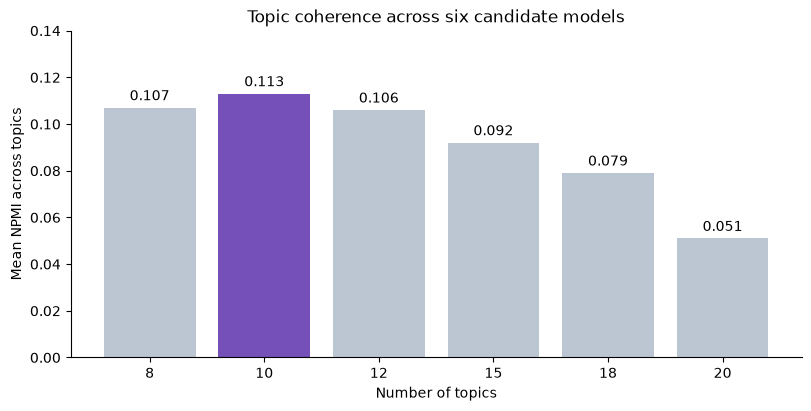

In [ ]:
RUN_K_DIAGNOSTICS = False  # the six-K comparison takes about 15 minutes; its recorded results are used
# This cell also runs on its own using the recorded diagnostics.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Recorded diagnostics from 2026-10-31, rounded to three decimals.
# NPMI is averaged across topics in the seed-42 model.
k_diagnostics = pd.DataFrame({
    'k': [8, 10, 12, 15, 18, 20],
    'npmi_mean': [0.107, 0.113, 0.106, 0.092, 0.079, 0.051],
    'npmi_min': [0.036, 0.060, 0.018, -0.053, -0.117, -0.186],
    'topic_diversity': [0.85, 0.83, 0.82, 0.77, 0.78, 0.77],
    'stability_mean': [0.62, 0.54, 0.53, 0.49, 0.46, 0.49],
    'stability_min': [0.53, 0.39, 0.32, 0.28, 0.30, 0.33],
    'comment_ari': [0.02, 0.02, 0.02, 0.02, 0.01, 0.01],
})

if globals().get('RUN_K_DIAGNOSTICS', False):
    rows = []
    for k in [8, 10, 12, 15, 18, 20]:
        fits = [LatentDirichletAllocation(n_components=k, learning_method='batch', max_iter=MAX_ITER,
                                          evaluate_every=10, random_state=s, n_jobs=-1)
                for s in (SEED, CHECK_SEED)]
        thetas = [m.fit_transform(counts) for m in fits]
        k_coherence = topic_coherence(fits[0].components_, counts)
        k_matched = match_topics(fits[0].components_, fits[1].components_)
        top10 = [terms[w.argsort()[::-1][:10]] for w in fits[0].components_]
        rows.append({
            'k': k, 'npmi_mean': k_coherence['npmi'].mean(), 'npmi_min': k_coherence['npmi'].min(),
            'topic_diversity': len(set(np.concatenate(top10))) / (10 * k),
            'stability_mean': k_matched['cosine'].mean(), 'stability_min': k_matched['cosine'].min(),
            'comment_ari': adjusted_rand_score(thetas[0].argmax(1), thetas[1].argmax(1)),
        })
    k_diagnostics = pd.DataFrame(rows)

display(k_diagnostics.round(3))
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
bars = ax.bar(k_diagnostics['k'].astype(str), k_diagnostics['npmi_mean'],
              color=['#7450B8' if k == 10 else '#BCC6D2' for k in k_diagnostics['k']])
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(xlabel='Number of topics', ylabel='Mean NPMI across topics',
       title='Topic coherence across six candidate models', ylim=(0, 0.14))
k_figure_dir = OUT_DIR / 'lda' / 'figures'
k_figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(k_figure_dir / 'topic_count_coherence.png', dpi=160, bbox_inches='tight')
plt.show()

### LDA: Additional analyses of the fitted LDA model

This section uses the saved comment-level topic weights to examine the fitted
model from four perspectives:

1. the overall distribution of topic weights;
2. the relationship between the LDA topics and the K-means clusters;
3. changes in topic weights between the first and third quarters; and
4. the sensitivity of these changes to popular posts and the random seed.

These analyses use the comment-level topic weights in the shipped LDA exports, so no LDA model is fitted here.

The regenerated tables are saved under `outputs/lda/analysis/` and the figures under `outputs/lda/figures/`; A6 compares them with the shipped tables.

In [ ]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

analysis_root = ROOT
topic_dir = analysis_root / 'dataset/monthly_Topics'
lda_dir = topic_dir / 'lda'
analysis_dir = OUT_DIR / 'lda' / 'analysis'
analysis_fig_dir = OUT_DIR / 'lda' / 'figures'
analysis_dir.mkdir(parents=True, exist_ok=True)
analysis_fig_dir.mkdir(parents=True, exist_ok=True)

lda_metadata = json.loads((lda_dir / 'lda_run.json').read_text(encoding='utf-8'))
input_hash = hashlib.sha256((topic_dir / 'comments_clean.csv').read_bytes()).hexdigest()
assert input_hash == lda_metadata['input_sha256'], 'Sample changed; regenerate the LDA exports.'
assert lda_metadata['k'] == 10 and lda_metadata['seed'] == 42
assert lda_metadata['check_seed'] == 7

analysis_corpus = pd.read_csv(topic_dir / 'comments_clean.csv',
                              dtype={'comment_id': str, 'link_id': str}, keep_default_na=False)
analysis_weights = pd.read_csv(lda_dir / 'lda_comment_topics.csv', dtype={'comment_id': str})
analysis_profiles = pd.read_csv(lda_dir / 'lda_topic_profiles.csv').set_index('topic')
analysis_monthly = pd.read_csv(lda_dir / 'lda_monthly_shares.csv')
analysis_kmeans = pd.read_csv(topic_dir / 'comment_topics.csv', dtype={'comment_id': str})
topic_columns = [f'topic_{t}' for t in range(10)]
assert analysis_weights['comment_id'].is_unique
assert set(analysis_weights['comment_id']) == set(analysis_corpus['comment_id'])
analysis_docs = analysis_weights.loc[analysis_weights['lda_status'].eq('modelled')].merge(
    analysis_corpus[['comment_id', 'month', 'link_id', 'text']],
    on=['comment_id', 'month'], how='left', validate='one_to_one', indicator=True,
)
assert analysis_docs['_merge'].eq('both').all()
assert analysis_docs['link_id'].notna().all() and analysis_docs['link_id'].ne('').all()
assert len(analysis_docs) == lda_metadata['modelled_comments']
assert np.isfinite(analysis_docs[topic_columns]).all().all()
assert (analysis_docs[topic_columns] >= 0).all().all()
np.testing.assert_allclose(analysis_docs[topic_columns].sum(axis=1), 1, atol=1e-8)

topic_names = {
    0: 'Workplace & services', 1: 'Job search & AI', 2: 'Changing jobs',
    3: 'Pay & qualifications', 4: 'Leave & managers', 5: 'Personal stories',
    6: 'Hiring process', 7: 'Life advice', 8: 'Advice & encouragement',
    9: 'Economy & unemployment',
}
topic_colors = {t: '#92A4B7' for t in range(10)}
topic_colors.update({t: '#BCC6D2' for t in [0, 5, 7]})
topic_colors.update({2: '#087F72', 3: '#3D79A5', 6: '#7450B8', 9: '#BB6E2B'})
mixed_topics = [0, 5, 7]
early_months = ['2026-01', '2026-02', '2026-03']
late_months = ['2026-07', '2026-08', '2026-09']


def save_analysis_figure(fig, filename):
    fig.savefig(analysis_fig_dir / filename, dpi=160, bbox_inches='tight')
    plt.show()


model_counts = pd.Series({
    'sample_comments': len(analysis_corpus),
    'modelled_comments': len(analysis_docs),
    'excluded_comments': len(analysis_corpus) - len(analysis_docs),
    'vocabulary_size': lda_metadata['vocabulary_size'],
    'topics': lda_metadata['k'],
    'seed_42_iterations': lda_metadata['iterations'][0],
    'seed_7_iterations': lda_metadata['iterations'][1],
}, name='count')
display(model_counts.to_frame())
display(analysis_corpus.groupby('month').size().rename('sample_comments').to_frame())

,count
sample_comments,10000
modelled_comments,9660
excluded_comments,340
vocabulary_size,8058
topics,10
seed_42_iterations,159
seed_7_iterations,200


,sample_comments
month,
2026-01,1000
2026-02,1000
2026-03,1000
2026-04,1000
2026-05,1000
2026-06,1000
2026-07,1000
2026-08,1000
2026-09,1000


### LDA: Comparing a single assignment with topic weights

To illustrate the difference between the two topic representations, retrieve one
comment by ID and compare its K-means cluster with its LDA topic weights. K-means
assigns the complete comment to one cluster, whereas LDA distributes its weight
across all ten topics.

The chart displays the two largest interpretable topic weights separately and
combines the remaining weights as `Other topics`. This example explains how a
comment with more than one theme contributes to the monthly LDA averages.

Went back to corporate in 2024. Took a horribly underpaid position for remote until my other job prospect that was in the pipeline came through. Went to that job which was hybrid Jan 2025 as company (large insurance) heavily focused on hybrid and RTO in that particular sector of the business. 

Took a new position in same company last month, remote but one day a month required badge swipe at local campus. It was a mixture of timing, luck, referrals and internal job posting. Current role pays just a smidge over 100k. 
K-means C6: Company evaluations and employment processes


,weight_pct
T2 Changing jobs,48.058
T3 Pay & qualifications,50.203
Other topics,1.740


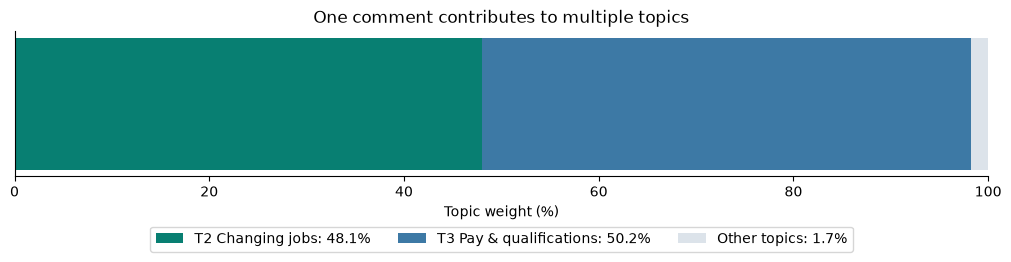

In [ ]:
example_id = 'p882nzc'
example_comment = analysis_docs.set_index('comment_id').loc[example_id]
example_cluster = analysis_kmeans.set_index('comment_id').loc[example_id]
print(example_comment['text'])
print(f"K-means C{int(example_cluster['cluster'])}: {example_cluster['topic_label']}")
example_mix = pd.Series({
    'T2 Changing jobs': example_comment['topic_2'] * 100,
    'T3 Pay & qualifications': example_comment['topic_3'] * 100,
    'Other topics': (1 - example_comment['topic_2'] - example_comment['topic_3']) * 100,
}, name='weight_pct')
display(example_mix.to_frame().round(3))
fig, ax = plt.subplots(figsize=(10, 2.5), layout='constrained')
left = 0
for (label, value), color in zip(example_mix.items(), ['#087F72', '#3D79A5', '#DCE3EA']):
    ax.barh(0, value, left=left, color=color, label=f'{label}: {value:.1f}%')
    left += value
ax.set(xlim=(0, 100), yticks=[], xlabel='Topic weight (%)',
       title='One comment contributes to multiple topics')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3)
save_analysis_figure(fig, 'comment_topic_mix.png')
example_mix.to_csv(analysis_dir / 'example_topic_weights.csv')

### LDA: Overall topic composition

Calculate each topic's overall share as its mean weight across all modelled
comments. Because every comment's topic weights sum to one, the ten mean weights
also sum to one. This provides a common baseline for comparing topic prevalence
and for interpreting the cluster-level averages in the next section.

The table also includes each topic's coherence, matched similarity across random
seeds and three keyword cues taken from its saved top-word list. T0, T5 and T7
retain the `Mixed` designation assigned during topic interpretation; their
combined share is calculated separately to describe how much weight falls on
these broader profiles.

,name,share_pct,keyword_cues,npmi,matched_similarity
topic,,,,,
0,Workplace & services,8.508,"office, business, customer",0.081,0.453
1,Job search & AI,11.299,"ai, interview, hiring",0.060,0.468
2,Changing jobs,11.372,"offer, notice, new_job",0.133,0.684
3,Pay & qualifications,12.154,"experience, hours, pay",0.143,0.685
4,Leave & managers,10.069,"boss, pto, leave",0.098,0.599
5,Personal stories,9.615,"manager, school, test",0.096,0.465
6,Hiring process,9.390,"resume, background, recruiter",0.188,0.689
7,Life advice,9.368,"skills, world, family",0.080,0.464
8,Advice & encouragement,9.292,"best, luck, advice",0.129,0.507


Topic shares range from 8.5% to 12.2%.
Mixed-topic weight: 27.49%.


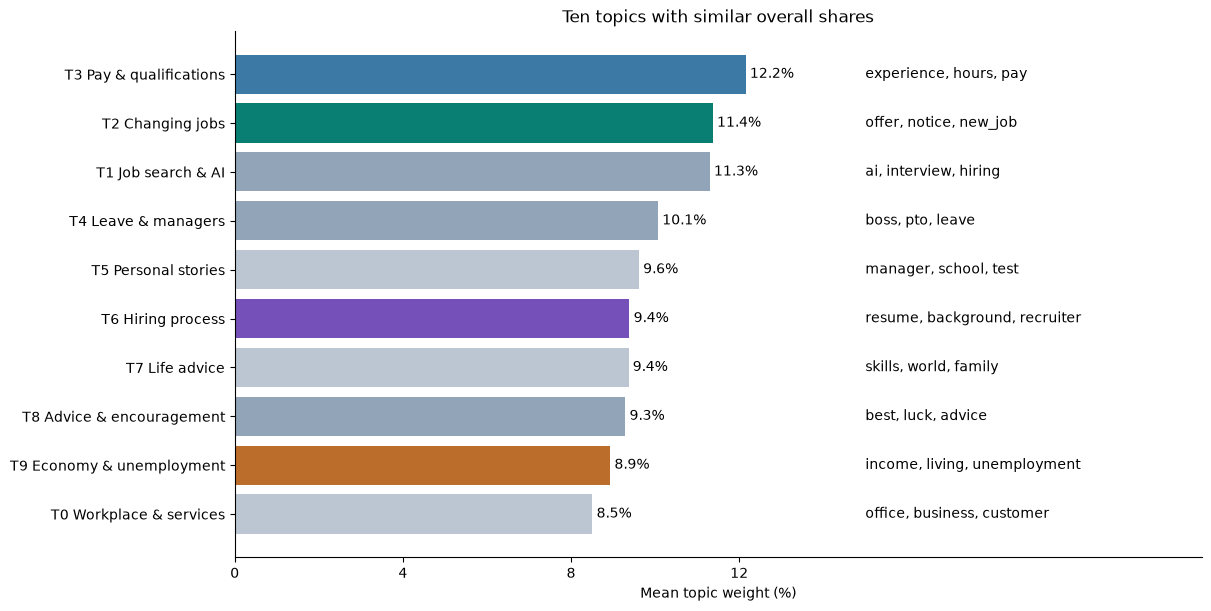

In [ ]:
overall_weights = analysis_docs[topic_columns].mean()
overall_weights.index = range(10)
np.testing.assert_allclose(overall_weights, analysis_profiles.loc[range(10), 'share'])
keyword_cues = {
    0: ['office', 'business', 'customer'], 1: ['ai', 'interview', 'hiring'],
    2: ['offer', 'notice', 'new_job'], 3: ['experience', 'hours', 'pay'],
    4: ['boss', 'pto', 'leave'], 5: ['manager', 'school', 'test'],
    6: ['resume', 'background', 'recruiter'], 7: ['skills', 'world', 'family'],
    8: ['best', 'luck', 'advice'], 9: ['income', 'living', 'unemployment'],
}
for topic, cues in keyword_cues.items():
    assert set(cues) <= set(analysis_profiles.loc[topic, 'top_words'].split(', '))
topic_overview = pd.DataFrame({
    'name': pd.Series(topic_names), 'share_pct': overall_weights * 100,
    'keyword_cues': pd.Series({t: ', '.join(cues) for t, cues in keyword_cues.items()}),
    'npmi': analysis_profiles['npmi'], 'matched_similarity': analysis_profiles['stability'],
}).rename_axis('topic')
display(topic_overview.round(3))
print(f'Topic shares range from {overall_weights.min():.1%} to {overall_weights.max():.1%}.')
print(f'Mixed-topic weight: {overall_weights.loc[mixed_topics].sum():.2%}.')

ordered_topics = overall_weights.sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
bars = ax.barh(range(10), overall_weights.loc[ordered_topics] * 100,
               color=[topic_colors[t] for t in ordered_topics])
ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_yticks(range(10), [f'T{t} {topic_names[t]}' for t in ordered_topics])
for y, topic in enumerate(ordered_topics):
    ax.text(15, y, ', '.join(keyword_cues[topic]), va='center', fontsize=10)
ax.invert_yaxis()
ax.set(xlim=(0, 23), xlabel='Mean topic weight (%)',
       title='Ten topics with similar overall shares')
ax.set_xticks([0, 4, 8, 12])
save_analysis_figure(fig, 'topic_composition.png')
topic_overview.to_csv(analysis_dir / 'topic_composition.csv')

### LDA: Content correspondence with K-means

Join the K-means and LDA outputs by `comment_id`. For each K-means cluster,
average the ten LDA topic weights of its comments. Each row therefore describes
the internal topic composition of one K-means cluster and sums to 100%.

Add the overall topic weights as a baseline. An enrichment ratio divides a
cluster's topic weight by the corresponding overall weight, making it possible
to distinguish a cluster-specific concentration from a topic that is common
throughout the corpus.

The selected heatmap shows four clusters used for detailed interpretation, while
the two full heatmaps retain all 18 clusters. For the AI cluster, T1 and T9 are
also added together to examine how its weight is distributed across job-search
and economic topic profiles. This combined value is a topic-weight total, not a
percentage of comments about a specific AI effect.

,0,1,2,3,4,5,6,7,8,9
C9 Changing jobs,7.7,11.3,21.9,10.8,13.1,8.1,3.1,4.9,12.5,6.6
C11 Qualifications,8.2,11.1,6.1,29.2,5.6,4.8,8.2,6.7,11.9,8.2
C17 AI cluster,4.9,34.0,3.2,6.2,2.5,4.7,8.7,7.7,5.3,22.8
C7 General replies,8.5,10.5,11.6,10.0,9.9,9.8,10.1,10.4,10.1,9.1
All comments,8.5,11.3,11.4,12.2,10.1,9.6,9.4,9.4,9.3,8.9


,value
C9 T2 / overall T2,1.926
C11 T3 / overall T3,2.400
C17 T1 weight (%),34.032
C17 T9 weight (%),22.839
C17 T1 + T9 weight (%),56.871


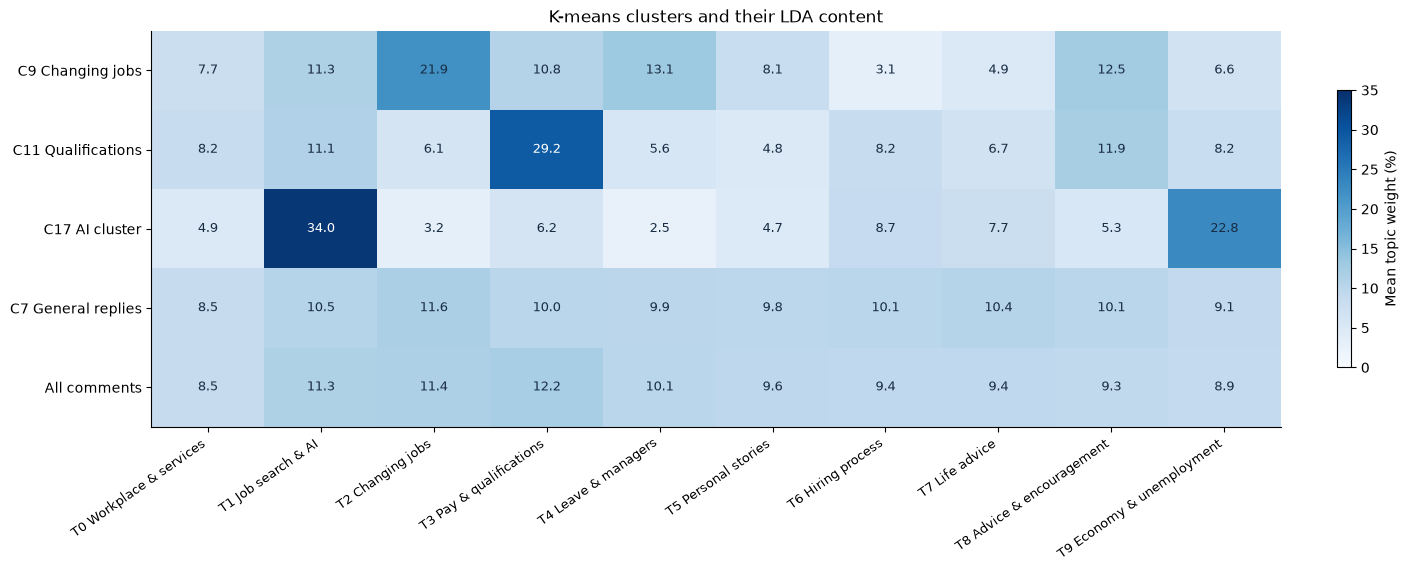

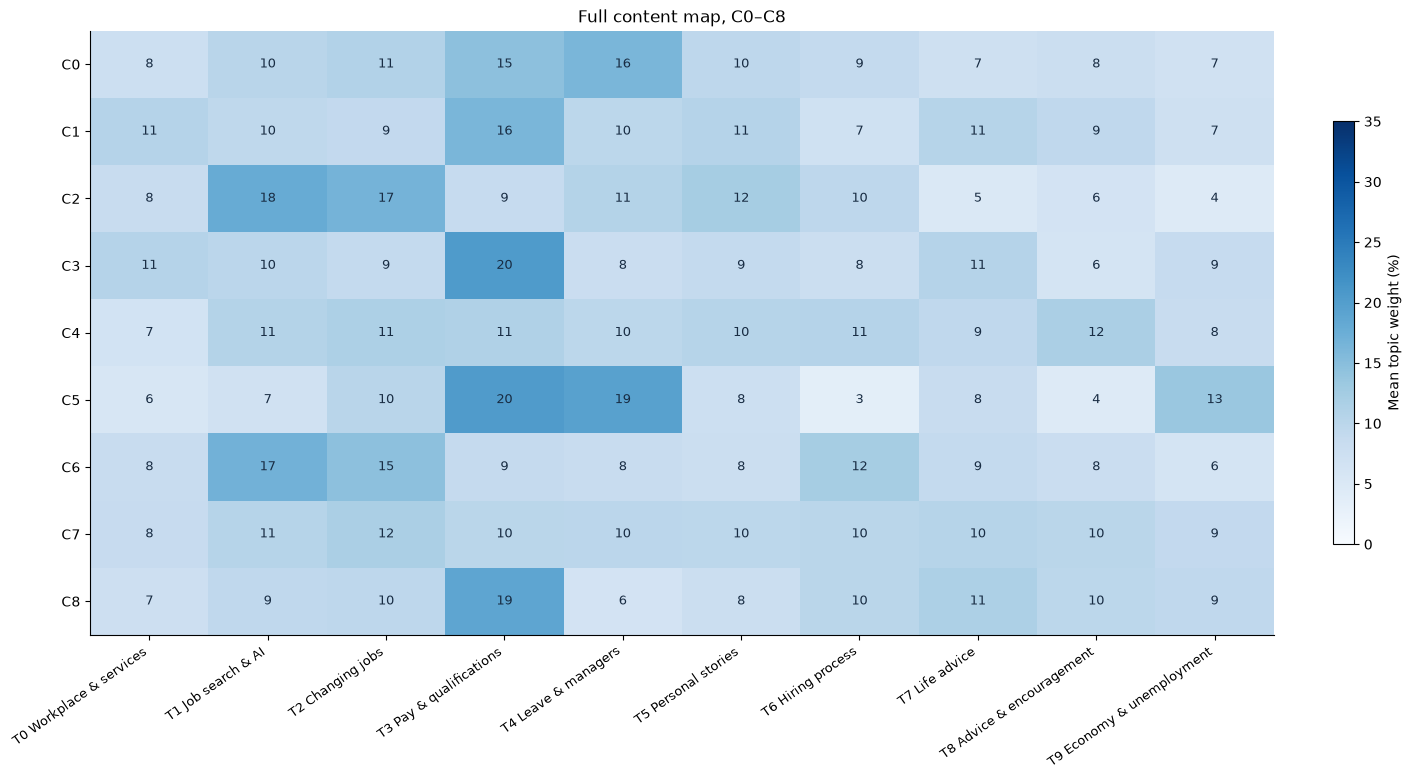

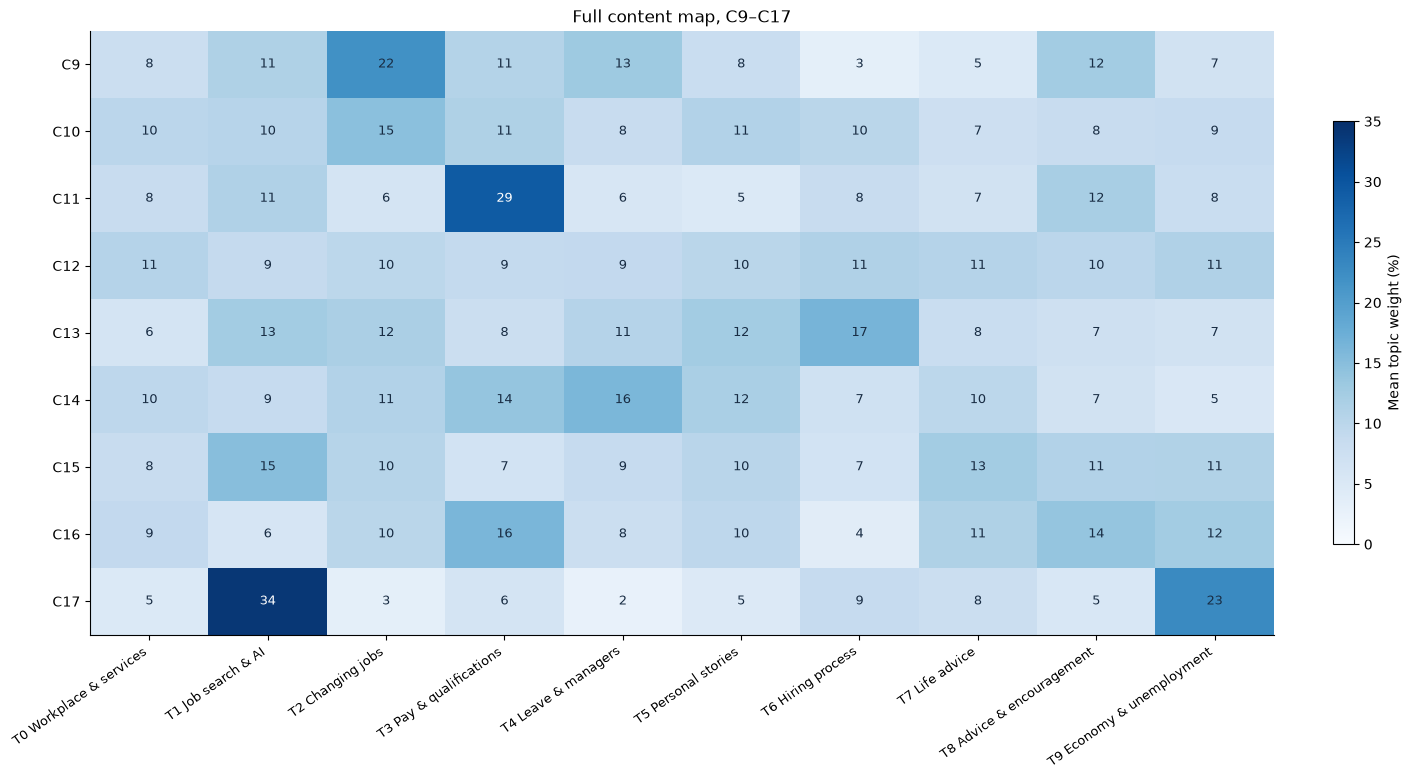

In [ ]:
cross_model = analysis_docs[['comment_id'] + topic_columns].merge(
    analysis_kmeans[['comment_id', 'cluster']], on='comment_id',
    how='left', validate='one_to_one', indicator=True,
)
assert cross_model['_merge'].eq('both').all() and cross_model['cluster'].notna().all()
cross_model['cluster'] = cross_model['cluster'].astype(int)
cluster_mix = cross_model.groupby('cluster')[topic_columns].mean() * 100
cluster_mix.columns = range(10)
np.testing.assert_allclose(cluster_mix.sum(axis=1), 100)
selected_mix = cluster_mix.loc[[9, 11, 17, 7]].copy()
selected_mix.index = ['C9 Changing jobs', 'C11 Qualifications', 'C17 AI cluster', 'C7 General replies']
selected_mix.loc['All comments'] = overall_weights * 100
display(selected_mix.round(1))
enrichment = pd.Series({
    'C9 T2 / overall T2': cluster_mix.loc[9, 2] / (overall_weights[2] * 100),
    'C11 T3 / overall T3': cluster_mix.loc[11, 3] / (overall_weights[3] * 100),
    'C17 T1 weight (%)': cluster_mix.loc[17, 1],
    'C17 T9 weight (%)': cluster_mix.loc[17, 9],
    'C17 T1 + T9 weight (%)': cluster_mix.loc[17, [1, 9]].sum(),
}, name='value')
display(enrichment.round(3).to_frame())


def plot_content_mix(table, title, filename, decimals=1):
    fig, ax = plt.subplots(figsize=(14, 0.52 * len(table) + 3), layout='constrained')
    image = ax.imshow(table, aspect='auto', cmap='Blues', vmin=0, vmax=35)
    ax.set_xticks(range(10), [f'T{t} {topic_names[t]}' for t in range(10)],
                  rotation=35, ha='right', fontsize=9)
    ax.set_yticks(range(len(table)), table.index)
    for row in range(len(table)):
        for column in range(10):
            value = table.iloc[row, column]
            ax.text(column, row, f'{value:.{decimals}f}', ha='center', va='center',
                    color='white' if value > 23 else '#182C43', fontsize=9)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label='Mean topic weight (%)', shrink=0.7)
    save_analysis_figure(fig, filename)


plot_content_mix(selected_mix, 'K-means clusters and their LDA content', 'selected_content_heatmap.png')
for first, last in [(0, 8), (9, 17)]:
    block = cluster_mix.loc[first:last].rename(index=lambda cluster: f'C{cluster}')
    plot_content_mix(block, f'Full content map, C{first}–C{last}',
                     f'full_content_heatmap_c{first}_c{last}.png', decimals=0)
cluster_mix.to_csv(analysis_dir / 'cluster_topic_weights_pct.csv')
enrichment.to_csv(analysis_dir / 'cluster_enrichment.csv')

### LDA: Quarterly changes and their scale

Average the monthly topic weights for January–March and July–September. Giving
each month equal weight keeps the comparison consistent with the monthly sampling
design. October is excluded because it is a partial month.

Report change in two forms. Percentage-point change is the Q3 mean minus the Q1
mean. Relative change divides this difference by the Q1 mean. The first chart
retains all ten topics so that the detailed cases can be viewed in context.

The detailed comparison focuses on T2, T6 and T9 because their topic profiles
have relatively specific interpretations. Topics with broader or mixed profiles
remain in the all-topic chart but are not used as the main examples. The T2–T9
gap is calculated in each quarter to compare their distance on the same
percentage-point scale.

,name,q1_share_pct,q3_share_pct,change_pp,relative_change_pct
topic,,,,,
0,Workplace & services,8.383,9.145,0.762,9.086
1,Job search & AI,11.259,11.386,0.126,1.123
2,Changing jobs,11.015,11.865,0.851,7.723
3,Pay & qualifications,12.376,12.128,-0.248,-2.003
4,Leave & managers,10.481,10.044,-0.437,-4.171
5,Personal stories,9.014,10.229,1.214,13.473
6,Hiring process,8.986,9.601,0.614,6.836
7,Life advice,9.576,8.967,-0.609,-6.355
8,Advice & encouragement,9.193,8.697,-0.495,-5.387


,value
q1_gap_pp,1.298
q3_gap_pp,3.927
gap_multiple,3.026


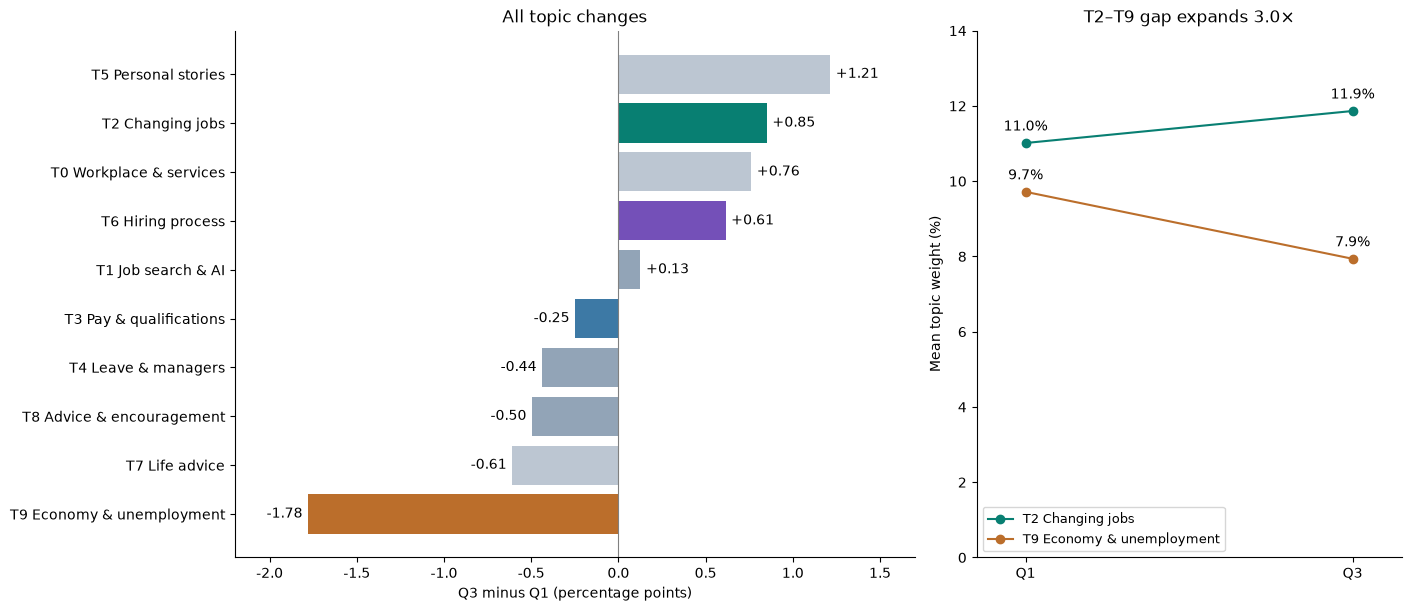

In [ ]:
monthly_weights = analysis_docs.groupby('month')[topic_columns].mean()
monthly_weights.columns = range(10)
exported_monthly = analysis_monthly.pivot(index='month', columns='topic', values='seed_42')
np.testing.assert_allclose(monthly_weights, exported_monthly.loc[monthly_weights.index])
q1_weights = monthly_weights.loc[early_months].mean() * 100
q3_weights = monthly_weights.loc[late_months].mean() * 100
quarterly_topics = pd.DataFrame({
    'name': pd.Series(topic_names), 'q1_share_pct': q1_weights, 'q3_share_pct': q3_weights,
    'change_pp': q3_weights - q1_weights,
    'relative_change_pct': (q3_weights / q1_weights - 1) * 100,
}).rename_axis('topic')
display(quarterly_topics.round(3))
gap_q1 = q1_weights[2] - q1_weights[9]
gap_q3 = q3_weights[2] - q3_weights[9]
topic_gap = pd.Series({'q1_gap_pp': gap_q1, 'q3_gap_pp': gap_q3,
                       'gap_multiple': gap_q3 / gap_q1}, name='value')
display(topic_gap.round(3).to_frame())

change_order = quarterly_topics['change_pp'].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained',
                         gridspec_kw={'width_ratios': [1.6, 1]})
bars = axes[0].barh(range(10), quarterly_topics.loc[change_order, 'change_pp'],
                    color=[topic_colors[t] for t in change_order])
axes[0].bar_label(bars, fmt='%+.2f', padding=4)
axes[0].set_yticks(range(10), [f'T{t} {topic_names[t]}' for t in change_order])
axes[0].invert_yaxis()
axes[0].axvline(0, color='grey', linewidth=0.8)
axes[0].set(xlabel='Q3 minus Q1 (percentage points)', xlim=(-2.2, 1.7), title='All topic changes')
for topic in [2, 9]:
    axes[1].plot([0, 1], [q1_weights[topic], q3_weights[topic]], '-o',
                  color=topic_colors[topic], label=f'T{topic} {topic_names[topic]}')
    for x, value in enumerate([q1_weights[topic], q3_weights[topic]]):
        axes[1].annotate(f'{value:.1f}%', (x, value), xytext=(0, 9),
                          textcoords='offset points', ha='center')
axes[1].set(xticks=[0, 1], xticklabels=['Q1', 'Q3'], ylabel='Mean topic weight (%)',
             ylim=(0, 14), xlim=(-0.15, 1.15), title=f'T2–T9 gap expands {gap_q3 / gap_q1:.1f}×')
axes[1].legend(loc='lower left', fontsize=9)
save_analysis_figure(fig, 'quarterly_topic_changes.png')
quarterly_topics.to_csv(analysis_dir / 'quarterly_topic_changes.csv')
topic_gap.to_csv(analysis_dir / 'quarterly_topic_gap.csv')

### LDA: Sensitivity to popular posts

Check whether the quarterly changes depend heavily on a small number of posts.
For each topic and month, rank posts by the sum of topic weights across their
sampled comments. Remove the top three posts for that topic and recompute the
mean topic weight from the remaining comments. Different topics can therefore
have different TOP3 posts. This ranking measures topic contribution within the
sample rather than Reddit votes or engagement.

As a second check, first average comment weights within each post-month and then
give every post the same weight in that month. This reduces the influence of
posts that contribute many sampled comments. Both checks continue to give each
month equal weight in the quarterly comparison.

Attenuation is calculated as
`100 × (1 − change_without_top3 / original_change)`. It describes how much the
estimated quarterly change shrinks after TOP3 removal; it is not a causal share
attributable to those posts.

,original_pp,without_top3_pp,equal_posts_pp,attenuation_pct
topic,,,,
2,0.851,0.545,1.064,35.990
6,0.614,0.239,-0.270,61.147
9,-1.779,-1.488,-0.806,16.380


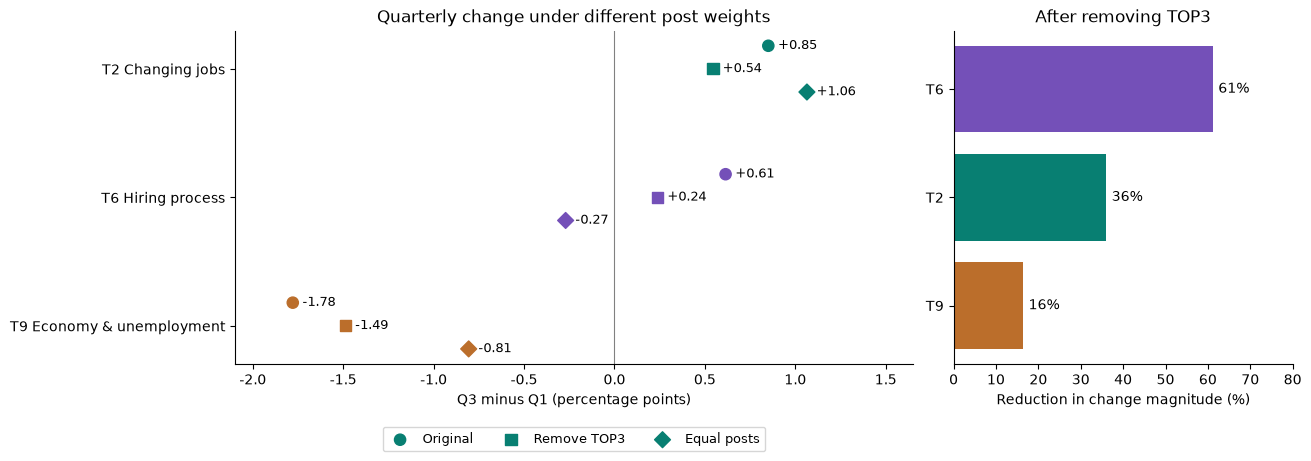

In [ ]:
post_topic_totals = analysis_docs.groupby(['month', 'link_id'])[topic_columns].sum()
post_topic_means = analysis_docs.groupby(['month', 'link_id'])[topic_columns].mean()
equal_post_monthly = post_topic_means.groupby('month').mean()
equal_post_monthly.columns = range(10)
top_post_rows = []
removed_monthly_rows = []
for topic in range(10):
    column = f'topic_{topic}'
    for month, month_docs in analysis_docs.groupby('month'):
        ranked = post_topic_totals.loc[month, column].sort_values(ascending=False, kind='stable')
        assert len(ranked) > 3, f'Too few posts in {month} for TOP3 removal.'
        top_ids = ranked.head(3).index
        remaining = month_docs.loc[~month_docs['link_id'].isin(top_ids)]
        removed_monthly_rows.append({
            'month': month, 'topic': topic,
            'without_top3': remaining[column].mean(),
            'removed_comments': len(month_docs) - len(remaining),
            'remaining_comments': len(remaining),
        })
        for rank, post_id in enumerate(top_ids, start=1):
            top_post_rows.append({'month': month, 'topic': topic, 'rank': rank,
                                  'link_id': post_id, 'summed_topic_weight': ranked[post_id]})
removed_monthly = pd.DataFrame(removed_monthly_rows)
without_top3_monthly = removed_monthly.pivot(index='month', columns='topic', values='without_top3')


def quarter_difference(monthly_table):
    return (monthly_table.loc[late_months].mean() - monthly_table.loc[early_months].mean()) * 100


post_sensitivity = pd.DataFrame({
    'original_pp': quarter_difference(monthly_weights),
    'without_top3_pp': quarter_difference(without_top3_monthly),
    'equal_posts_pp': quarter_difference(equal_post_monthly),
}).rename_axis('topic')
nonzero_change = post_sensitivity['original_pp'].mask(post_sensitivity['original_pp'].abs() < 1e-12)
post_sensitivity['attenuation_pct'] = (1 - post_sensitivity['without_top3_pp'] / nonzero_change) * 100
display(post_sensitivity.loc[[2, 6, 9]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained',
                         gridspec_kw={'width_ratios': [2, 1]})
case_topics = [2, 6, 9]
for column, marker, offset, label in [
    ('original_pp', 'o', -0.18, 'Original'),
    ('without_top3_pp', 's', 0, 'Remove TOP3'),
    ('equal_posts_pp', 'D', 0.18, 'Equal posts'),
]:
    values = post_sensitivity.loc[case_topics, column]
    axes[0].scatter(values, np.arange(3) + offset, marker=marker, s=65,
                     c=[topic_colors[t] for t in case_topics], label=label)
    for y, value in enumerate(values):
        axes[0].annotate(f'{value:+.2f}', (value, y + offset), xytext=(7, 0),
                          textcoords='offset points', va='center', fontsize=9)
axes[0].axvline(0, color='grey', linewidth=0.8)
axes[0].set_yticks(range(3), [f'T{t} {topic_names[t]}' for t in case_topics])
axes[0].invert_yaxis()
axes[0].set(xlim=(-2.1, 1.65), xlabel='Q3 minus Q1 (percentage points)',
             title='Quarterly change under different post weights')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
attenuation_order = [6, 2, 9]
bars = axes[1].barh(range(3), post_sensitivity.loc[attenuation_order, 'attenuation_pct'],
                    color=[topic_colors[t] for t in attenuation_order])
axes[1].bar_label(bars, fmt='%.0f%%', padding=4)
axes[1].set_yticks(range(3), [f'T{t}' for t in attenuation_order])
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 80), xlabel='Reduction in change magnitude (%)', title='After removing TOP3')
save_analysis_figure(fig, 'post_weight_sensitivity.png')
post_sensitivity.to_csv(analysis_dir / 'post_weight_sensitivity.csv')
removed_monthly.to_csv(analysis_dir / 'top3_removed_monthly.csv', index=False)
pd.DataFrame(top_post_rows).to_csv(analysis_dir / 'top3_posts_by_topic_month.csv', index=False)

### LDA: Sensitivity to the random seed

LDA can produce different topic numbers and word distributions under a different
initialisation. Before comparing the two fits, match each seed-7 topic to the
seed-42 topic with the most similar word distribution.

For T2, T6 and T9, compare the Q3-minus-Q1 change from the main fit with the
change from the matched seed-7 fit. Report the cosine similarity used in the
matching alongside each comparison. This checks whether the direction and
magnitude of a trend depend on the random initialisation; the cosine similarity
is a topic-matching measure rather than a significance test.

,seed_42_pp,seed_7_pp,matched_cosine
topic,,,
2,0.851,0.306,0.684
6,0.614,1.231,0.689
9,-1.779,-0.734,0.386


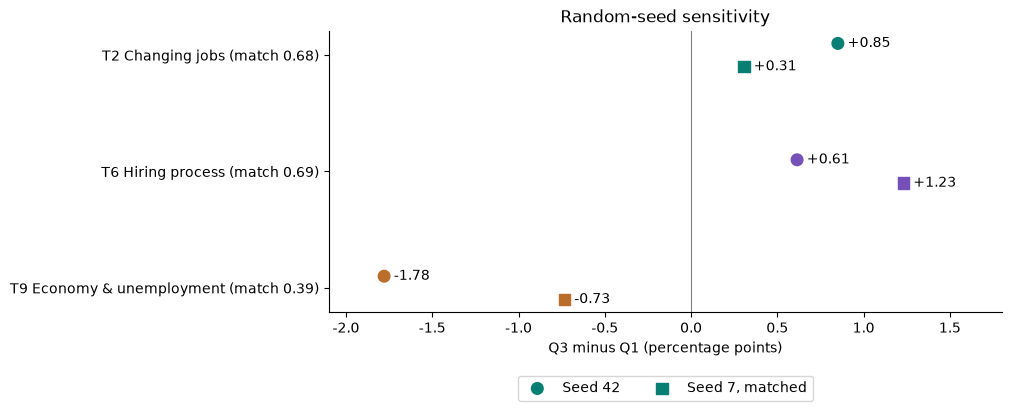

In [ ]:
matched_monthly = analysis_monthly.pivot(index='month', columns='topic', values='seed_7_matched')
seed_sensitivity = pd.DataFrame({
    'seed_42_pp': quarter_difference(monthly_weights),
    'seed_7_pp': quarter_difference(matched_monthly),
    'matched_cosine': analysis_profiles['stability'],
}).rename_axis('topic')
display(seed_sensitivity.loc[case_topics].round(3))
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for column, marker, offset, label in [
    ('seed_42_pp', 'o', -0.10, 'Seed 42'), ('seed_7_pp', 's', 0.10, 'Seed 7, matched'),
]:
    values = seed_sensitivity.loc[case_topics, column]
    ax.scatter(values, np.arange(3) + offset, marker=marker, s=70,
               c=[topic_colors[t] for t in case_topics], label=label)
    for y, value in enumerate(values):
        ax.annotate(f'{value:+.2f}', (value, y + offset), xytext=(7, 0),
                    textcoords='offset points', va='center')
ax.axvline(0, color='grey', linewidth=0.8)
ax.set_yticks(range(3), [f'T{t} {topic_names[t]} (match {seed_sensitivity.loc[t, "matched_cosine"]:.2f})'
                        for t in case_topics])
ax.invert_yaxis()
ax.set(xlim=(-2.1, 1.8), xlabel='Q3 minus Q1 (percentage points)', title='Random-seed sensitivity')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
save_analysis_figure(fig, 'random_seed_sensitivity.png')
seed_sensitivity.to_csv(analysis_dir / 'random_seed_sensitivity.csv')

## A5. Layoffs on r/jobs against layoffs.fyi (slide 23)
How often do r/jobs comments mention layoffs, and does that follow the layoffs.fyi record of announced layoffs? The mention counts come from the full r/jobs archive (not only our sample); the sample is checked against them, and both are compared with the external record from January to September (October is partial). With nine monthly points, correlations are descriptive.

In [ ]:
sys.path.insert(0, str(ROOT))
from functions.layoff_mentions import layoff_terms
from scipy.stats import spearmanr

MENTIONS_DIR = DATA_DIR / 'reddit' / 'layoff_mentions'
LAYOFFS_FILE = DATA_DIR / 'layoffs' / 'layoffs.csv'
FIG_DIR = OUT_DIR / 'layoffs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TERMS = ['laid_off', 'layoff']
COMPLETE = [f'2026-{m:02d}' for m in range(1, 10)]

### Layoffs: Layoff mentions in the full r/jobs archive
For each month: the archive's total r/jobs comments, the comments the archive search returned for each term, and those that pass the exact rule. A comment that uses both terms counts once. Precision (exact / returned) shows how loose the archive search is: "laid off" also returns "laid back" and "laid out". October is cut off on 28 October, so it has no rate.

In [ ]:
run = json.loads((MENTIONS_DIR / 'run.json').read_text(encoding='utf-8'))
counts = pd.read_csv(MENTIONS_DIR / 'monthly_counts.csv').set_index('month')
counts['per_1000'] = counts['any_term_exact'] / counts['archive_comments'] * 1000
counts.loc[counts['partial_month'], 'per_1000'] = np.nan
for term in TERMS:
    counts[f'{term}_precision'] = counts[f'{term}_exact'] / counts[f'{term}_hits']
print('Collection finished', run['finished_utc'], '| archive queries:', run['queries'])
counts[['archive_comments', 'laid_off_exact', 'layoff_exact', 'any_term_exact', 'per_1000',
        'laid_off_precision', 'layoff_precision']].round(3)

Collection finished 2026-10-31T04:37:05+00:00 | archive queries: {'laid_off': '"laid off"', 'layoff': 'layoff'}


,archive_comments,laid_off_exact,layoff_exact,any_term_exact,per_1000,laid_off_precision,layoff_precision
month,,,,,,,
2026-01,82215,828,538,1304,15.861,0.925,1.000
2026-02,76320,746,639,1325,17.361,0.960,1.000
2026-03,87608,904,654,1477,16.859,0.955,1.000
2026-04,87333,675,586,1201,13.752,0.907,1.000
2026-05,70363,678,532,1157,16.443,0.936,0.998
2026-06,61027,515,369,846,13.863,0.941,1.000
2026-07,56820,519,332,814,14.326,0.956,1.000
2026-08,69178,533,321,807,11.666,0.947,1.000
2026-09,64104,436,308,708,11.045,0.934,1.000


### Layoffs: Does Part 2's sample agree with the full archive?
The same rule on the 1,000 sampled comments per month, with a 95% Wilson interval. If the archive rate falls inside most intervals, the sample is a fair picture of the subreddit for this kind of content. The sample excludes deleted, bot and very short comments; the archive totals do not, which pulls the archive rate slightly down.

In [ ]:
corpus = pd.read_csv(TOPICS_DIR / 'comments_clean.csv', dtype={'comment_id': str}, keep_default_na=False)
corpus['mentions'] = corpus['text'].map(lambda text: bool(layoff_terms(text, TERMS)))
sample = corpus.groupby('month')['mentions'].agg(['sum', 'size'])


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


low, high = wilson(sample['sum'], sample['size'])
check = pd.DataFrame({
    'sample_mentions': sample['sum'],
    'sample_per_1000': sample['sum'] / sample['size'] * 1000,
    'sample_low': low * 1000, 'sample_high': high * 1000,
    'archive_per_1000': counts['per_1000'],
})
check['inside_interval'] = check['archive_per_1000'].between(check['sample_low'], check['sample_high'])
print(f"Archive rate inside the sample interval in {check.loc[COMPLETE, 'inside_interval'].sum()} of {len(COMPLETE)} complete months")
check.round(1)

Archive rate inside the sample interval in 7 of 9 complete months


,sample_mentions,sample_per_1000,sample_low,sample_high,archive_per_1000,inside_interval
month,,,,,,
2026-01,20,20.0,13.0,30.7,15.9,True
2026-02,26,26.0,17.8,37.8,17.4,False
2026-03,16,16.0,9.9,25.8,16.9,True
2026-04,21,21.0,13.8,31.9,13.8,False
2026-05,21,21.0,13.8,31.9,16.4,True
2026-06,20,20.0,13.0,30.7,13.9,True
2026-07,18,18.0,11.4,28.3,14.3,True
2026-08,10,10.0,5.4,18.3,11.7,True
2026-09,17,17.0,10.6,27.1,11.0,True


### Layoffs: layoffs.fyi
Reported layoff events, distinct companies and employees laid off per month, overall and for the United States, where most r/jobs users work. Many events have no headcount, and a few very large cuts dominate some months (largest events below), so the number of events is the steadier measure.

In [ ]:
layoffs = pd.read_csv(LAYOFFS_FILE)
layoffs['date'] = pd.to_datetime(layoffs['date'], format='%m/%d/%Y')
layoffs = layoffs[layoffs['date'] >= '2026-01-01'].assign(month=lambda d: d['date'].dt.strftime('%Y-%m'))
us = layoffs['country'] == 'United States'
by_month = layoffs.groupby('month')
fyi = pd.DataFrame({
    'events': by_month.size(),
    'companies': by_month['company'].nunique(),
    'laid_off': by_month['total_laid_off'].sum(),
    'missing_headcount': by_month['total_laid_off'].apply(lambda s: s.isna().mean()),
    'us_events': layoffs[us].groupby('month').size(),
    'us_laid_off': layoffs[us].groupby('month')['total_laid_off'].sum(),
})
print('Latest event in the file:', layoffs['date'].max().date())
display(fyi.round(2))
layoffs.nlargest(5, 'total_laid_off')[['company', 'date', 'total_laid_off', 'country', 'industry']]

Latest event in the file: 2026-10-22


,events,companies,laid_off,missing_headcount,us_events,us_laid_off
month,,,,,,
2026-01,32,32,25183.0,0.25,15,20158.0
2026-02,29,29,11349.0,0.31,17,5952.0
2026-03,35,35,16698.0,0.37,20,13582.0
2026-04,36,36,5085.0,0.39,22,2923.0
2026-05,49,49,24242.0,0.27,28,21799.0
2026-06,50,50,26663.0,0.40,27,24649.0
2026-07,46,43,11000.0,0.39,22,8082.0
2026-08,43,43,3555.0,0.47,27,2453.0
2026-09,33,31,6947.0,0.36,20,5839.0


,company,date,total_laid_off,country,industry
161,Oracle,2026-06-23,21000.0,United States,Other
349,Amazon,2026-01-28,16000.0,United States,Retail
300,Dell,2026-03-16,11000.0,United States,Hardware
209,Meta,2026-05-20,8000.0,United States,Consumer
138,Microsoft,2026-07-06,4800.0,United States,Other


### Layoffs: Comparison
Spearman correlations over the 9 complete months, for the same month and with r/jobs one month later than layoffs.fyi (8 pairs). With so few points, |ρ| has to reach about 0.7 before it is distinguishable from chance, and 18 correlations are computed, so one or two with p < 0.05 are expected by chance alone. Read the table as a description of how the curves move, not as evidence of a relationship. Raw mention counts also follow the overall fall in r/jobs activity, so compare the rate per 1,000 comments rather than counts. In the figure, every curve is standardised (z-score over January–September) so they share one axis.

In [ ]:
lda_shares = pd.read_csv(TOPICS_DIR / 'lda' / 'lda_monthly_shares.csv')
lda_t1 = lda_shares[lda_shares['topic'] == 1].set_index('month')['seed_42'] * 100

series = pd.DataFrame({
    'r/jobs mentions per 1,000 comments': counts['per_1000'],
    'r/jobs mentions': counts['any_term_exact'],
    'LDA T1 share (%)': lda_t1,
    'layoffs.fyi events': fyi['events'],
    'layoffs.fyi employees laid off': fyi['laid_off'],
    'layoffs.fyi US events': fyi['us_events'],
}).loc[COMPLETE]
display(series.round(2))

reddit = ['r/jobs mentions per 1,000 comments', 'r/jobs mentions', 'LDA T1 share (%)']
external = ['layoffs.fyi events', 'layoffs.fyi employees laid off', 'layoffs.fyi US events']
rows = []
for r in reddit:
    for e in external:
        same = spearmanr(series[r], series[e])
        lagged = spearmanr(series[r].iloc[1:].to_numpy(), series[e].iloc[:-1].to_numpy())
        rows.append({'r/jobs': r, 'layoffs.fyi': e,
                     'rho_same_month': same.statistic, 'p_same_month': same.pvalue,
                     'rho_rjobs_1_month_later': lagged.statistic, 'p_1_month_later': lagged.pvalue})
correlations = pd.DataFrame(rows)
correlations.round(3)

,"r/jobs mentions per 1,000 comments",r/jobs mentions,LDA T1 share (%),layoffs.fyi events,layoffs.fyi employees laid off,layoffs.fyi US events
month,,,,,,
2026-01,15.86,1304,9.80,32,25183.0,15
2026-02,17.36,1325,11.79,29,11349.0,17
2026-03,16.86,1477,12.19,35,16698.0,20
2026-04,13.75,1201,12.10,36,5085.0,22
2026-05,16.44,1157,10.58,49,24242.0,28
2026-06,13.86,846,11.46,50,26663.0,27
2026-07,14.33,814,11.45,46,11000.0,22
2026-08,11.67,807,11.19,43,3555.0,27
2026-09,11.04,708,11.52,33,6947.0,20


,r/jobs,layoffs.fyi,rho_same_month,p_same_month,rho_rjobs_1_month_later,p_1_month_later
0,"r/jobs mentions per 1,000 comments",layoffs.fyi events,-0.250,0.516,-0.500,0.207
1,"r/jobs mentions per 1,000 comments",layoffs.fyi employees laid off,0.533,0.139,0.476,0.233
2,"r/jobs mentions per 1,000 comments",layoffs.fyi US events,-0.295,0.440,-0.578,0.133
3,r/jobs mentions,layoffs.fyi events,-0.417,0.265,-0.786,0.021
4,r/jobs mentions,layoffs.fyi employees laid off,0.417,0.265,0.333,0.420
5,r/jobs mentions,layoffs.fyi US events,-0.464,0.208,-0.759,0.029
6,LDA T1 share (%),layoffs.fyi events,-0.250,0.516,-0.667,0.071
7,LDA T1 share (%),layoffs.fyi employees laid off,-0.267,0.488,0.190,0.651
8,LDA T1 share (%),layoffs.fyi US events,-0.228,0.555,-0.518,0.188


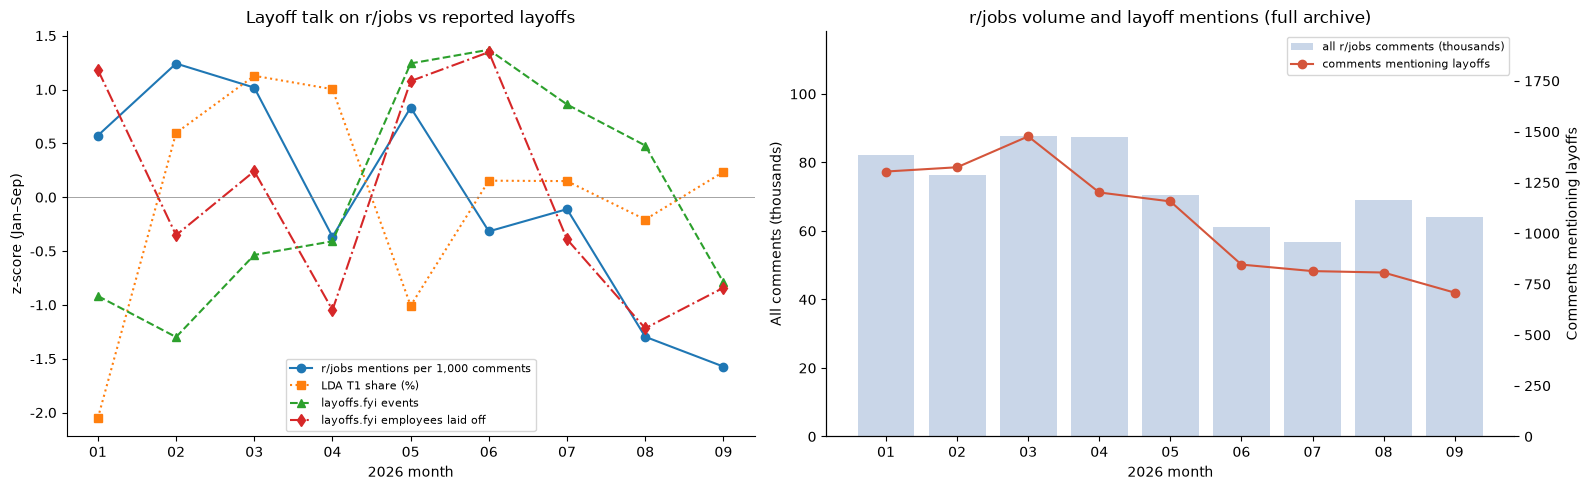

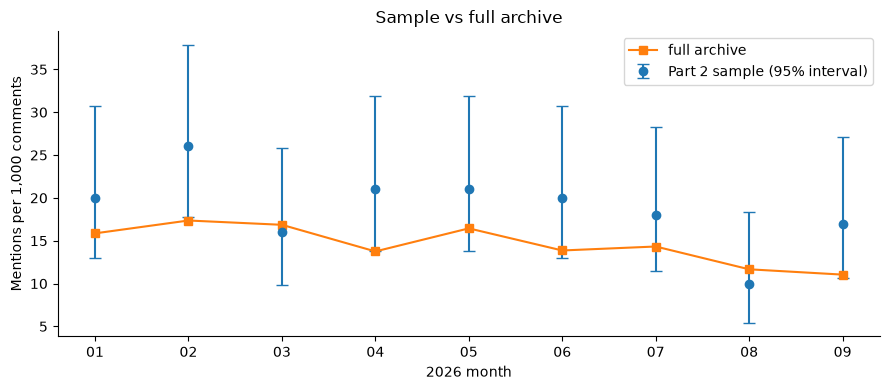

In [ ]:
FIG_DIR.mkdir(parents=True, exist_ok=True)
z = (series - series.mean()) / series.std()
x = range(len(COMPLETE))
ticks = [m[5:] for m in COMPLETE]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for column, style in [('r/jobs mentions per 1,000 comments', '-o'), ('LDA T1 share (%)', ':s'),
                      ('layoffs.fyi events', '--^'), ('layoffs.fyi employees laid off', '-.d')]:
    axes[0].plot(x, z[column], style, label=column)
axes[0].axhline(0, color='grey', linewidth=0.5)
axes[0].set_xticks(list(x), ticks)
axes[0].set(xlabel='2026 month', ylabel='z-score (Jan–Sep)', title='Layoff talk on r/jobs vs reported layoffs')
axes[0].legend(fontsize=8)

# both axes start at 0 so the fall in layoff mentions is not exaggerated
volume = counts.loc[COMPLETE, 'archive_comments'] / 1000
mentions = counts.loc[COMPLETE, 'any_term_exact']
axes[1].bar(x, volume, color='#c9d6e8', label='all r/jobs comments (thousands)')
axes[1].set(xlabel='2026 month', ylabel='All comments (thousands)', ylim=(0, volume.max() * 1.35),
            title='r/jobs volume and layoff mentions (full archive)')
axes[1].set_xticks(list(x), ticks)
twin = axes[1].twinx()
twin.plot(x, mentions, '-o', color='#d4553b', label='comments mentioning layoffs')
twin.set(ylabel='Comments mentioning layoffs', ylim=(0, mentions.max() * 1.35))
bars, bar_labels = axes[1].get_legend_handles_labels()
line, line_labels = twin.get_legend_handles_labels()
axes[1].legend(bars + line, bar_labels + line_labels, loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'layoffs_comparison.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(x, check.loc[COMPLETE, 'sample_per_1000'],
            yerr=[check.loc[COMPLETE, 'sample_per_1000'] - check.loc[COMPLETE, 'sample_low'],
                  check.loc[COMPLETE, 'sample_high'] - check.loc[COMPLETE, 'sample_per_1000']],
            fmt='o', capsize=4, label='Part 2 sample (95% interval)')
ax.plot(x, check.loc[COMPLETE, 'archive_per_1000'], '-s', label='full archive')
ax.set_xticks(list(x), ticks)
ax.set(xlabel='2026 month', ylabel='Mentions per 1,000 comments', title='Sample vs full archive')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'sample_vs_archive.png', dpi=150)
plt.show()

### Layoffs: Quarterly comparison and external context

This section combines three existing outputs: the full-archive keyword counts,
the layoffs.fyi event records and the monthly LDA topic weights. The purpose is
to compare changes in explicit layoff discussion with the external records and
with the broader topic composition identified by LDA.

Use the nine complete months from January to September. Q1 is January–March and
Q3 is July–September; partial October is excluded. Quarterly rates and topic
weights are calculated as the mean of the three monthly values, giving every
month equal weight.

The keyword rate and the LDA weights measure different content and use different
data scopes. The keyword rate counts explicit layoff terms in the full archive,
whereas T9 includes a broader set of economic and unemployment content in the
LDA sample. Their comparison is descriptive and should not be treated as an
independent validation test.

In [ ]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, StrMethodFormatter
from scipy.stats import spearmanr
from IPython.display import display

comparison_root = ROOT
comparison_mentions_dir = comparison_root / 'dataset/reddit/layoff_mentions'
comparison_topics_dir = comparison_root / 'dataset/monthly_Topics'
comparison_output_dir = OUT_DIR / 'layoffs' / 'analysis'
comparison_fig_dir = OUT_DIR / 'layoffs' / 'figures'
comparison_output_dir.mkdir(parents=True, exist_ok=True)
comparison_fig_dir.mkdir(parents=True, exist_ok=True)
complete_months = [f'2026-{month:02d}' for month in range(1, 10)]
q1_months, q3_months = complete_months[:3], complete_months[6:9]

archive_monthly = pd.read_csv(comparison_mentions_dir / 'monthly_counts.csv').set_index('month')
archive_complete = archive_monthly.loc[complete_months].copy()
assert archive_complete['partial_month'].astype(str).str.lower().eq('false').all()
assert (archive_complete['archive_comments'] > 0).all()
assert archive_complete['any_term_exact'].between(0, archive_complete['archive_comments']).all()
archive_complete['mentions_per_1000'] = (
    archive_complete['any_term_exact'] / archive_complete['archive_comments'] * 1000
)

external_records = pd.read_csv(comparison_root / 'dataset/layoffs/layoffs.csv')
external_records['date'] = pd.to_datetime(external_records['date'], format='%m/%d/%Y')
external_records['total_laid_off'] = pd.to_numeric(external_records['total_laid_off'], errors='raise')
assert external_records['total_laid_off'].dropna().ge(0).all()
external_records['month'] = external_records['date'].dt.strftime('%Y-%m')
external_complete = external_records.loc[external_records['month'].isin(complete_months)]
external_grouped = external_complete.groupby('month')['total_laid_off']
external_monthly = pd.DataFrame({
    'events': external_grouped.size(),
    'known_events': external_grouped.count(),
    'disclosed_headcount': external_grouped.sum(min_count=1),
}).reindex(complete_months)
assert external_monthly.notna().all().all(), 'External coverage is incomplete.'
external_monthly['missing_events'] = external_monthly['events'] - external_monthly['known_events']
external_monthly['missing_headcount_pct'] = external_monthly['missing_events'] / external_monthly['events'] * 100
external_monthly['mean_disclosed_size'] = external_monthly['disclosed_headcount'] / external_monthly['known_events']

lda_context_run = json.loads((comparison_topics_dir / 'lda/lda_run.json').read_text(encoding='utf-8'))
assert hashlib.sha256((comparison_topics_dir / 'comments_clean.csv').read_bytes()).hexdigest() == lda_context_run['input_sha256']
assert lda_context_run['k'] == 10 and lda_context_run['seed'] == 42
lda_context = pd.read_csv(comparison_topics_dir / 'lda/lda_monthly_shares.csv')
context_weights = lda_context.pivot(index='month', columns='topic', values='seed_42').loc[complete_months]
assert context_weights.notna().all().all()
comparison_monthly = archive_complete[['archive_comments', 'any_term_exact', 'mentions_per_1000']].join(external_monthly)
comparison_monthly['t2_weight_pct'] = context_weights[2] * 100
comparison_monthly['t9_weight_pct'] = context_weights[9] * 100
display(comparison_monthly.round(3))
archive_total = int(archive_complete['archive_comments'].sum())
sample_total = len(pd.read_csv(comparison_topics_dir / 'lda/lda_comment_topics.csv', usecols=['comment_id']))
print(f'Archive comments, January–September: {archive_total:,}')
print(f'LDA sample, January–October: {sample_total:,}; modelled: {lda_context_run["modelled_comments"]:,}')
comparison_monthly.to_csv(comparison_output_dir / 'monthly_layoff_context.csv')

,archive_comments,any_term_exact,mentions_per_1000,events,known_events,disclosed_headcount,missing_events,missing_headcount_pct,mean_disclosed_size,t2_weight_pct,t9_weight_pct
month,,,,,,,,,,,
2026-01,82215,1304,15.861,32,24,25183.0,8,25.000,1049.292,9.425,10.691
2026-02,76320,1325,17.361,29,20,11349.0,9,31.034,567.450,11.672,9.564
2026-03,87608,1477,16.859,35,22,16698.0,13,37.143,759.000,11.947,8.895
2026-04,87333,1201,13.752,36,22,5085.0,14,38.889,231.136,11.510,8.967
2026-05,70363,1157,16.443,49,36,24242.0,13,26.531,673.389,10.535,9.738
2026-06,61027,846,13.863,50,30,26663.0,20,40.000,888.767,10.161,9.748
2026-07,56820,814,14.326,46,28,11000.0,18,39.130,392.857,11.065,7.629
2026-08,69178,807,11.666,43,23,3555.0,20,46.512,154.565,11.868,7.573
2026-09,64104,708,11.045,33,21,6947.0,12,36.364,330.810,12.663,8.612


Archive comments, January–September: 654,968
LDA sample, January–October: 10,000; modelled: 9,660


### Layoffs: Measuring change from Q1 to Q3

Apply the same quarterly averaging rule to the archive mention rate, recorded
event count, disclosed headcount and selected LDA topic weights. For every
measure, calculate relative change as
`100 × (Q3 monthly mean / Q1 monthly mean − 1)`.

The calculation uses full-precision monthly values and rounds only the displayed
table and chart labels. This keeps the percentage changes consistent across
measures with different units.

,q1_monthly_mean,q3_monthly_mean,relative_change_pct
mentions_per_1000,16.694,12.345,-26.048
disclosed_headcount,17743.333,7167.333,-59.605
events,32.000,40.667,27.083
t2_weight_pct,11.015,11.865,7.723
t9_weight_pct,9.717,7.938,-18.308


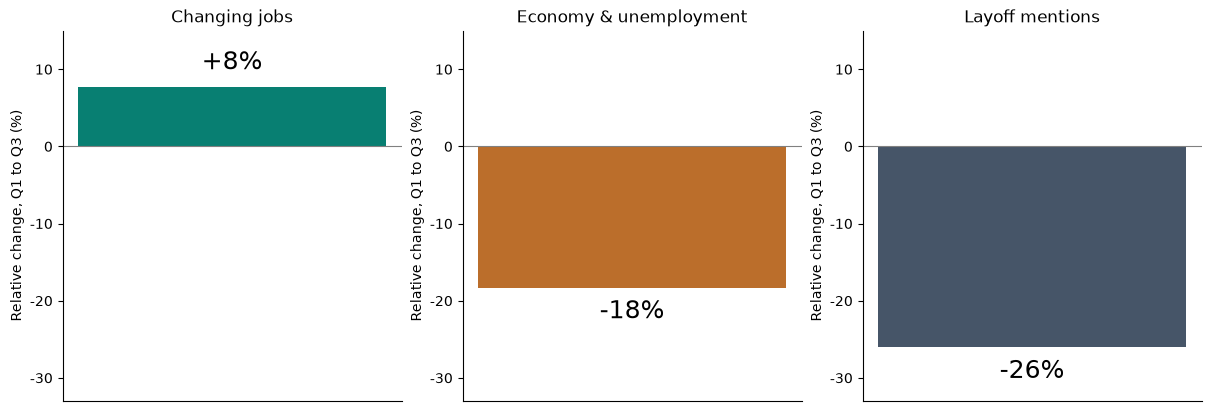

In [ ]:
quarter_metrics = ['mentions_per_1000', 'disclosed_headcount', 'events', 't2_weight_pct', 't9_weight_pct']
quarter_summary = pd.DataFrame({
    'q1_monthly_mean': comparison_monthly.loc[q1_months, quarter_metrics].mean(),
    'q3_monthly_mean': comparison_monthly.loc[q3_months, quarter_metrics].mean(),
})
quarter_summary['relative_change_pct'] = (
    quarter_summary['q3_monthly_mean'] / quarter_summary['q1_monthly_mean'] - 1
) * 100
display(quarter_summary.round(3))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, metric, title in zip(axes,
                            ['t2_weight_pct', 't9_weight_pct', 'mentions_per_1000'],
                            ['Changing jobs', 'Economy & unemployment', 'Layoff mentions']):
    change = quarter_summary.loc[metric, 'relative_change_pct']
    ax.bar([0], [change], color={'t2_weight_pct': '#087F72', 't9_weight_pct': '#BB6E2B'}.get(metric, '#465568'))
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.text(0, change + (1.5 if change >= 0 else -1.5), f'{change:+.0f}%',
            ha='center', va='bottom' if change >= 0 else 'top', fontsize=18)
    ax.set(title=title, xticks=[], ylim=(-33, 15), ylabel='Relative change, Q1 to Q3 (%)')
fig.savefig(comparison_fig_dir / 'discussion_change_summary.png', dpi=160, bbox_inches='tight')
plt.show()
quarter_summary.to_csv(comparison_output_dir / 'quarterly_layoff_context.csv')

### Layoffs: Monthly trajectories and same-month correlations

Plot the monthly layoff-mention rate and disclosed headcount in their original
units. Both y-axes start at zero so that the size of month-to-month changes is not
visually exaggerated. Event count is retained in the comparison table as a
second external measure.

Calculate Spearman correlations between the archive mention rate and each
external measure over the nine complete monthly pairs. Spearman correlation is
used because it compares rank ordering and does not require a linear relationship.
With only nine observations, treat the coefficients and p-values as descriptive;
they do not evaluate forecasting performance or establish a causal relationship.

,n_months,spearman_rho,p_value
external_measure,,,
disclosed_headcount,9,0.5333,0.1392
events,9,-0.2500,0.5165


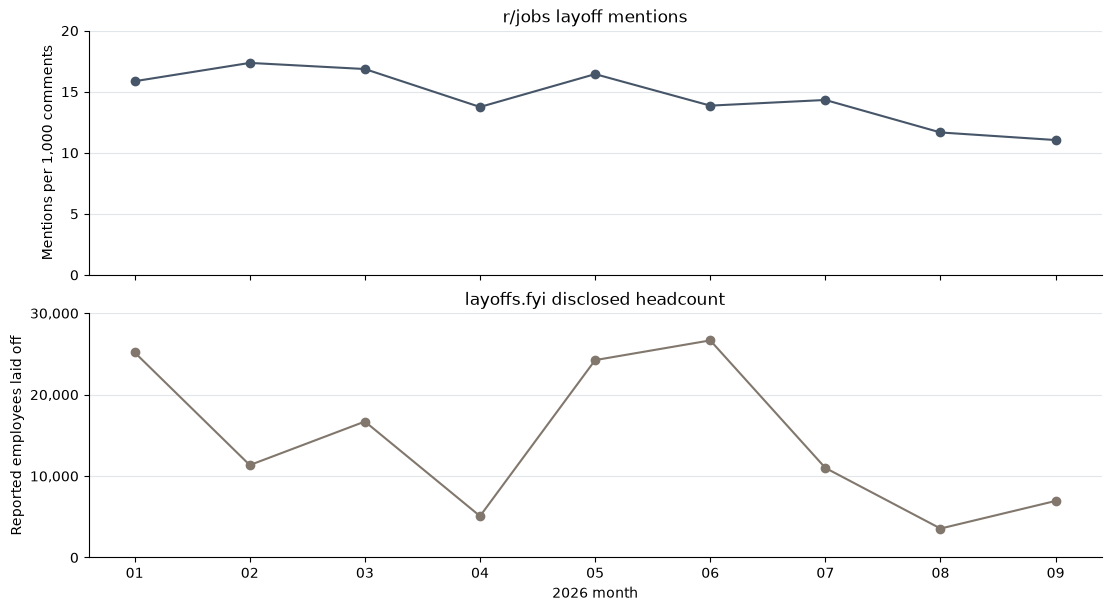

In [ ]:
same_month_rows = []
for metric in ['disclosed_headcount', 'events']:
    result = spearmanr(comparison_monthly['mentions_per_1000'], comparison_monthly[metric])
    same_month_rows.append({'external_measure': metric, 'n_months': len(comparison_monthly),
                            'spearman_rho': result.statistic, 'p_value': result.pvalue})
same_month_results = pd.DataFrame(same_month_rows).set_index('external_measure')
display(same_month_results.round(4))
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
month_positions = np.arange(1, len(complete_months) + 1)
axes[0].plot(month_positions, comparison_monthly['mentions_per_1000'], '-o', color='#465568')
axes[0].set(ylabel='Mentions per 1,000 comments', ylim=(0, 20), title='r/jobs layoff mentions')
axes[0].yaxis.set_major_locator(MultipleLocator(5))
axes[1].plot(month_positions, comparison_monthly['disclosed_headcount'], '-o', color='#81776D')
axes[1].set(ylabel='Reported employees laid off', ylim=(0, 30000),
             xlabel='2026 month', title='layoffs.fyi disclosed headcount')
axes[1].yaxis.set_major_locator(MultipleLocator(10000))
axes[1].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].set_xticks(month_positions, [month[5:] for month in complete_months])
for ax in axes:
    ax.grid(axis='y', color='#E1E6EB')
    ax.set_axisbelow(True)
fig.savefig(comparison_fig_dir / 'monthly_mentions_and_headcount.png', dpi=160, bbox_inches='tight')
plt.show()
same_month_results.to_csv(comparison_output_dir / 'same_month_correlations.csv')

### Layoffs: Recorded event size and missing headcounts

Some layoffs.fyi events do not report the number of employees affected. For each
quarter, sum the disclosed headcount and divide it by the number of events with
known headcount. This gives an event-weighted mean disclosed size rather than an
unweighted average of the three monthly means. Events with missing headcount are
kept missing and are not assigned a value of zero.

Also report the total number of recorded events, the number with known headcount,
the missing-headcount share and the average number of known-headcount events per
month. These diagnostics help assess whether a change in disclosed headcount may
reflect changes in event frequency, recorded event size or data availability.

,recorded_events,known_headcount_events,disclosed_headcount,mean_disclosed_size,missing_headcount_pct,known_events_per_month,all_events_per_month
quarter,,,,,,,
Q1,96.0,66.0,53230.0,806.515,31.250,22.0,32.000
Q3,122.0,72.0,21502.0,298.639,40.984,24.0,40.667


Mean disclosed size change: -62.97%
Rounded people per event: {'Q1': 810, 'Q3': 300}


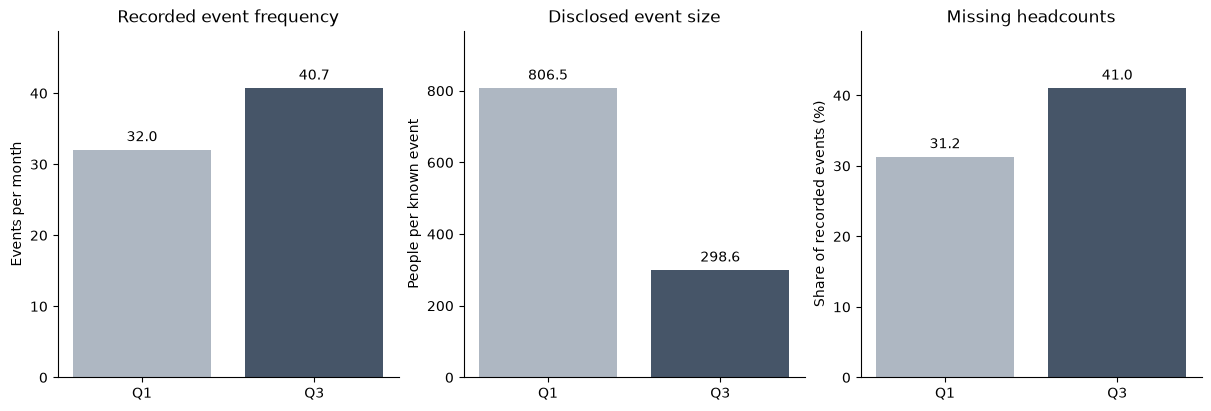

In [ ]:
event_size_rows = []
for quarter, months in [('Q1', q1_months), ('Q3', q3_months)]:
    quarter_external = external_monthly.loc[months]
    totals = quarter_external[['events', 'known_events', 'missing_events', 'disclosed_headcount']].sum()
    event_size_rows.append({
        'quarter': quarter, 'recorded_events': totals['events'],
        'known_headcount_events': totals['known_events'],
        'disclosed_headcount': totals['disclosed_headcount'],
        'mean_disclosed_size': totals['disclosed_headcount'] / totals['known_events'],
        'missing_headcount_pct': totals['missing_events'] / totals['events'] * 100,
        'known_events_per_month': totals['known_events'] / len(months),
        'all_events_per_month': totals['events'] / len(months),
    })
event_size_summary = pd.DataFrame(event_size_rows).set_index('quarter')
size_change_pct = (event_size_summary.loc['Q3', 'mean_disclosed_size'] /
                   event_size_summary.loc['Q1', 'mean_disclosed_size'] - 1) * 100
display(event_size_summary.round(3))
print(f'Mean disclosed size change: {size_change_pct:.2f}%')
print('Rounded people per event:', event_size_summary['mean_disclosed_size'].round(-1).astype(int).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for ax, metric, title, unit in zip(
    axes, ['all_events_per_month', 'mean_disclosed_size', 'missing_headcount_pct'],
    ['Recorded event frequency', 'Disclosed event size', 'Missing headcounts'],
    ['Events per month', 'People per known event', 'Share of recorded events (%)'],
):
    bars = ax.bar(event_size_summary.index, event_size_summary[metric], color=['#AEB7C2', '#465568'])
    ax.bar_label(bars, fmt='%.1f', padding=4)
    ax.set(title=title, ylabel=unit, ylim=(0, event_size_summary[metric].max() * 1.2))
fig.savefig(comparison_fig_dir / 'event_size_and_missingness.png', dpi=160, bbox_inches='tight')
plt.show()
event_size_summary.to_csv(comparison_output_dir / 'quarterly_event_size.csv')

## A6. Do the regenerated tables match the shipped ones?
The LDA and layoff analyses above wrote their tables to `outputs/`. Each is compared here with the table of the same name that ships in `dataset/`, which is the one the slides were made from: same shape and columns, and numbers equal to within 1e-6.

In [ ]:
def same_table(new_path, ref_path):
    new, ref = pd.read_csv(new_path), pd.read_csv(ref_path)
    if new.shape != ref.shape or list(new.columns) != list(ref.columns):
        return False, np.nan
    numeric = [c for c in new.columns if pd.api.types.is_numeric_dtype(new[c]) and pd.api.types.is_numeric_dtype(ref[c])]
    worst = max((np.abs(new[c].astype(float) - ref[c].astype(float)).max() for c in numeric), default=0.0)
    others = [c for c in new.columns if c not in numeric]
    equal = bool(np.isclose(worst, 0, atol=1e-6)) and new[others].astype(str).equals(ref[others].astype(str))
    return equal, worst

pairs = ([(p, TOPICS_DIR / 'lda' / 'analysis' / p.name) for p in sorted((OUT_DIR / 'lda' / 'analysis').glob('*.csv'))]
         + [(p, MENTIONS_DIR / 'analysis' / p.name) for p in sorted((OUT_DIR / 'layoffs' / 'analysis').glob('*.csv'))])
rows = []
for new_path, ref_path in pairs:
    equal, worst = same_table(new_path, ref_path) if ref_path.exists() else (False, np.nan)
    rows.append({'table': f'{new_path.parent.parent.name}/{new_path.name}', 'matches shipped': equal, 'largest difference': worst})
check_table = pd.DataFrame(rows)
display(check_table)
print(f"{int(check_table['matches shipped'].sum())} of {len(check_table)} regenerated tables match the shipped tables.")

,table,matches shipped,largest difference
0,lda/cluster_enrichment.csv,True,0.0
1,lda/cluster_topic_weights_pct.csv,True,0.0
2,lda/example_topic_weights.csv,True,0.0
3,lda/post_weight_sensitivity.csv,True,0.0
4,lda/quarterly_topic_changes.csv,True,0.0
5,lda/quarterly_topic_gap.csv,True,0.0
6,lda/random_seed_sensitivity.csv,True,0.0
7,lda/top3_posts_by_topic_month.csv,True,0.0
8,lda/top3_removed_monthly.csv,True,0.0
9,lda/topic_composition.csv,True,0.0


14 of 14 regenerated tables match the shipped tables.


## A7. Refit the topic models (only with `RETRAIN = True`)
Refits the K-means pipeline (a few minutes) and the LDA models (about three minutes) and saves them to `models_retrained/`; the shipped models are not touched. The refit K-means is compared with the frozen assignments by the adjusted Rand index (1 means the same clusters). LDA topics from a refit are not the slide topics, even with the same seed; the tables above always come from the shipped exports.

In [ ]:
if RETRAIN:
    sys.path.append(str(ROOT / 'scripts'))
    from sklearn.decomposition import LatentDirichletAllocation
    from sklearn.metrics import adjusted_rand_score
    from functions.lda_topics import count_matrix
    from compare_topic_models import DOMAIN_STOP_WORDS, PROTECTED_PHRASES

    # --- K-means: TF-IDF -> PCA -> row L2 -> K-means, with the frozen settings
    features = vectorize_comments(corpus, min_df=3, max_df=0.90, max_features=10000, extra_stop_words=EXTRA_TOPIC_STOP_WORDS,
                                  keep_words=KEEP_TOPIC_WORDS, exclude_moderation=EXCLUDE_MODERATION_NOTICES)
    pca_fit, Z_pca_fit, _, _ = reduce_topics(features['X'], n_components=PCA_COMPONENTS, seed=42, threads=THREADS)
    Z_fit, normalizer_fit = topic_coordinates(Z_pca_fit, PCA_L2_NORMALIZE)
    _, k_models_fit, _ = evaluate_clusters(Z_fit, ks=[SELECTED_K], seed=42, sample_size=SILHOUETTE_SAMPLE, n_init=RETRAIN_SETTINGS['kmeans']['n_init'], threads=THREADS)
    kmeans_fit = k_models_fit[SELECTED_K]
    target = MODEL_DIR / 'topics_kmeans'
    target.mkdir(parents=True, exist_ok=True)
    joblib.dump({'vectorizer': features['vectorizer'], 'pca': pca_fit, 'normalizer': normalizer_fit, 'kmeans': kmeans_fit,
                 'parameters': {'seed': 42, 'selected_k': SELECTED_K, 'pca_components': PCA_COMPONENTS, 'n_init': N_INIT}}, target / 'topic_pipeline.joblib')
    frozen = pd.read_csv(SAVED_MODEL_DIR / 'comment_topics.csv', dtype={'comment_id': str}).set_index('comment_id')
    frozen_labels = pd.to_numeric(frozen.loc[features['model_df']['comment_id'], 'cluster']).to_numpy(int)
    print(f'K-means refit saved to {target.relative_to(ROOT)}; adjusted Rand index against the frozen assignments: '
          f'{adjusted_rand_score(frozen_labels, kmeans_fit.labels_):.3f}')

    # --- LDA: K = 10, raw counts, seeds 42 and 7
    docs = features['model_df']
    counts, counter = count_matrix(features, docs['text_topic'], PROTECTED_PHRASES)
    fits = {}
    for seed in (42, 7):
        fits[seed] = LatentDirichletAllocation(n_components=RETRAIN_SETTINGS['lda']['k'], learning_method='batch', max_iter=RETRAIN_SETTINGS['lda']['max_iter'],
                                               evaluate_every=10, random_state=seed, n_jobs=-1).fit(counts)
    target = MODEL_DIR / 'topics_lda'
    target.mkdir(parents=True, exist_ok=True)
    joblib.dump({'lda_seed42': fits[42], 'lda_seed7': fits[7], 'vocabulary': list(counter.get_feature_names_out())}, target / 'lda_models.joblib')
    print(f'LDA refit saved to {target.relative_to(ROOT)} ({fits[42].n_iter_} and {fits[7].n_iter_} iterations)')
else:
    print('RETRAIN is False: the shipped topic models were used; nothing was refitted.')

RETRAIN is False: the shipped topic models were used; nothing was refitted.


# Part B. Toxicity classification (slides 25-34)

Four models are compared on the same fixed 0.5 decision threshold:

| Model | What it is |
|---|---|
| `LR (standard)` | TF-IDF + logistic regression |
| `LR (balanced)` | the same with balanced class weights |
| `LSTM (standard)` | Bi-LSTM on GloVe embeddings |
| `LSTM (balanced)` | the same with balanced class weights |

They are trained on pooled external datasets (19,187 comments; 15% toxic) and scored on the pooled validation split (4,797 comments) and, without any tuning on it, on 100 hand-labelled r/jobs comments. All four models were tuned the same way: Bayesian search, 30 trials, 5-fold cross-validation inside the training split, and a stability rule that picks, among near-ties, the candidate with the lowest fold-to-fold spread. The validation split is never used for training, tuning or choosing the threshold.

## B0. Libraries and constants

In [ ]:
os_environ_set = os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import hashlib

import joblib
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import to_rgba
from sklearn.metrics import average_precision_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences

from functions.preprocessing import cleanup_text
from functions.cv import kfold_wrapper
from functions.tuning import bayes_search
from functions.lr_tuning import bayes_tune_logistic_regressions
from functions.metrics import paired_bootstrap, toxicity_metrics
from functions.diagnostics import (cutoff_table, flag_breakdown, has_profanity, time_call, token_length_summary,
                                   transfer_summary, triage_table)

THRESHOLD = 0.5                      # fixed decision threshold for every model
VOCAB_SIZE, MAX_LENGTH, EMBED_DIM = 10000, 80, 100
POOLED_DIR = DATA_DIR / 'pooled'
model_colors = {'LR (standard)': '#7f7f7f', 'LR (balanced)': '#8172B3', 'LSTM (standard)': '#55A868', 'LSTM (balanced)': '#4C72B0'}
print('TensorFlow', tf.__version__)

TensorFlow 2.22.0-rc0


## B1. Data
The pooled splits were built from four public sources and are read as shared files. They are checked against `manifest.json`, so the notebook stops if they were edited. The r/jobs sample is loaded in B6.

In [ ]:
def read_pooled(path):
    # orig_id must stay a string and empty strings must not become NaN
    return pd.read_csv(path, dtype={'orig_id': str}, keep_default_na=False)

train_df, val_df = read_pooled(POOLED_DIR / 'pooled_train.csv'), read_pooled(POOLED_DIR / 'pooled_val.csv')
manifest = json.loads((POOLED_DIR / 'manifest.json').read_text(encoding='utf-8'))
for name, frame in [('train', train_df), ('val', val_df)]:
    digest = hashlib.sha256(frame.to_csv(index=False, lineterminator='\n').encode()).hexdigest()
    if digest != manifest['split_sha256'][name]:
        raise ValueError(f'pooled_{name}.csv does not match manifest.json.')
y_train, y_val = train_df['label'].to_numpy(dtype=int), val_df['label'].to_numpy(dtype=int)

composition = pd.concat({
    'train': train_df.groupby('source')['label'].agg(comments='size', toxic='sum'),
    'validation': val_df.groupby('source')['label'].agg(comments='size', toxic='sum'),
}, axis=1)
composition.loc['all sources'] = composition.sum()
composition[('train', 'toxic share')] = composition[('train', 'toxic')] / composition[('train', 'comments')]
composition[('validation', 'toxic share')] = composition[('validation', 'toxic')] / composition[('validation', 'comments')]
display(composition.sort_index(axis=1).round(3))
print(f'Train: {len(train_df):,} comments, toxic share {y_train.mean():.1%} | validation: {len(val_df):,} comments, toxic share {y_val.mean():.1%}')

train                   validation                  
            comments toxic toxic share   comments toxic toxic share
source                                                             
dota            2429  1100       0.453        608   275       0.452
news            7968   640       0.080       1992   160       0.080
wikipedia       7997   813       0.102       1999   203       0.102
youtube          793   366       0.462        198    91       0.460
all sources    19187  2919       0.152       4797   729       0.152

Train: 19,187 comments, toxic share 15.2% | validation: 4,797 comments, toxic share 15.2%


## B2. Text pipeline
Every model sees text that went through the same steps: `cleanup_text` (HTML and URL removal, contractions, punctuation) and lower-casing, which is already applied to the pooled text. The Bi-LSTMs then map words to ids with one tokenizer fitted on the training text only (10,000 words), and pad or cut each comment at the end to 80 tokens; an all-padding comment gets the unknown-word id. The tokenizer is loaded from `models/tokenizer/`; with `RETRAIN = True` it is refitted and saved to `models_retrained/tokenizer/`.

In [ ]:
tokenizer_dir = MODEL_DIR / 'tokenizer'
if RETRAIN:
    tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
    tokenizer.fit_on_texts(train_df['text'])
    tokenizer_dir.mkdir(parents=True, exist_ok=True)
    (tokenizer_dir / 'tokenizer.json').write_text(tokenizer.to_json(), encoding='utf-8')
    (tokenizer_dir / 'settings.json').write_text(json.dumps({
        'vocab_size': VOCAB_SIZE, 'max_length': MAX_LENGTH, 'oov_token': '<OOV>', 'padding': 'post', 'truncating': 'post',
        'train_split_sha256': manifest['split_sha256']['train']}, indent=2), encoding='utf-8')
    print(f'Fitted a new tokenizer and saved it to {tokenizer_dir.relative_to(ROOT)}')
else:
    tokenizer = tokenizer_from_json((tokenizer_dir / 'tokenizer.json').read_text(encoding='utf-8'))
    settings = json.loads((tokenizer_dir / 'settings.json').read_text(encoding='utf-8'))
    if settings['train_split_sha256'] != manifest['split_sha256']['train']:
        raise ValueError('The saved tokenizer was fitted on a different training split.')
    if (settings['vocab_size'], settings['max_length']) != (VOCAB_SIZE, MAX_LENGTH):
        raise ValueError('The saved tokenizer settings differ from VOCAB_SIZE and MAX_LENGTH.')
    print('Loaded the saved tokenizer')

def encode(texts):
    # tokenize, pad or cut at the end, and give an all-padding row the unknown-word id
    X = pad_sequences(tokenizer.texts_to_sequences(list(texts)), maxlen=MAX_LENGTH, padding='post', truncating='post')
    X[(X == 0).all(axis=1), 0] = tokenizer.word_index[tokenizer.oov_token]
    return X

train_n_tokens = np.array([len(s) for s in tokenizer.texts_to_sequences(train_df['text'].tolist())])
print(f'Training comments cut at {MAX_LENGTH} tokens: {(train_n_tokens > MAX_LENGTH).mean():.1%}')

Loaded the saved tokenizer
Training comments cut at 80 tokens: 19.6%


## B3. Logistic regression
Two TF-IDF + logistic regression pipelines, one without and one with balanced class weights. Each was tuned by a Bayesian search over the regularisation strength `C` (0.01 to 100, log scale), the n-gram range (1,1) or (1,2) and the minimum document frequency (1 to 5): 30 trials scored by 5-fold cross-validation on the training split, with the TF-IDF vocabulary refitted inside every fold. Among trials within one fold-standard-deviation of the best mean PR-AUC, the one with the lowest spread is selected, the same rule as for the Bi-LSTM. With `RETRAIN = True` the search is run again and the models are saved to `models_retrained/baselines/`.

In [ ]:
baseline_dir = MODEL_DIR / 'baselines'
if RETRAIN:
    tuned = bayes_tune_logistic_regressions(train_df['text'], train_df['label'], n_splits=5, random_state=SEED, n_jobs=1,
                                            **RETRAIN_SETTINGS['lr_search'])
    baseline_dir.mkdir(parents=True, exist_ok=True)
    for name, model in tuned['models'].items():
        joblib.dump(model, baseline_dir / f'{name}.joblib')
    tuned['cv_results'].to_csv(baseline_dir / 'lr_tuning_cv.csv', index=False)
    (baseline_dir / 'baselines_manifest.json').write_text(json.dumps({
        'train_split_sha256': manifest['split_sha256']['train'], 'val_split_sha256': manifest['split_sha256']['val'],
        'random_state': SEED, 'threshold': THRESHOLD, 'config': tuned['config']}, indent=2), encoding='utf-8')
    print(f'Saved the tuned logistic regressions to {baseline_dir.relative_to(ROOT)}')

baselines_manifest = json.loads((baseline_dir / 'baselines_manifest.json').read_text(encoding='utf-8'))
if baselines_manifest['train_split_sha256'] != manifest['split_sha256']['train']:
    raise ValueError('The saved logistic regressions were fitted on a different training split.')
if baselines_manifest['config'].get('search') != 'bayes':
    raise ValueError('The saved logistic regressions are not the Bayesian-tuned models.')
logreg = {
    'LR (standard)': joblib.load(baseline_dir / 'tfidf_logreg.joblib'),
    'LR (balanced)': joblib.load(baseline_dir / 'tfidf_logreg_balanced.joblib'),
}
selected = pd.DataFrame(baselines_manifest['config']['selected_params']).T
selected.index = ['LR (standard)', 'LR (balanced)']
selected.columns = ['C', 'n-gram range', 'min_df']
selected['TF-IDF vocabulary'] = [len(logreg[n].named_steps['tfidfvectorizer'].vocabulary_) for n in selected.index]
display(selected)
cv_file = baseline_dir / 'lr_tuning_cv.csv'
if cv_file.exists():
    cv = pd.read_csv(cv_file)
    print('Selected trial of each search (mean and standard deviation of PR-AUC over the 5 training folds):')
    display(cv[cv['selected']][['model', 'trial', 'C', 'ngram_range', 'min_df', 'mean_cv_pr_auc', 'std_cv_pr_auc']].round(4).reset_index(drop=True))

,C,n-gram range,min_df,TF-IDF vocabulary
LR (standard),15.352247,"[1, 2]",2,50000
LR (balanced),18.286039,"[1, 1]",1,43937


Selected trial of each search (mean and standard deviation of PR-AUC over the 5 training folds):


,model,trial,C,ngram_range,min_df,mean_cv_pr_auc,std_cv_pr_auc
0,tfidf_logreg,1,15.3522,"(1, 2)",2,0.7874,0.0209
1,tfidf_logreg_balanced,16,18.2860,"(1, 1)",1,0.8048,0.0215


## B4. Bi-LSTM
An embedding layer initialised with GloVe 6B (100 dimensions, fine-tuned or frozen), a bidirectional LSTM and a sigmoid output. The search covers the embedding mode, LSTM units (8 to 128), dropout (0 to 0.5) and learning rate (3e-4 to 1e-2): 30 Bayesian trials, each scored by 5-fold cross-validation on the training split, then the same stability rule as for the logistic regressions. The saved result of each search holds its best model and every trial. With `RETRAIN = True` the searches are run again (GloVe is downloaded if `glove/` is empty) and saved to `models_retrained/`.

In [ ]:
LSTM_RUNS = {
    'LSTM (standard)': {'class_weight': None, 'folder': 'bayes_search_pooled_unweighted'},
    'LSTM (balanced)': {'class_weight': 'balanced', 'folder': 'bayes_search_pooled_balanced'},
}
if RETRAIN:
    from skopt.space import Categorical, Integer, Real
    from tensorflow.keras.layers import Bidirectional, Dense, Embedding, LSTM
    from tensorflow.keras.models import Sequential
    from functions.embeddings import build_embedding_matrix, download_glove, glove_filename

    glove_path = ROOT / 'glove' / glove_filename(EMBED_DIM)
    if not glove_path.exists():
        download_glove(EMBED_DIM, str(ROOT / 'glove'))
    embedding_matrix, glove_coverage = build_embedding_matrix(str(glove_path), tokenizer.word_index, VOCAB_SIZE)
    print(f'Embedding matrix {embedding_matrix.shape}, {glove_coverage:.1%} of the vocabulary found in GloVe')

    def build_model(trainable, lstm_units, dropout, lr):
        m = Sequential([
            Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, embeddings_initializer=tf.keras.initializers.Constant(embedding_matrix),
                      trainable=trainable, mask_zero=True),
            Bidirectional(LSTM(lstm_units, dropout=dropout)),
            Dense(1, activation='sigmoid'),
        ])
        m.compile(loss='binary_crossentropy', optimizer=tf.keras.optimizers.Adam(lr),
                  metrics=['accuracy', tf.keras.metrics.F1Score(name='f1_score', threshold=THRESHOLD), tf.keras.metrics.AUC(curve='PR', name='pr_auc')])
        return m

    search_space = {'trainable': Categorical([True, False]), 'lstm_units': Integer(8, 128, prior='log-uniform'),
                    'dropout': Real(0.0, 0.5), 'lr': Real(3e-4, 1e-2, prior='log-uniform')}
    X_train, X_val = encode(train_df['text']), encode(val_df['text'])
    for name, run in LSTM_RUNS.items():
        search = bayes_search(build_model, search_space, X_train, y_train, X_val, y_val, **RETRAIN_SETTINGS['lstm_search'],
                              kfold_kwargs={**RETRAIN_SETTINGS['lstm_cv'], 'class_weight': run['class_weight']})
        search.fit()
        search.save(str(MODEL_DIR / run['folder']))
        print(f'Saved {name} to {(MODEL_DIR / run["folder"]).relative_to(ROOT)}')

C:\Users\cy071\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\saving\saving_lib.py:841: UserWarning: Skipping variable loading for optimizer 'adam', because it has 20 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


,trials,selected trial,trainable GloVe,LSTM units,dropout,learning rate,CV PR-AUC mean,CV PR-AUC std
LSTM (standard),30,21,True,11,0.5,0.00126,0.820131,0.019008
LSTM (balanced),30,17,True,110,0.5,0.00184,0.818062,0.01914


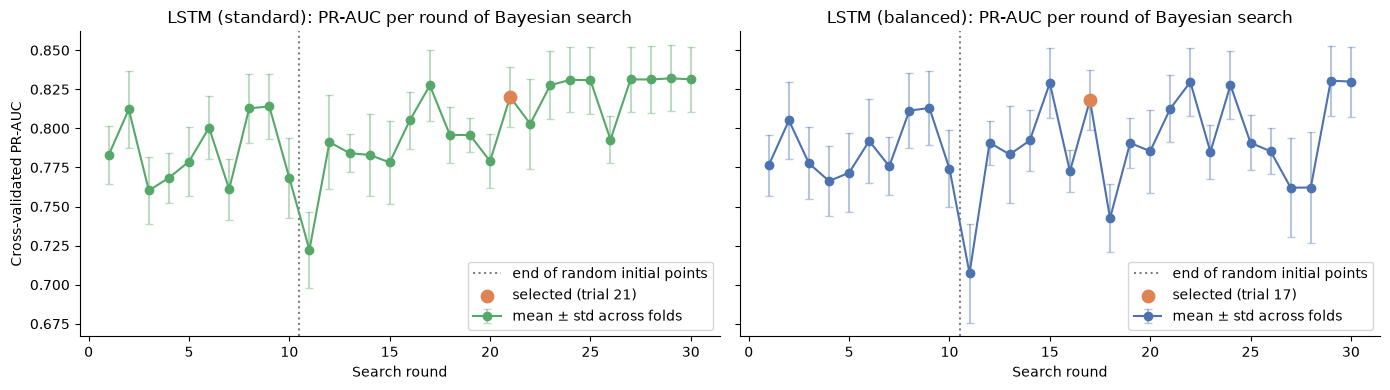

In [ ]:
lstm_search, lstm = {}, {}
for name, run in LSTM_RUNS.items():
    directory = MODEL_DIR / run['folder']
    search = bayes_search.load(str(directory))
    best = search.best_kfold
    trained_with = getattr(best, 'class_weight', None)  # results saved before the option existed had no class weights
    if trained_with != run['class_weight']:
        raise ValueError(f'{name}: the saved model was trained with class_weight={trained_with!r}, expected {run["class_weight"]!r}.')
    best.threshold, best.tuned_threshold, best.tuned_validation_metrics = THRESHOLD, None, None  # one fixed threshold for every model
    lstm_search[name], lstm[name] = search, best

summary = pd.DataFrame({
    name: {'trials': len(s.results), 'selected trial': s.best_trial, 'trainable GloVe': s.best_params['trainable'],
           'LSTM units': s.best_params['lstm_units'], 'dropout': round(s.best_params['dropout'], 3), 'learning rate': round(s.best_params['lr'], 5),
           'CV PR-AUC mean': s.results.loc[s.best_trial, 'avg_val_pr_auc'], 'CV PR-AUC std': s.results.loc[s.best_trial, 'std_val_pr_auc']}
    for name, s in lstm_search.items()}).T
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (name, s) in zip(axes, lstm_search.items()):
    mean, std = s.results['avg_val_pr_auc'], s.results['std_val_pr_auc']
    ax.errorbar(s.results.index, mean, yerr=std, fmt='o-', color=model_colors[name], ecolor=to_rgba(model_colors[name], 0.4), capsize=3,
                label='mean ± std across folds')
    ax.axvline(s.n_initial_points + 0.5, color='grey', linestyle=':', label='end of random initial points')
    ax.scatter([s.best_trial], [mean[s.best_trial]], color='#DD8452', zorder=3, s=80, label=f'selected (trial {s.best_trial})')
    ax.set(xlabel='Search round', title=f'{name}: PR-AUC per round of Bayesian search')
    ax.legend()
axes[0].set_ylabel('Cross-validated PR-AUC')
plt.tight_layout(); plt.show()

### One prediction function for all four models
`predict_proba(name, texts)` returns the probability of toxic for cleaned comments. The logistic regressions take the text directly; the Bi-LSTMs take it through `encode`.

In [ ]:
model_names = list(logreg) + list(lstm)

def predict_proba(name, texts):
    texts = list(texts)
    if name in logreg:
        return logreg[name].predict_proba(texts)[:, 1]
    return lstm[name].final_model.predict(encode(texts), verbose=0).ravel()

print('Models loaded:', ', '.join(model_names))

Models loaded: LR (standard), LR (balanced), LSTM (standard), LSTM (balanced)


## B5. Validation performance (slides 27-28)
Scores the pooled validation split with all four models. The validation comments come from the same sources as the training data, so these numbers are in-domain and optimistic about r/jobs. Recall and the false positive rate (FPR) are each computed within one class and do not depend on the share of toxic comments; precision, macro F1 and PR-AUC do. With about 730 toxic comments, differences of a point or two are within noise.

In [ ]:
def evaluate(y, proba, threshold=THRESHOLD):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    m = toxicity_metrics(y, proba, threshold)
    return {'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'precision': m['precision'], 'recall (TPR)': m['recall'],
            'FPR': fp / (fp + tn), 'macro_f1': m['macro_f1'], 'pr_auc': m['pr_auc'], 'roc_auc': m['roc_auc']}

def results_table(y, probas):
    return pd.DataFrame({name: evaluate(y, p) for name, p in probas.items()}).T.infer_objects()

def plot_confusion_matrices(y, probas, suptitle):
    fig, axes = plt.subplots(2, 2, figsize=(9, 8))
    for ax, (name, p) in zip(axes.ravel(), probas.items()):
        ConfusionMatrixDisplay.from_predictions(y, (p >= THRESHOLD).astype(int), labels=[0, 1], display_labels=['Non-toxic', 'Toxic'],
                                                cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(name)
    fig.suptitle(suptitle); fig.tight_layout(); plt.show()

def plot_pr_curves(y, probas, title):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for name, p in probas.items():
        precision, recall, _ = precision_recall_curve(y, p)
        ax.step(recall, precision, where='post', color=model_colors[name], linewidth=2,
                label=f'{name} (PR-AUC = {average_precision_score(y, p):.3f})')
        pred = (p >= THRESHOLD).astype(int)
        ax.scatter([((pred == 1) & (y == 1)).sum() / (y == 1).sum()], [((pred == 1) & (y == 1)).sum() / max((pred == 1).sum(), 1)],
                   color=model_colors[name], edgecolors='black', zorder=3, s=70)
    ax.axhline(y.mean(), color='grey', linestyle='--', label=f'Chance (PR-AUC = {y.mean():.3f})')
    ax.set(xlabel='Recall', ylabel='Precision', title=title, xlim=(0, 1.02), ylim=(0, 1.05))
    ax.legend(loc='lower left', fontsize=8)
    plt.tight_layout(); plt.show()

Validation split: 4,797 comments, toxic share 15.2%, threshold 0.5


,TP,FP,FN,TN,precision,recall (TPR),FPR,macro_f1,pr_auc,roc_auc
LR (standard),408.0,53.0,321.0,4015.0,0.885,0.560,0.013,0.821,0.781,0.911
LR (balanced),517.0,172.0,212.0,3896.0,0.750,0.709,0.042,0.841,0.806,0.922
LSTM (standard),473.0,85.0,256.0,3983.0,0.848,0.649,0.021,0.847,0.819,0.928
LSTM (balanced),556.0,287.0,173.0,3781.0,0.660,0.763,0.071,0.825,0.810,0.924


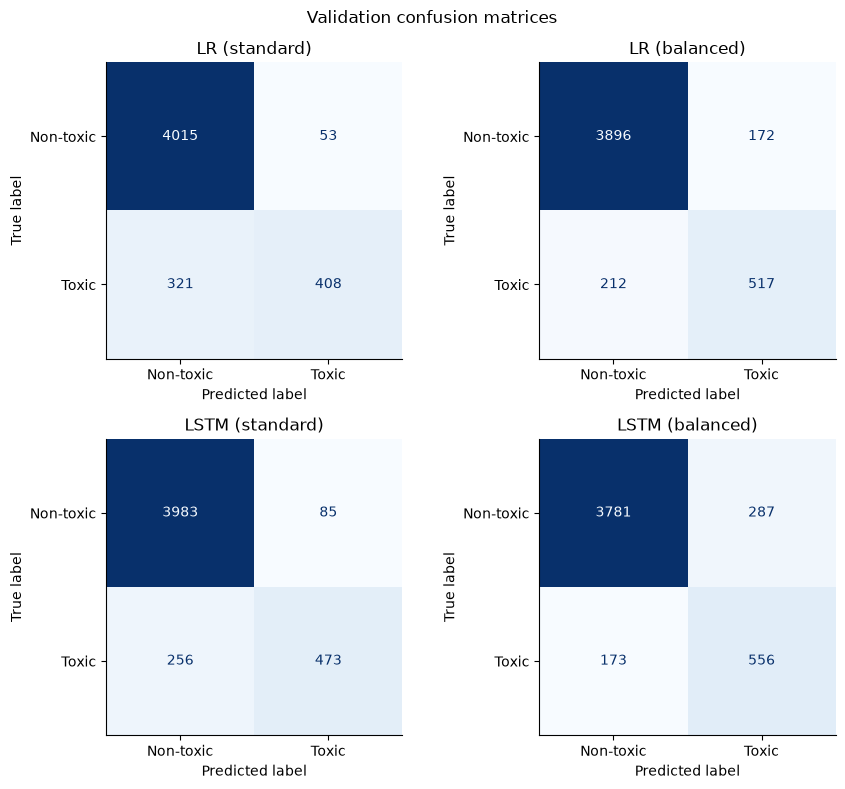

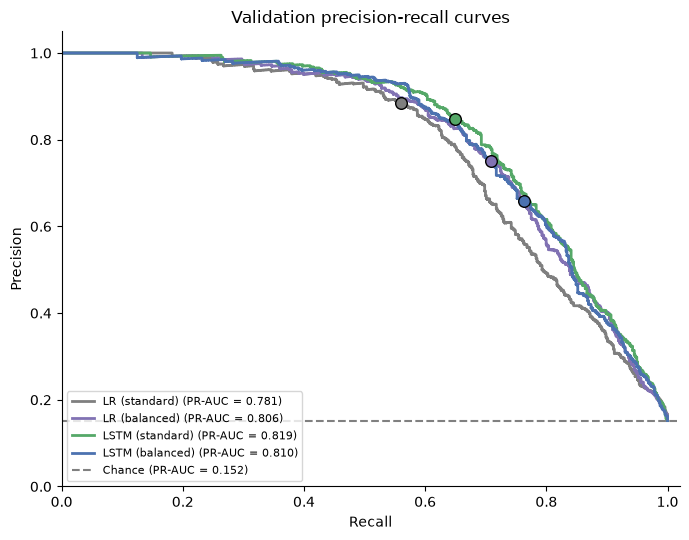

In [ ]:
val_proba = {name: predict_proba(name, val_df['text']) for name in model_names}
val_results = results_table(y_val, val_proba)
print(f'Validation split: {len(y_val):,} comments, toxic share {y_val.mean():.1%}, threshold {THRESHOLD:g}')
display(val_results.round(3))
plot_confusion_matrices(y_val, val_proba, 'Validation confusion matrices')
plot_pr_curves(y_val, val_proba, 'Validation precision-recall curves')

### Higher cut-offs on the validation split
Raising the cut-off trades recall for precision. The table gives precision, recall and the share of all comments flagged for each model.

In [ ]:
val_cutoffs = cutoff_table(y_val, val_proba)
display(val_cutoffs.pivot(index='cutoff', columns='model', values='precision').round(3).rename_axis(columns='precision'))
display(val_cutoffs.pivot(index='cutoff', columns='model', values='recall').round(3).rename_axis(columns='recall'))

precision,LR (balanced),LR (standard),LSTM (balanced),LSTM (standard)
cutoff,,,,
0.50,0.750,0.885,0.660,0.848
0.70,0.844,0.930,0.754,0.910
0.80,0.888,0.941,0.798,0.934
0.90,0.929,0.960,0.849,0.955
0.95,0.950,0.970,0.901,0.975
0.98,0.954,0.989,0.942,0.993
0.99,0.970,0.993,0.954,1.000


recall,LR (balanced),LR (standard),LSTM (balanced),LSTM (standard)
cutoff,,,,
0.50,0.709,0.560,0.763,0.649
0.70,0.632,0.490,0.704,0.594
0.80,0.586,0.439,0.671,0.543
0.90,0.523,0.366,0.631,0.466
0.95,0.465,0.313,0.576,0.374
0.98,0.396,0.246,0.514,0.206
0.99,0.354,0.198,0.455,0.063


## B6. Zero-shot test on r/jobs (slide 28)
The four models are applied as saved, at the fixed 0.5 threshold, to a shared sample of 100 r/jobs comments: **50 non-toxic (`0`) and 50 toxic (`1`) hand labels**. These are toxicity labels, not sentiment. A team member labelled the comments by hand, so the scores measure **agreement with one annotator's labels**. None of the models was trained, tuned or thresholded on this sample.

The sample is balanced and keyword-enriched, with some comments from the same threads, so its precision, macro F1 and PR-AUC do not estimate live r/jobs performance or toxicity prevalence. Recall and FPR do not depend on the toxic share, so they are the measures to compare with the validation split, but each rests on only 50 comments and differences of a few points are within noise. The loader stops on missing labels, duplicates, a wrong class balance or a missing human annotator.

In [ ]:
reddit_path = DATA_DIR / 'reddit' / 'test_100_labeled.csv'
reddit_df = pd.read_csv(reddit_path, dtype=str, keep_default_na=False)
reddit_required = {'comment_id', 'text', 'subreddit', 'is_toxic', 'permalink', 'annotation_status', 'annotator'}
if not reddit_required.issubset(reddit_df.columns):
    raise ValueError(f'Missing Reddit columns: {sorted(reddit_required - set(reddit_df.columns))}')
if len(reddit_df) != 100 or reddit_df['is_toxic'].value_counts().to_dict() != {'0': 50, '1': 50}:
    raise ValueError('Expected exactly 100 labelled comments: 50 non-toxic (0), 50 toxic (1).')
if (reddit_df['comment_id'].str.strip().eq('').any() or reddit_df['comment_id'].duplicated().any()
        or reddit_df['text'].str.strip().eq('').any()):
    raise ValueError('Reddit IDs must be nonempty and unique; comment text must be nonempty.')
reddit_text_keys = reddit_df['text'].str.normalize('NFKC').str.casefold().str.split().str.join(' ')
if reddit_text_keys.duplicated().any() or reddit_text_keys.isin(['[deleted]', '[removed]']).any():
    raise ValueError('Duplicate or deleted/removed Reddit comments cannot be evaluated.')
if not reddit_df['subreddit'].eq('jobs').all():
    raise ValueError('This evaluation expects r/jobs comments only.')
if not reddit_df['annotation_status'].eq('hand_labelled').all():
    raise ValueError('Every test comment must have a completed hand label (hand_labelled).')
reddit_annotators = reddit_df['annotator'].str.strip()
if reddit_annotators.eq('').any() or reddit_annotators.str.casefold().str.startswith('ai').any():
    raise ValueError('Every test comment needs a human annotator recorded in the annotator column.')
reddit_label_source = 'hand labels'
print(f'Loaded {len(reddit_df)} r/jobs comments from {reddit_path.relative_to(ROOT)} | reference: {reddit_label_source}')
display(reddit_df.groupby('is_toxic').size().rename(index={'0': 'Non-toxic', '1': 'Toxic'}).to_frame('count'))

Loaded 100 r/jobs comments from dataset\reddit\test_100_labeled.csv | reference: hand labels


,count
is_toxic,
Non-toxic,50
Toxic,50


### Apply the training pipeline and score the sample
Lowercase, then `cleanup_text`, gives the cleaned text every model expects. The truncation count shows how many comments exceed the Bi-LSTMs' input length of 80 tokens (the logistic regressions see the whole comment).

Comments longer than 80 tokens (cut for the Bi-LSTMs): 42/100
Reddit sample: 100 comments, toxic share 50%, threshold 0.5 | reference: hand labels


,TP,FP,FN,TN,precision,recall (TPR),FPR,macro_f1,pr_auc,roc_auc
LR (standard),24.0,5.0,26.0,45.0,0.828,0.48,0.10,0.676,0.799,0.822
LR (balanced),36.0,11.0,14.0,39.0,0.766,0.72,0.22,0.750,0.801,0.831
LSTM (standard),30.0,11.0,20.0,39.0,0.732,0.60,0.22,0.687,0.785,0.767
LSTM (balanced),34.0,12.0,16.0,38.0,0.739,0.68,0.24,0.720,0.763,0.744


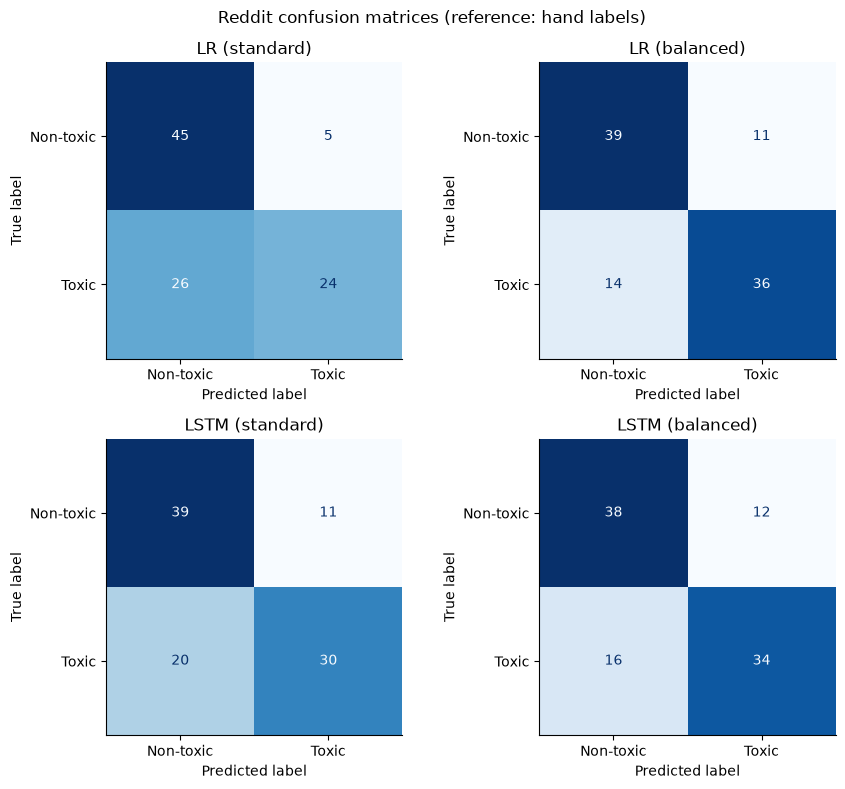

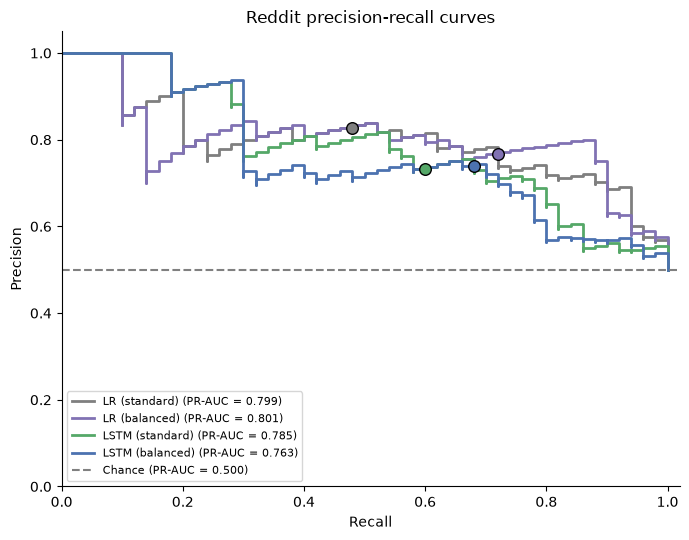

In [ ]:
reddit_cleaned = [cleanup_text(text.lower()) for text in reddit_df['text']]
y_reddit = reddit_df['is_toxic'].astype(int).to_numpy()
reddit_n_tokens = np.array([len(s) for s in tokenizer.texts_to_sequences(reddit_cleaned)])
reddit_proba = {}
for name in model_names:
    proba = np.asarray(predict_proba(name, reddit_cleaned), dtype=float)
    if proba.shape != y_reddit.shape or not np.isfinite(proba).all() or ((proba < 0) | (proba > 1)).any():
        raise ValueError(f'{name} must return one finite toxicity probability in [0, 1] per comment.')
    reddit_proba[name] = proba
print(f'Comments longer than {MAX_LENGTH} tokens (cut for the Bi-LSTMs): {(reddit_n_tokens > MAX_LENGTH).sum()}/{len(reddit_df)}')

reddit_results = results_table(y_reddit, reddit_proba)
print(f'Reddit sample: {len(y_reddit)} comments, toxic share {y_reddit.mean():.0%}, threshold {THRESHOLD:g} | reference: {reddit_label_source}')
display(reddit_results.round(3))
plot_confusion_matrices(y_reddit, reddit_proba, f'Reddit confusion matrices (reference: {reddit_label_source})')
plot_pr_curves(y_reddit, reddit_proba, 'Reddit precision-recall curves')

### Validation against r/jobs
Recall and FPR of each model side by side for the two datasets. A model that transfers well keeps both close to its validation values. The change column is r/jobs minus validation.

In [ ]:
shift = pd.concat({
    'validation': val_results[['recall (TPR)', 'FPR']],
    'r/jobs sample': reddit_results[['recall (TPR)', 'FPR']],
    'change': reddit_results[['recall (TPR)', 'FPR']] - val_results[['recall (TPR)', 'FPR']],
}, axis=1)
display(shift.astype(float).round(3))

validation        r/jobs sample             change       
                recall (TPR)    FPR  recall (TPR)   FPR recall (TPR)    FPR
LR (standard)          0.560  0.013          0.48  0.10       -0.080  0.087
LR (balanced)          0.709  0.042          0.72  0.22        0.011  0.178
LSTM (standard)        0.649  0.021          0.60  0.22       -0.049  0.199
LSTM (balanced)        0.763  0.071          0.68  0.24       -0.083  0.169

## B7. Are the gaps larger than chance? (slides 28 and 33)
A paired bootstrap shows how much a gap between two models could move. Each round draws the comments again with replacement, the same comments for both models, recomputes the metrics and takes the difference, model a minus model b. After 1,000 rounds the middle 95% of the differences is the interval below. If it includes zero, this sample cannot tell the two models apart on that metric. The comparisons are the two Bi-LSTMs against the balanced logistic regression, the model we would deploy. The intervals assume independent comments, which is not quite true for r/jobs; nothing here is used to choose a model or a threshold. The seed is fixed, so the numbers repeat exactly. Differences are in percentage points.

In [ ]:
BOOTSTRAP = {'n_boot': 1000, 'seed': 0}  # number of resamples and the random seed
comparisons = [('LSTM (standard)', 'LR (balanced)'), ('LSTM (balanced)', 'LR (balanced)')]
bootstrap = {}
for dataset, y, probas in [('validation', y_val, val_proba), ('r/jobs sample', y_reddit, reddit_proba)]:
    for a, b in comparisons:
        bootstrap[(dataset, f'{a} minus {b}')] = paired_bootstrap(y, probas[a], probas[b], threshold=THRESHOLD, **BOOTSTRAP)
bootstrap = pd.concat(bootstrap, names=['dataset', 'comparison'])
bootstrap_points = (bootstrap[['difference', 'ci_low', 'ci_high']] * 100).round(1).rename(columns={
    'difference': 'observed difference on the full set',
    'ci_low': 'bootstrap 2.5th percentile (95% interval lower bound)',
    'ci_high': 'bootstrap 97.5th percentile (95% interval upper bound)'})
bootstrap_points['includes zero'] = (bootstrap['ci_low'] <= 0) & (bootstrap['ci_high'] >= 0)
print(f"{BOOTSTRAP['n_boot']} resamples, seed {BOOTSTRAP['seed']}; differences in percentage points (a minus b)")
display(bootstrap_points)

1000 resamples, seed 0; differences in percentage points (a minus b)


observed difference on the full set  bootstrap 2.5th percentile (95% interval lower bound)  \
dataset       comparison                          metric                                                                                                 
validation    LSTM (standard) minus LR (balanced) recall                                   -6.0                                               -8.7       
                                                  FPR                                      -2.1                                               -2.7       
                                                  macro_f1                                  0.6                                               -0.7       
                                                  pr_auc                                    1.3                                               -0.2       
              LSTM (balanced) minus LR (balanced) recall                                    5.3                                                2.7       
                                                  FPR                                       2.8                                                2.2       
                                                  macro_f1                                 -1.6                                               -2.9       
                                                  pr_auc                                    0.4                                               -0.9       
r/jobs sample LSTM (standard) minus LR (balanced) recall                                  -12.0                                              -24.5       
                                                  FPR                                       0.0                                               -8.2       
                                                  macro_f1                                 -6.2                                              -14.1       
                                                  pr_auc                                   -1.6                                               -9.5       
              LSTM (balanced) minus LR (balanced) recall                                   -4.0                                              -15.1       
                                                  FPR                                       2.0                                               -4.4       
                                                  macro_f1                                 -3.0                                               -9.9       
                                                  pr_auc                                   -3.8                                              -11.1       

                                                            bootstrap 97.5th percentile (95% interval upper bound)  includes zero  
dataset       comparison                          metric                                                                           
validation    LSTM (standard) minus LR (balanced) recall                                                 -3.3               False  
                                                  FPR                                                    -1.6               False  
                                                  macro_f1                                                1.9                True  
                                                  pr_auc                                                  2.7                True  
              LSTM (balanced) minus LR (balanced) recall                                                  8.2               False  
                                                  FPR                                                     3.6               False  
                                                  macro_f1                                               -0.3               False  
                                                  pr_auc                                           

## B8. Why the numbers drop on r/jobs (slides 30-31)
Three views of the same shift. The first compares the length of comments: r/jobs comments are much longer than the pooled training comments, and the Bi-LSTMs only read the first 80 tokens. The second compares each model's recall, FPR and ROC-AUC on the validation split with r/jobs; `fpr_ratio` says how many times more non-toxic comments are flagged on r/jobs. The third splits the errors on r/jobs: false alarms on non-toxic comments with and without profanity (a word starting with fuck, shit or damn), and misses of toxic comments longer or shorter than 80 tokens.

In [ ]:
print('Comment length in tokens')
display(pd.DataFrame({'pooled train': token_length_summary(train_n_tokens, MAX_LENGTH),
                      'r/jobs sample': token_length_summary(reddit_n_tokens, MAX_LENGTH)}).round(3))
print('Validation against r/jobs')
display(transfer_summary(val_results, reddit_results).round(3))
print('Errors on r/jobs by comment type (count of wrong decisions / comments in the group)')
display(flag_breakdown(y_reddit, reddit_proba, has_profanity(reddit_df['text']), reddit_n_tokens, MAX_LENGTH, THRESHOLD)
        .map(lambda cell: f'{cell[0]} / {cell[1]}'))

Comment length in tokens


,pooled train,r/jobs sample
comments,19187.000,100.00
mean,52.780,93.55
median,29.000,62.00
over_80,3768.000,42.00
share_over_80,0.196,0.42


Validation against r/jobs


,recall_val,recall_other,fpr_val,fpr_other,roc_auc_val,roc_auc_other,recall_change,fpr_ratio,roc_auc_drop
LR (standard),0.560,0.48,0.013,0.10,0.911,0.822,-0.080,7.675,0.088
LR (balanced),0.709,0.72,0.042,0.22,0.922,0.831,0.011,5.203,0.091
LSTM (standard),0.649,0.60,0.021,0.22,0.928,0.767,-0.049,10.529,0.161
LSTM (balanced),0.763,0.68,0.071,0.24,0.924,0.744,-0.083,3.402,0.180


Errors on r/jobs by comment type (count of wrong decisions / comments in the group)


,"non-toxic, profane: flagged","non-toxic, no profanity: flagged","toxic, over 80 tokens: missed","toxic, up to 80 tokens: missed"
LR (standard),5 / 14,0 / 36,20 / 28,6 / 22
LR (balanced),9 / 14,2 / 36,12 / 28,2 / 22
LSTM (standard),9 / 14,2 / 36,18 / 28,2 / 22
LSTM (balanced),10 / 14,2 / 36,15 / 28,1 / 22


## B9. Using the models to triage comments (slide 32)
Precision depends on how common toxic comments are; recall and FPR do not. For every share of toxic comments from 5% to 90%, each curve starts from a model's confusion matrix at 0.5 and changes only the number of toxic comments: TP and FN are scaled, TN and FP stay fixed. The left panel uses the validation rates (stable but in-domain); the right panel uses the r/jobs rates (shows the domain shift but rests on 50 comments per class). The circles mark each dataset's actual share of toxic comments. The share on r/jobs is unknown, so read the curves as an illustration, not a forecast.

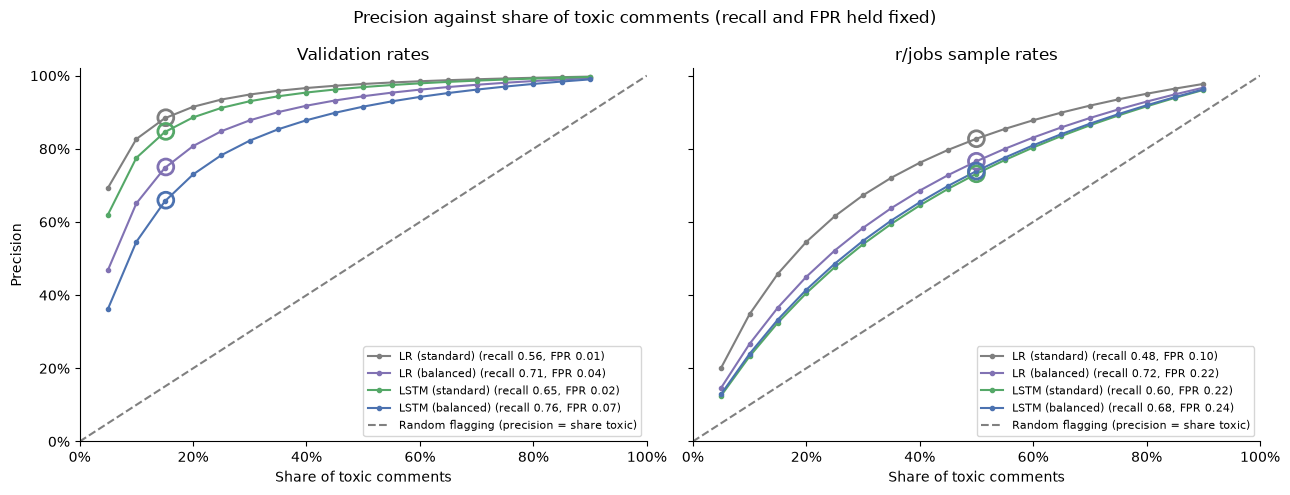

In [ ]:
def precision_by_share(tp0, fn0, fp0, tn0, shares):
    precision = []
    for share in shares:
        scale = share / (1 - share) * (tn0 + fp0) / (tp0 + fn0)  # factor that gives this toxic share while TN and FP stay fixed
        precision.append(tp0 * scale / (tp0 * scale + fp0))
    return np.array(precision)

shares = np.arange(0.05, 0.90 + 1e-9, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (title, results) in zip(axes, [('Validation rates', val_results), ('r/jobs sample rates', reddit_results)]):
    for name in model_names:
        r = results.loc[name]
        tp, fn, fp, tn = (float(r[k]) for k in ('TP', 'FN', 'FP', 'TN'))
        ax.plot(shares, precision_by_share(tp, fn, fp, tn, shares), 'o-', color=model_colors[name], markersize=3,
                label=f'{name} (recall {tp / (tp + fn):.2f}, FPR {fp / (fp + tn):.2f})')
        ax.scatter([(tp + fn) / (tp + fn + fp + tn)], [tp / (tp + fp)], s=130, facecolors='none', edgecolors=model_colors[name], linewidths=2, zorder=3)
    ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random flagging (precision = share toxic)')
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Share of toxic comments', title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('Precision')
fig.suptitle('Precision against share of toxic comments (recall and FPR held fixed)')
plt.tight_layout(); plt.show()

### A moderation queue at 5% toxic
If 5% of incoming comments were toxic, a model run at 0.5 would send this share of all comments to human review (`queue share`), with this precision, and catch this share of the toxic ones. The second table raises the cut-off to 0.9 and gives the precision and recall each model would have on the validation split and on r/jobs.

In [ ]:
TRIAGE_SHARE = 0.05
print(f'Moderation queue when {TRIAGE_SHARE:.0%} of comments are toxic (rates measured at the 0.5 threshold)')
display(triage_table(val_results, reddit_results, TRIAGE_SHARE).round(3))
reddit_cutoffs = cutoff_table(y_reddit, reddit_proba)
at_09 = pd.concat({'validation': val_cutoffs[val_cutoffs.cutoff == 0.9].set_index('model')[['precision', 'recall', 'flagged_share']],
                   'r/jobs sample': reddit_cutoffs[reddit_cutoffs.cutoff == 0.9].set_index('model')[['precision', 'recall', 'flagged_share']]}, axis=1)
print('Cut-off 0.9')
display(at_09.round(3).loc[model_names])

Moderation queue when 5% of comments are toxic (rates measured at the 0.5 threshold)


validation                             r/jobs                         
                 precision queue share toxic caught precision queue share toxic caught
LR (standard)        0.693       0.040        0.560     0.202       0.119         0.48
LR (balanced)        0.469       0.076        0.709     0.147       0.245         0.72
LSTM (standard)      0.620       0.052        0.649     0.126       0.239         0.60
LSTM (balanced)      0.363       0.105        0.763     0.130       0.262         0.68

Cut-off 0.9


validation                      r/jobs sample                     
                 precision recall flagged_share     precision recall flagged_share
model                                                                             
LR (standard)        0.960  0.366         0.058         0.889   0.16          0.09
LR (balanced)        0.929  0.523         0.085         0.821   0.46          0.28
LSTM (standard)      0.955  0.466         0.074         0.750   0.30          0.20
LSTM (balanced)      0.849  0.631         0.113         0.725   0.58          0.40

## B10. Cost of running the models (slide 33)
File size and number of parameters of each saved model, and the time to score 2,000 validation comments on this machine's CPU (best of three runs; the Bi-LSTM time includes tokenizing). Timings depend on the machine and are not comparable with other computers.

In [ ]:
sample = list(val_df['text'])[:2000]
cost = {}
for name in model_names:
    if name in logreg:
        file = baseline_dir / ('tfidf_logreg.joblib' if name == 'LR (standard)' else 'tfidf_logreg_balanced.joblib')
        n_params = int(logreg[name].named_steps['logisticregression'].coef_.size + 1)
        seconds = time_call(lambda n=name: logreg[n].predict_proba(sample))
    else:
        file = MODEL_DIR / LSTM_RUNS[name]['folder'] / 'best_kfold' / 'final_model.keras'
        n_params = int(lstm[name].final_model.count_params())
        seconds = time_call(lambda n=name: lstm[n].final_model.predict(encode(sample), verbose=0))
    cost[name] = {'file size (MB)': file.stat().st_size / 1e6, 'parameters': n_params, 'seconds per 2,000 comments': seconds}
cost = pd.DataFrame(cost).T
display(cost.round({'file size (MB)': 2, 'seconds per 2,000 comments': 3}).astype({'parameters': int}))

,file size (MB),parameters,"seconds per 2,000 comments"
LR (standard),2.36,50001,0.082
LR (balanced),2.00,43938,0.043
LSTM (standard),25.03,1009879,0.252
LSTM (balanced),25.74,1185901,0.513


## B11. Summary (slide 34)
One table with the measures that matter for choosing a model: recall and FPR on both datasets (the two that do not depend on the share of toxic comments), PR-AUC, the ratio of false alarms on r/jobs to false alarms on validation, and the size on disk.

In [ ]:
verdict = pd.DataFrame({
    'recall (val)': val_results['recall (TPR)'], 'FPR (val)': val_results['FPR'], 'PR-AUC (val)': val_results['pr_auc'],
    'recall (r/jobs)': reddit_results['recall (TPR)'], 'FPR (r/jobs)': reddit_results['FPR'], 'PR-AUC (r/jobs)': reddit_results['pr_auc'],
    'FPR ratio': transfer_summary(val_results, reddit_results)['fpr_ratio'], 'file size (MB)': cost['file size (MB)'],
}).astype(float)
display(verdict.round(3))
print('Hold-out sets are small (about 730 toxic validation comments, 50 toxic r/jobs comments): differences of a few points are within noise.')

,recall (val),FPR (val),PR-AUC (val),recall (r/jobs),FPR (r/jobs),PR-AUC (r/jobs),FPR ratio,file size (MB)
LR (standard),0.560,0.013,0.781,0.48,0.10,0.799,7.675,2.358
LR (balanced),0.709,0.042,0.806,0.72,0.22,0.801,5.203,2.000
LSTM (standard),0.649,0.021,0.819,0.60,0.22,0.785,10.529,25.034
LSTM (balanced),0.763,0.071,0.810,0.68,0.24,0.763,3.402,25.738


Hold-out sets are small (about 730 toxic validation comments, 50 toxic r/jobs comments): differences of a few points are within noise.


# Appendix

## Where each slide's numbers come from

| Slides | Content | Section of this notebook |
|---|---|---|
| 9, 11 | Topic corpus, 9,770 clustered, exclusions, monthly quotas | A1, A2 (corpus and TF-IDF cells) |
| 12 | K-means settings, PCA variance (50 / 100 / 200 / 400 components), k choice, initialisation stability | A2 |
| 13 | Cluster sizes, mixed clusters C7 and C12 (42.40%), silhouettes, names and evidence | A2 |
| 14, 15 | Six topics by month, Q1 to Q3 change, C2 / (C8 + C11) ratio, robustness checks | A3 |
| 17-22 | LDA: one comment with several topics, coherence by K, topic composition, K-means against LDA, quarterly shifts, popular-post and seed sensitivity | A4 |
| 23 | Layoff mentions against layoffs.fyi | A5 |
| 24 | Topic takeaways (A3, A4, A5 combined) | A3-A5, checked in A6 |
| 26, 27 | Setup, data, tuning protocol, selected models | B1-B4 |
| 28 | Validation and r/jobs metrics, matrices, curves, bootstrap intervals | B5-B7 |
| 30, 31 | Why performance drops on r/jobs: length, ROC-AUC, FPR ratio, profanity, long comments | B8 |
| 32 | Triage: precision at 5% toxic, queue share, cut-off 0.9 | B9 |
| 33 | Model size, parameters, scoring speed, bootstrap comparison | B10, B7 |
| 34 | Summary of the comparison | B11 |

## What this notebook does not reproduce
- **Training time.** Slide 33 compares training times of the logistic regression and the Bi-LSTM. Fit time differs from machine to machine, so the notebook does not measure it, with or without `RETRAIN`. File size, parameter count and scoring time (B10) are measured.
- **Data collection and pooling.** The pooled training and validation splits and the r/jobs test sample are read as shared files. The scripts that built them (`scripts/run_part3.py`, `scripts/collect_reddit.py`, `scripts/collect_monthly_topics.py`) stay in the repository and are not part of this run.
- **The LDA model.** The LDA numbers come from the shipped exports. A refit of LDA with the same settings gives different topics (see `models/topics_lda/manifest.json`), so the model file is for inspection and the retrain path only.

## Limits to keep in mind
- The r/jobs test set is 100 comments labelled by one annotator, keyword-enriched and balanced 50/50. It does not estimate real toxicity rates, and differences of a few points between models are within noise (B7).
- Topic names are suggestions from a documented review; topic ids apply only to the model they were assigned on. Quarterly changes describe this sample, not r/jobs as a whole, and are not causal.
- October 2026 is a partial month and is left out of the quarterly comparisons.

## Files written by this run
`outputs/` holds the regenerated LDA and layoff tables and figures. With `RETRAIN = True`, `models_retrained/` holds the refitted models. Nothing is written into `dataset/` or `models/`.